# 🎗️ Breast Cancer Diagnosis — Full Pipeline (v3 · Q1-journal-ready + redesigned Streamlit app)

**Dataset:** Breast Cancer Wisconsin (Diagnostic) — 569 samples × 30 features. These are **numeric features computed from digitized fine-needle-aspirate (FNA) images** (cell-nuclei measurements). The models here are **tabular models, not image models** — state this clearly in the manuscript.

### 🗺️ Pipeline
Setup → Dataset → Duplicate/Missing → Label Encoder → Imbalance check → Split 70/15/15 (stratified) → Standardize (train-fit) → SMOTE (train only) → Feature Selection (RFE · RF · EN bootstrap-stability) → Calibration/Coefficient/Stability figures → Hybrid-FS → Custom Residual-Gated MLP + baselines → Optuna → Federated Learning (FedAvg/FedProx, Non-IID, Personalized, LOCO, XAI) → Counterfactual (plausibility-constrained) → Uncertainty + CV-chosen calibration → **CV Ablation (all tuning in-fold)** → **Nested CV + Significance + Non-inferiority** → Risk scoring → **DCA/Calibration on out-of-fold predictions** → Streamlit app → Final summary + claims check

### ✅ v2 changes (what was fixed vs v4)
| # | Problem in v4 | Fix in v2 |
|---|---|---|
| 1 | Ablation used `HP_BEST`/`params_1se` tuned on data that later sat in test folds | MLP HPs **and** Elastic-Net params are tuned **inside every ablation fold** |
| 2 | "Sparse" EN (1-SE) was identical to CV-best (19/30 features) | Finer C-grid; 1-SE rule now picks the **fewest non-zero coefficients** within 1 SE; honest print if data is simply dense |
| 3 | Federated vs centralized importance compared different models on different data | Same FL model, same held-out test data: federated-aggregate vs pooled, and FL vs centralized model, with bootstrap CI |
| 4 | Counterfactuals changed ~13/16 features, unconstrained | Correlated features move **as groups**, values clipped to the training range; before/after table incl. plausibility |
| 5 | Personalization = global (no effect, unexplained) | Candidate set incl. local temperature scaling & head-only/proximal fine-tuning, margin rule, honest per-client choice |
| 6 | Platt scaling worsened Brier; probabilities saturated | Calibrator (raw / temperature / Platt) chosen by **cross-validation on the validation set**; ECE reported |
| 7 | Headline claims came from n=86 hold-out | DCA, calibration and claims are based on **out-of-fold predictions (n=569)**; hold-out is secondary |
| 8 | Unpenalized GLM = straw-man baseline | Separation diagnostic; comparisons made against the **strongest tuned baseline** + non-inferiority test |
| 9 | Streamlit app was a bare demo | New layout: patient form (left) · AI suggestion, draft Rx, PDF/JSON download, archive (right) · disclaimer box |

### 🎨 v3 changes (app redesign — the ML pipeline is unchanged)
| # | v2 | v3 |
|---|---|---|
| 1 | Default Streamlit look, emoji-heavy | Professional medical UI: navy header bar, blue/teal accents, card layout, light theme forced via `.streamlit/config.toml` |
| 2 | Patient form and results looked alike | **Left:** *Patient information* card (name · NID · passport · age · country code + mobile · doctor) and FNA inputs. **Right:** *Suggestion Prescription* with **Download** options + **Add to archive** at the top |
| 3 | Rx was a plain text box | Prescription card (patient/doctor header, large **Rx**, editable draft) followed by a separate **Suggestion report** card (specialist, drivers chart, counterfactual) |
| 4 | Long red disclaimer paragraph | One small box at the bottom — *“This is AI … not for clinical use”* — with the full notice in an expander |
| 5 | PDF report was plain | PDF has a navy header band, coloured section bars and risk-band colour |

> ▶️ `Runtime → Run all`. To change speed edit `B_BOOT`, `N_TRIALS`, `CV_REPEATS`, `NESTED_MLP_TRIALS`, `ABL_TRIALS` in the Config cell.
> ⚠️ Research prototype. Not a medical device. Never use for real clinical decisions.

## 🔧 ধাপ ১: Setup — লাইব্রেরি ইনস্টল, Drive mount, Config
এখানে সব দরকারি library install ও import হবে এবং পুরো notebook-এর সব সেটিং (path, seed, hyperparameter) এক জায়গায় থাকবে।

In [1]:
# ======== Run once in Colab: libraries that Colab does not ship ========
!pip install -q imbalanced-learn optuna shap streamlit fpdf2 matplotlib-venn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.8/88.8 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 43.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 341.3/341.3 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 40.9 MB/s eta 0:00:00


In [2]:
# ---------- standard imports ----------
import os, glob, zipfile, random, warnings, json, copy, time, shutil, sys
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning,ignore:Inconsistent values:UserWarning"   # joblib workers inherit this
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# v2: only silence noisy deprecation notices. Convergence / user warnings stay visible on purpose.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*penalty.*")                 # sklearn ≥1.8 'penalty' deprecation notices (harmless)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("once", category=ConvergenceWarning)             # convergence problems stay visible (once)

# ---------- Google Drive mount (Colab হলে) ----------
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("⚠️ Colab নয়, লোকাল মোডে চলছে")

# ---------- paths ----------
# NOTE: folder name below is kept exactly as it is on your Drive ("Brest_Cancer(CSV_data)").
# If the ZIP is not found, the notebook automatically falls back to scikit-learn's identical WDBC copy.
DRIVE_DIR = "/content/drive/MyDrive/Brest_Cancer(CSV_data)"
ZIP_PATH = os.path.join(DRIVE_DIR, "archive (1).zip")
OUT_DIR = os.path.join(DRIVE_DIR, "outputs_v2") if IN_COLAB else "outputs_v2"
RAW_DIR = "/content/bc_raw" if IN_COLAB else "bc_raw"
DEPLOY_DIR = "deploy_app"

# ---------- Config (সব সেটিং এখানে) ----------
SEED = 42
K_FS = 15              # RFE / RF top-K
STAB_THR = 0.70        # stability threshold (pi*)
B_BOOT = 1000          # bootstrap সংখ্যা (paper-এর মতো 1000)
N_TRIALS = 25          # Optuna trial
EPOCHS_MAX = 150
PATIENCE = 15
N_CLIENTS = 4
ALPHA_NONIID = 0.5
FL_ROUNDS = 30
LOCAL_EPOCHS = 2
LOCO_ROUNDS = 20
MC_T = 50
CV_REPEATS = 3         # Nested CV outer repeat (5-fold × CV_REPEATS)
ABL_REPEATS = 2        # Ablation CV repeat (5-fold × ABL_REPEATS)
ABL_TRIALS = 6         # v2: Optuna trials PER ABLATION FOLD (HP tuned in-fold)
ABL_BOOT = 40          # v2: bootstrap count for in-fold EN stability
NESTED_MLP_TRIALS = 8  # প্রতি outer fold-এ Optuna trial (Custom MLP)
N_BOOT_CI = 1000
XAI_BOOT = 100         # v2: bootstrap reps for explanation-agreement CI
NI_MARGIN = 0.01       # v2: non-inferiority margin (1 percentage point of accuracy)

# দ্রুত smoke-test মোড (শুধু কোড চলছে কিনা দেখতে): env BC_FAST=1
FAST = os.environ.get("BC_FAST") == "1"
if FAST:
    B_BOOT, N_TRIALS, EPOCHS_MAX = 100, 4, 30
    FL_ROUNDS, LOCO_ROUNDS, MC_T = 4, 3, 10
    CV_REPEATS, ABL_REPEATS, NESTED_MLP_TRIALS, N_BOOT_CI = 1, 1, 2, 100
    ABL_TRIALS, ABL_BOOT, XAI_BOOT = 2, 10, 12
    print("⚡ FAST smoke-test মোড চালু — ফলাফল paper-এ ব্যবহার করবেন না")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(RAW_DIR, exist_ok=True)

def savefig(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=300, bbox_inches="tight")

import sklearn, scipy
print("✅ Setup সম্পন্ন | Colab:", IN_COLAB, "| FAST:", FAST)
print("versions → numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| scipy", scipy.__version__)

Mounted at /content/drive
✅ Setup সম্পন্ন | Colab: True | FAST: False
versions → numpy 2.1.3 | pandas 2.2.3 | sklearn 1.6.1 | scipy 1.16.3


## 📂 ধাপ ২: ZIP extract ও Dataset sample দেখা
ZIP থেকে CSV বের করে `df.shape`, প্রথম কয়েকটি row, data type ও summary দেখব।

In [3]:
# ---------- ZIP extract (Drive-এ ZIP থাকলে) / না থাকলে scikit-learn-এর একই WDBC copy ----------
if os.path.exists(ZIP_PATH):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RAW_DIR)
    csv_files = glob.glob(os.path.join(RAW_DIR, "**", "*.csv"), recursive=True)
    print("পাওয়া CSV:", csv_files)
    df = pd.read_csv(csv_files[0])
else:
    from sklearn.datasets import load_breast_cancer       # WDBC (569 × 30) — Kaggle ফাইলের সমান ডেটা
    bunch = load_breast_cancer()
    bases = ["radius", "texture", "perimeter", "area", "smoothness", "compactness", "concavity",
             "concave points", "symmetry", "fractal_dimension"]
    cols = [f"{b}_{s}" for s in ("mean", "se", "worst") for b in bases]
    df = pd.DataFrame(bunch.data, columns=cols)
    df.insert(0, "diagnosis", np.where(bunch.target == 0, "M", "B"))
    df.insert(0, "id", np.arange(len(df)))
    df["Unnamed: 32"] = np.nan
    print("ℹ️ ZIP পাওয়া যায়নি → scikit-learn-এর WDBC copy ব্যবহার হচ্ছে")

print("Dataset shape (df.shape):", df.shape)
display(df.head())
df.info()

পাওয়া CSV: ['/content/bc_raw/data.csv']
Dataset shape (df.shape): (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

## 🔁 ধাপ ৩: Duplicate Value Check
`id` প্রতিটি রোগীর জন্য আলাদা, তাই শুধু `id` বাদ দিয়ে বাকি কলামে duplicate আছে কিনা দেখব। Duplicate থাকলে বাদ দেব, না হলে কিছু বদলাবে না।

In [4]:
id_col = "id" if "id" in df.columns else None                        # id কলাম আছে কিনা
cols_wo_id = [c for c in df.columns if c != id_col]                  # id বাদে বাকি কলাম
n_dup_full = int(df.duplicated().sum())                              # পুরো row duplicate সংখ্যা
n_dup_feat = int(df.duplicated(subset=cols_wo_id).sum())             # id বাদে duplicate সংখ্যা
print("পুরো row duplicate:", n_dup_full)                             # রিপোর্ট
print("id বাদে duplicate :", n_dup_feat)                             # রিপোর্ট

if n_dup_feat > 0:                                                   # duplicate থাকলে
    df = df.drop_duplicates(subset=cols_wo_id, keep="first").reset_index(drop=True)   # প্রথমটি রেখে বাকি বাদ
    print("✅ Duplicate বাদ দেওয়া হয়েছে | নতুন shape:", df.shape)
else:                                                                # না থাকলে
    print("✅ কোনো duplicate নেই")

পুরো row duplicate: 0
id বাদে duplicate : 0
✅ কোনো duplicate নেই


## 🕳️ ধাপ ৪: Missing Value Check (শুধু রিপোর্ট — Imputation split-এর পরে, ধাপ ৭ক-তে)
- সম্পূর্ণ ফাঁকা কলাম (যেমন Kaggle ফাইলের `Unnamed: 32`) ও `id` বাদ দেব (paper-এর মতো)।
- এখানে শুধু **কতটা missing আছে** তা গুনব। **KNN Imputation এখানে করা হয় না** — split-এর আগে করলে test/val-এর তথ্য imputer-এ ঢুকে data leakage হয়। তাই imputer **শুধু train-এ fit** হবে (ধাপ ৭ক)।
- 📝 WDBC dataset-এ কোনো missing মান নেই, তবে pipeline **missing-safe** (missing থাকলে leakage ছাড়াই পূরণ হবে)।

In [5]:
target_col = "diagnosis"                                             # টার্গেট কলামের নাম
junk_cols = [c for c in df.columns if df[c].isna().all()]            # সম্পূর্ণ ফাঁকা কলাম
drop_cols = junk_cols + ([id_col] if id_col else [])                 # বাদ দেওয়ার তালিকা
print("বাদ দেওয়া কলাম:", drop_cols)                                # রিপোর্ট
df = df.drop(columns=drop_cols)                                      # কলাম বাদ
df = df.dropna(subset=[target_col]).reset_index(drop=True)           # টার্গেট ফাঁকা সারি বাদ

miss = df.isna().sum()                                               # প্রতি কলামে missing সংখ্যা
total_missing = int(miss.sum())                                      # মোট missing
print("মোট missing মান:", total_missing)                            # রিপোর্ট
if total_missing > 0:
    print(miss[miss > 0])                                            # কোন কলামে কতগুলো

বাদ দেওয়া কলাম: ['Unnamed: 32', 'id']
মোট missing মান: 0


In [6]:
from sklearn.impute import KNNImputer                                # KNN Imputer (ধাপ ৭ক-তে ব্যবহার হবে)
from sklearn.preprocessing import StandardScaler                     # স্কেলার

num_cols = [c for c in df.columns if c != target_col and pd.api.types.is_numeric_dtype(df[c])]   # numeric ফিচার কলাম

# ⚠️ Leakage এড়াতে এখানে imputation করা হয় না। split-এর পরে train-এ fit করে val/test-এ transform হবে (ধাপ ৭ক)।
print("মোট missing মান (শুধু রিপোর্ট):", total_missing)
print("ℹ️ KNN Imputation → ধাপ ৭ক-তে (train-এ fit, val/test-এ transform)")

মোট missing মান (শুধু রিপোর্ট): 0
ℹ️ KNN Imputation → ধাপ ৭ক-তে (train-এ fit, val/test-এ transform)


## 🏷️ ধাপ ৫: Categorical Variable → Label Encoder
`diagnosis` (B / M) একটি categorical কলাম। `LabelEncoder` বর্ণানুক্রমে encode করে, তাই **B = 0 (benign), M = 1 (malignant)** — paper-এর সংজ্ঞার সাথে হুবহু মেলে।

In [7]:
from sklearn.preprocessing import LabelEncoder                       # Label Encoder

cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()   # categorical কলাম খোঁজা
encoders = {}                                                        # encoder সংরক্ষণ
for c in cat_cols:                                                   # প্রতিটি categorical কলামের জন্য
    if df[c].isna().any():                                           # missing থাকলে
        df[c] = df[c].fillna(df[c].mode()[0])                        # mode দিয়ে পূরণ
    le = LabelEncoder()                                              # নতুন encoder
    df[c] = le.fit_transform(df[c].astype(str))                      # encode
    encoders[c] = le                                                 # সংরক্ষণ
    print(c, "→", {k: int(v) for k, v in zip(le.classes_, le.transform(le.classes_))}) # mapping দেখানো

print("Encode-এর পর dtype:\n", df[target_col].dtype)                 # যাচাই
print("ℹ️ শুধু target (B/M) encode হয়; এটি data-র distribution থেকে কিছু শেখে না, তাই leakage নেই")

diagnosis → {'B': 0, 'M': 1}
Encode-এর পর dtype:
 int64
ℹ️ শুধু target (B/M) encode হয়; এটি data-র distribution থেকে কিছু শেখে না, তাই leakage নেই


## ⚖️ ধাপ ৬: Target Variable — Balanced না Imbalanced?
প্রতিটি class-এর সংখ্যা ও শতাংশ দেখে সিদ্ধান্ত নেব। (সাধারণ নিয়ম: minority class < 40% হলে imbalanced ধরা হয়।)

           count  percent
diagnosis                
0            357    62.74
1            212    37.26
Imbalance ratio = 1.68 | Minority = 37.26%
⚠️ Dataset IMBALANCED (mild) → SMOTE বনাম No-SMOTE দুটোই তুলনা করা হবে (ablation ও calibration-এ)


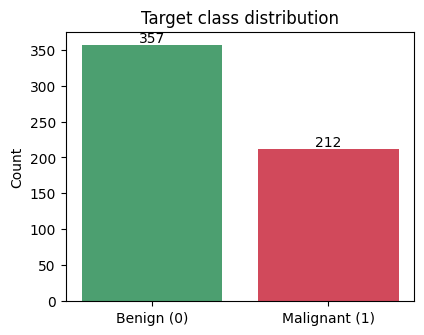

In [8]:
counts = df[target_col].value_counts().sort_index()                  # class অনুযায়ী গণনা
perc = (counts / counts.sum() * 100).round(2)                        # শতাংশ
print(pd.DataFrame({"count": counts, "percent": perc}))              # টেবিল
imb_ratio = counts.max() / counts.min()                              # imbalance ratio
minority_pct = perc.min()                                            # minority শতাংশ
print(f"Imbalance ratio = {imb_ratio:.2f} | Minority = {minority_pct}%")
if minority_pct < 40:                                                # সিদ্ধান্ত
    print("⚠️ Dataset IMBALANCED (mild) → SMOTE বনাম No-SMOTE দুটোই তুলনা করা হবে (ablation ও calibration-এ)")
else:
    print("✅ Dataset প্রায় BALANCED")

plt.figure(figsize=(4.5, 3.5))                                       # প্লট
plt.bar(["Benign (0)", "Malignant (1)"], counts.values, color=["#4C9F70", "#D1495B"])   # বার চার্ট
for i, v in enumerate(counts.values):                                # বারের উপর সংখ্যা
    plt.text(i, v + 3, str(v), ha="center")
plt.title("Target class distribution"); plt.ylabel("Count")          # শিরোনাম
savefig("01_class_distribution.png"); plt.show()                     # সেভ ও দেখানো

## ✂️ ধাপ ৭: Dataset Split (70 / 15 / 15) ও Standardization
- প্রথমে **70% Train**, বাকি 30% থেকে **15% Validation + 15% Test** (সবই stratified)।
- Standardization-এর mean/std **শুধু train** থেকে শেখা হবে (paper-এর মতো), যাতে data leakage না হয়।

In [9]:
from sklearn.model_selection import train_test_split                 # split function

X = df.drop(columns=[target_col])                                    # ফিচার
y = df[target_col].astype(int).values                                # টার্গেট (0/1)
feat_names = X.columns.tolist()                                      # ফিচারের নাম
print("ফিচার সংখ্যা:", len(feat_names))

# ৭০% train, ৩০% temp
X_train_raw, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
# temp-কে অর্ধেক করে ১৫% val ও ১৫% test
X_val_raw, X_test_raw, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

for name, yy in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:   # প্রতিটি অংশের রিপোর্ট
    print(f"{name:5s}: n={len(yy):4d} | malignant={yy.mean()*100:.1f}%")

ফিচার সংখ্যা: 30
Train: n= 398 | malignant=37.2%
Val  : n=  85 | malignant=37.6%
Test : n=  86 | malignant=37.2%


## 🧩 ধাপ ৭ক: Missing-Safe Imputation (split-এর পরে, শুধু Train-এ fit)
- KNN Imputer (k=5) **শুধু train** থেকে শেখে, তারপর val ও test-এ শুধু `transform` হয় → test/val-এর তথ্য train-এ ঢোকে না।
- দূরত্ব ঠিক রাখতে imputation-এর আগে train-এর mean/std দিয়ে স্কেল করা হয়, পরে আগের এককে ফেরানো হয়।
- 📝 WDBC-তে missing নেই, তাই এই ধাপে সাধারণত কিছু বদলায় না। তবু **pipeline missing-safe**: অন্য dataset-এ missing থাকলেও leakage ছাড়া কাজ করবে।

In [10]:
# ---------- Missing-safe imputation: train-এ fit → val/test-এ transform ----------
n_miss = {nm: int(d.isna().sum().sum()) for nm, d in [("train", X_train_raw), ("val", X_val_raw), ("test", X_test_raw)]}
print("Split-এর পর missing মান:", n_miss)
if sum(n_miss.values()) > 0:                                         # missing থাকলেই চলবে
    imp_scaler = StandardScaler().fit(X_train_raw)                   # শুধু train থেকে mean/std (NaN উপেক্ষা করে)
    knn_imp = KNNImputer(n_neighbors=5).fit(imp_scaler.transform(X_train_raw))   # শুধু train-এ fit
    def impute_df(Xraw):                                             # transform-only helper
        arr = knn_imp.transform(imp_scaler.transform(Xraw))
        return pd.DataFrame(imp_scaler.inverse_transform(arr), columns=feat_names, index=Xraw.index)
    X_train_raw, X_val_raw, X_test_raw = impute_df(X_train_raw), impute_df(X_val_raw), impute_df(X_test_raw)
    print("✅ KNN Imputation সম্পন্ন (train-এ fit) | বাকি missing:",
          int(X_train_raw.isna().sum().sum() + X_val_raw.isna().sum().sum() + X_test_raw.isna().sum().sum()))
else:
    print("✅ Missing নেই (WDBC), তাই imputation দরকার নেই — pipeline missing-safe")

Split-এর পর missing মান: {'train': 0, 'val': 0, 'test': 0}
✅ Missing নেই (WDBC), তাই imputation দরকার নেই — pipeline missing-safe


In [11]:
# ---------- Standardization (শুধু train থেকে fit) ----------
scaler_all = StandardScaler().fit(X_train_raw)                       # train থেকে mean/std শেখা
def scale_df(Xraw):                                                  # স্কেল করার helper
    return pd.DataFrame(scaler_all.transform(Xraw), columns=feat_names, index=Xraw.index)

X_train_s = scale_df(X_train_raw)                                    # train স্কেল
X_val_s = scale_df(X_val_raw)                                        # val স্কেল (train-এর প্যারামিটারে)
X_test_s = scale_df(X_test_raw)                                      # test স্কেল (train-এর প্যারামিটারে)
print("Train mean≈0 যাচাই:", np.round(X_train_s.mean().abs().max(), 6))

Train mean≈0 যাচাই: 0.0


## 🧬 ধাপ ৮: SMOTE — শুধু Training Data-তে
Validation ও Test-এ **কখনো** SMOTE করা হবে না (নাহলে ফলাফল মিথ্যা ভালো দেখাবে)।

SMOTE-এর আগে : {1: 148, 0: 250}
SMOTE-এর পরে : {1: 250, 0: 250}


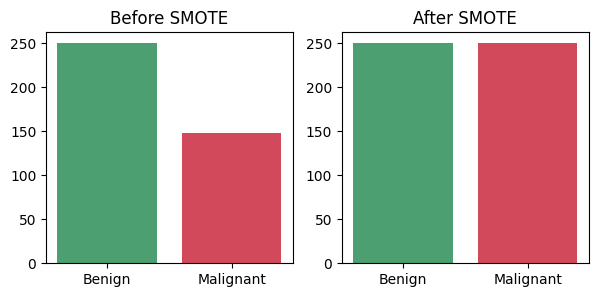

In [12]:
from imblearn.over_sampling import SMOTE                             # SMOTE

smote = SMOTE(random_state=SEED, k_neighbors=5)                      # SMOTE অবজেক্ট
Xb, yb = smote.fit_resample(X_train_s, y_train)                      # শুধু train balance
X_train_bal = pd.DataFrame(Xb, columns=feat_names)                   # DataFrame আকারে
y_train_bal = np.asarray(yb).astype(int)                             # numpy array

print("SMOTE-এর আগে :", {int(k): v for k, v in Counter(y_train).items()})                     # আগের সংখ্যা
print("SMOTE-এর পরে :", {int(k): v for k, v in Counter(y_train_bal).items()})                 # পরের সংখ্যা

fig, ax = plt.subplots(1, 2, figsize=(7, 3))                         # আগে-পরে তুলনা
for a, (t, yy) in zip(ax, [("Before SMOTE", y_train), ("After SMOTE", y_train_bal)]):
    cc = np.bincount(yy)                                             # গণনা
    a.bar(["Benign", "Malignant"], cc, color=["#4C9F70", "#D1495B"]) # বার
    a.set_title(t)
savefig("02_smote_before_after.png"); plt.show()

## 🎯 ধাপ ৯: Feature Selection (FS)
তিনটি পদ্ধতি চলবে (সবই SMOTE-করা **train** data-তে):
1. **RFE** (Recursive Feature Elimination, Logistic Regression দিয়ে)
2. **Random Forest importance**
3. **Paper-এর পদ্ধতি:** Ridge / Lasso / Elastic-Net-এর hyperparameter tuning + **bootstrap selection frequency** (π* = 0.70)

RFE নির্বাচিত (15): ['area_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'radius_se', 'perimeter_se', 'area_se', 'compactness_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'concave points_worst', 'symmetry_worst']

RF top-15: ['perimeter_worst', 'area_worst', 'concave points_mean', 'radius_worst', 'concave points_worst', 'perimeter_mean', 'radius_mean', 'concavity_mean', 'area_mean', 'concavity_worst', 'area_se', 'texture_worst', 'compactness_mean', 'radius_se', 'symmetry_worst']


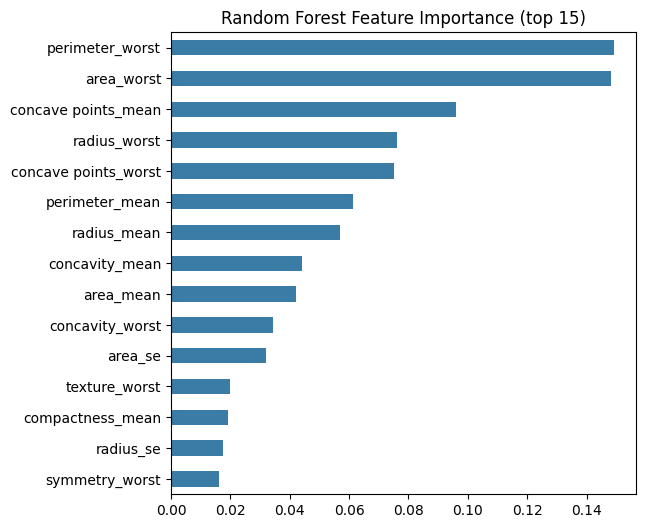

In [13]:
from sklearn.feature_selection import RFE                            # RFE
from sklearn.linear_model import LogisticRegression                  # Logistic Regression
from sklearn.ensemble import RandomForestClassifier                  # Random Forest

# ---------- (১) RFE ----------
rfe = RFE(LogisticRegression(max_iter=5000), n_features_to_select=K_FS, step=1)   # K_FS টি ফিচার রাখবে
rfe.fit(X_train_bal, y_train_bal)                                    # train-এ fit
sel_rfe = [f for f, s in zip(feat_names, rfe.support_) if s]         # নির্বাচিত ফিচার
print(f"RFE নির্বাচিত ({len(sel_rfe)}):", sel_rfe)

# ---------- (২) Random Forest importance ----------
rf_fs = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)   # RF
rf_fs.fit(X_train_bal, y_train_bal)                                  # fit
rf_imp = pd.Series(rf_fs.feature_importances_, index=feat_names).sort_values(ascending=False)   # importance
sel_rf = rf_imp.index[:K_FS].tolist()                                # top-K
print(f"\nRF top-{K_FS}:", sel_rf)

plt.figure(figsize=(6, 6))                                           # RF importance প্লট
rf_imp.head(15)[::-1].plot(kind="barh", color="#3A7CA5")             # উপরের ১৫টি
plt.title("Random Forest Feature Importance (top 15)")
savefig("03_rf_importance.png"); plt.show()

### 📄 Paper-এর অংশ: Ridge / Lasso / Elastic-Net (CV tuning + Bootstrap Stability) — v2
- `λ` (এখানে `C = 1/λ`) ও `l1_ratio` cross-validation দিয়ে বাছাই — **scaler + SMOTE প্রতি CV fold-এর ভেতরে**।
- **v2 – 1-SE rule (sparsity):** CV-best-এর ১ standard error-এর মধ্যে যে কনফিগে **সবচেয়ে কম non-zero coefficient**, সেটি বাছাই (আগে শুধু বড় `C` দেখা হতো; ডেটা dense হওয়ায় ফল CV-best-এর সমান আসত)। যদি তবুও CV-best-এর সমান আসে, notebook সেটা খোলাখুলি print করে — তার মানে ডেটা নিজেই dense, "sparse" দাবি করা যাবে না।
- Bootstrap stability: **মূল (un-SMOTEd) train**-এ resample, **প্রতি bootstrap-এর ভেতরে SMOTE**; π̂ⱼ ≥ 0.70 হলে feature stable।
- **Ridge** coefficient কখনো ঠিক শূন্য করে না ⇒ selection frequency ≡ 1 (গঠনগত) ⇒ Ridge stability-selection থেকে বাদ।
- **GLM (unpenalized)** শুধু reference; separation হলে coefficient বিশাল হয় — নিচে diagnostic আছে। তুলনা করুন শক্তিশালী tuned baseline-এর সাথে।

In [14]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, brier_score_loss, confusion_matrix, roc_curve, log_loss)
from imblearn.pipeline import Pipeline as ImbPipeline
from joblib import Parallel, delayed
from scipy import stats

def make_lr(kind, C=1.0, l1_ratio=0.5):
    if kind == "glm":
        return LogisticRegression(penalty=None, max_iter=5000)
    if kind == "ridge":
        return LogisticRegression(penalty="l2", C=C, solver="lbfgs", max_iter=5000)
    if kind == "lasso":
        return LogisticRegression(penalty="l1", C=C, solver="liblinear", max_iter=5000)
    if kind == "enet":
        return LogisticRegression(penalty="elasticnet", solver="saga", C=C, l1_ratio=l1_ratio, max_iter=5000, tol=1e-4)

def n_nonzero(m):
    return int((np.abs(m.coef_.ravel()) > 1e-8).sum())

def tune_lr(kind, X_raw, y_raw, X_fit, y_fit, one_se=False, n_C=13):
    """Tuning: scaler + SMOTE FIT INSIDE every CV fold (no leakage), on the ORIGINAL (un-SMOTEd) data (X_raw, y_raw).
    Final model is fitted on (X_fit, y_fit) = SMOTE-balanced, standardized data.
    one_se=True -> among configs within 1 SE of the CV-best, pick the one with the FEWEST non-zero coefficients
    (tie-break: smaller C, then larger l1_ratio)."""
    if kind == "glm":
        return make_lr("glm").fit(X_fit, y_fit), {}
    pipe = ImbPipeline([("sc", StandardScaler()), ("smote", SMOTE(random_state=SEED)), ("clf", make_lr(kind))])
    grid = {"clf__C": np.logspace(-2, 1 if kind == "enet" else 2, n_C)}   # saga converges poorly at very weak penalty → enet C ≤ 10
    if kind == "enet":
        grid["clf__l1_ratio"] = [0.3, 0.6, 0.9]
    gs = GridSearchCV(pipe, grid, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="neg_log_loss", n_jobs=-1)
    gs.fit(np.asarray(X_raw), np.asarray(y_raw))
    if one_se:
        res = pd.DataFrame(gs.cv_results_)
        best = res.loc[res.rank_test_score == 1].iloc[0]
        se = best.std_test_score / np.sqrt(5)
        ok = res[res.mean_test_score >= best.mean_test_score - se]
        cands = []
        for _, row in ok.iterrows():
            prm = {"C": float(row["param_clf__C"])}
            if kind == "enet":
                prm["l1_ratio"] = float(row["param_clf__l1_ratio"])
            nnz = n_nonzero(make_lr(kind, **prm).fit(X_fit, y_fit))
            cands.append((nnz, prm["C"], -prm.get("l1_ratio", 0.0), prm))
        cands.sort(key=lambda t: t[:3])
        params = cands[0][3]
    else:
        params = {k.replace("clf__", ""): float(v) for k, v in gs.best_params_.items()}
    return make_lr(kind, **params).fit(X_fit, y_fit), params

def youden_threshold(y_true, prob):
    fpr, tpr, thr = roc_curve(y_true, prob)
    t = float(np.clip(thr[np.argmax(tpr - fpr)], 0, 1))
    return t if 0.02 < t < 0.98 else 0.5          # degenerate-threshold guard (e.g. perfectly separable unpenalized GLM)

def ece_score(y_true, prob, n_bins=10):
    """Expected calibration error (equal-width bins)."""
    y_true = np.asarray(y_true, dtype=float); prob = np.asarray(prob, dtype=float)
    bins = np.minimum((prob * n_bins).astype(int), n_bins - 1)
    e = 0.0
    for b in range(n_bins):
        m = bins == b
        if m.any():
            e += m.mean() * abs(y_true[m].mean() - prob[m].mean())
    return float(e)

def compute_metrics(y_true, prob, thr=0.5):
    y_true = np.asarray(y_true); prob = np.asarray(prob)
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(threshold=round(float(thr), 3),
                accuracy=accuracy_score(y_true, pred),
                precision=precision_score(y_true, pred, zero_division=0),
                sensitivity=recall_score(y_true, pred, zero_division=0),
                specificity=tn / (tn + fp) if (tn + fp) > 0 else np.nan,
                f1=f1_score(y_true, pred, zero_division=0),
                auc=roc_auc_score(y_true, prob) if len(np.unique(y_true)) > 1 else np.nan,
                brier=brier_score_loss(y_true, prob),
                ece=ece_score(y_true, prob),
                tp=int(tp), tn=int(tn), fp=int(fp), fn=int(fn))

# ---------- সব ৩০ ফিচারে ৪টি paper-মডেল ----------
Xtr_all, Xva_all, Xte_all = X_train_bal.values, X_val_s.values, X_test_s.values
Xtr_raw_all = X_train_raw.values
paper_models, paper_params, paper_rows = {}, {}, []
for kind, label in [("glm", "GLM"), ("ridge", "Ridge"), ("lasso", "Lasso"), ("enet", "Elastic-Net")]:
    mdl, bp = tune_lr(kind, Xtr_raw_all, y_train, Xtr_all, y_train_bal)
    paper_models[label], paper_params[kind] = mdl, bp
    thr = youden_threshold(y_val, mdl.predict_proba(Xva_all)[:, 1])
    paper_rows.append({"model": label, **compute_metrics(y_test, mdl.predict_proba(Xte_all)[:, 1], thr)})
    print(f"{label:12s} → best params (CV, SMOTE-in-fold): {bp} | non-zero coef: {n_nonzero(mdl)}/{Xtr_all.shape[1]}")

# v2: sparse (1-SE) config for the Hybrid-FS stability vote — now defined by FEWEST NON-ZERO coefficients
params_1se, NNZ_1SE = {}, {}
for kind, label in [("lasso", "Lasso"), ("enet", "Elastic-Net")]:
    m1, params_1se[kind] = tune_lr(kind, Xtr_raw_all, y_train, Xtr_all, y_train_bal, one_se=True)
    NNZ_1SE[kind] = (n_nonzero(m1), n_nonzero(paper_models[label]))          # (1-SE, CV-best)
    sparser = NNZ_1SE[kind][0] < NNZ_1SE[kind][1]
    print(f"{label:12s} 1-SE params: {params_1se[kind]} | non-zero {NNZ_1SE[kind][0]} (CV-best: {NNZ_1SE[kind][1]})"
          + ("  ✅ genuinely sparser than CV-best" if sparser else "  ⚠️ NOT sparser than CV-best (same #non-zero) → data is dense, do NOT claim a 'sparse' model"))

paper_table = pd.DataFrame(paper_rows).round(3)
print("\n📊 Paper-style Table 1 (সব ৩০ ফিচার, Youden threshold, hold-out test — সহায়ক ফলাফল):")
display(paper_table)

# v2: GLM (unpenalized) diagnostic — quasi-complete separation makes it a straw-man baseline
g_ = paper_models["GLM"]
print(f"\nGLM diagnostic: max|coef|={np.abs(g_.coef_).max():.1f} | L1-norm={np.abs(g_.coef_).sum():.0f} | train acc={g_.score(Xtr_all, y_train_bal):.3f}")
if np.abs(g_.coef_).max() > 30:
    print("⚠️ near-separation → unpenalized GLM is a WEAK reference. Compare improvements against Ridge/SVM (strongest tuned baseline), not GLM.")

GLM          → best params (CV, SMOTE-in-fold): {} | non-zero coef: 30/30
Ridge        → best params (CV, SMOTE-in-fold): {'C': 0.46415888336127775} | non-zero coef: 30/30
Lasso        → best params (CV, SMOTE-in-fold): {'C': 1.0} | non-zero coef: 17/30
Elastic-Net  → best params (CV, SMOTE-in-fold): {'C': 1.0, 'l1_ratio': 0.9} | non-zero coef: 20/30
Lasso        1-SE params: {'C': 0.46415888336127775} | non-zero 14 (CV-best: 17)  ✅ genuinely sparser than CV-best
Elastic-Net  1-SE params: {'C': 0.5623413251903491, 'l1_ratio': 0.9} | non-zero 20 (CV-best: 20)  ⚠️ NOT sparser than CV-best (same #non-zero) → data is dense, do NOT claim a 'sparse' model

📊 Paper-style Table 1 (সব ৩০ ফিচার, Youden threshold, hold-out test — সহায়ক ফলাফল):


,model,threshold,accuracy,precision,sensitivity,specificity,f1,auc,brier,ece,tp,tn,fp,fn
0,GLM,0.500,0.942,0.935,0.906,0.963,0.921,0.985,0.058,0.058,29,52,2,3
1,Ridge,0.447,0.988,0.970,1.000,0.981,0.985,0.999,0.013,0.035,32,53,1,0
2,Lasso,0.405,0.977,0.969,0.969,0.981,0.969,0.998,0.018,0.047,31,53,1,1
3,Elastic-Net,0.340,0.988,0.970,1.000,0.981,0.985,0.998,0.016,0.039,32,53,1,0



GLM diagnostic: max|coef|=211.8 | L1-norm=2796 | train acc=1.000
⚠️ near-separation → unpenalized GLM is a WEAK reference. Compare improvements against Ridge/SVM (strongest tuned baseline), not GLM.


Lasso: B=1000 bootstrap শেষ (8.1s)
Elastic-Net: B=1000 bootstrap শেষ (720.1s)
Elastic-Net (1-SE): B=1000 bootstrap শেষ (585.9s)

📊 Paper-style Table 2 (stable predictor sets; Ridge বাদ — selection frequency গঠনগতভাবে ≡ 1):


,model,n_stable,stable_features
0,Lasso,10,"concave points_mean, radius_se, texture_se, co..."
1,Elastic-Net,15,"concavity_mean, concave points_mean, radius_se..."
2,Elastic-Net (1-SE),11,"concave points_mean, radius_se, compactness_se..."


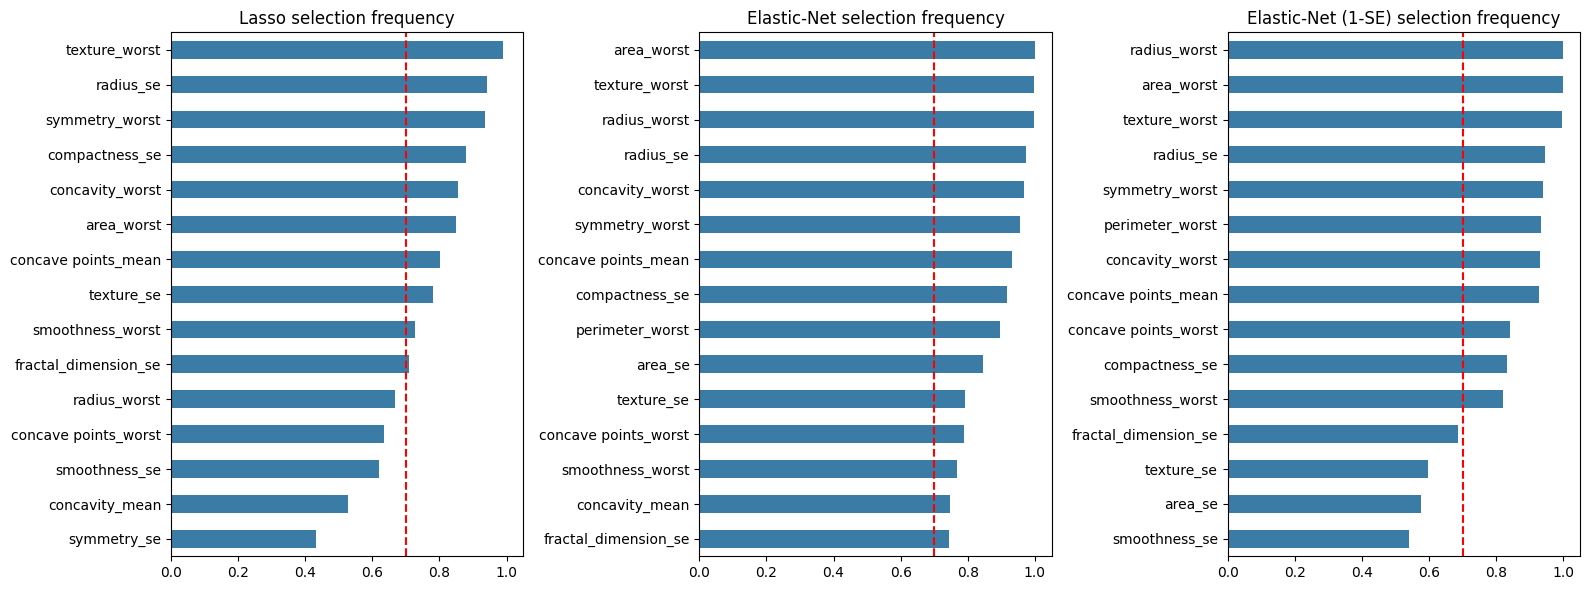

In [15]:
# ---------- Bootstrap Stability Selection (paper Eq. 7) — SMOTE প্রতি bootstrap-এর ভেতরে ----------
def _one_boot(kind, params, X, yv, seed):
    rng = np.random.RandomState(seed)
    for _ in range(50):                                            # দুই class-ই যথেষ্ট থাকা sample
        idx = rng.choice(len(X), len(X), replace=True)
        if np.bincount(yv[idx], minlength=2).min() >= 6:
            break
    Xb, yb = SMOTE(random_state=seed, k_neighbors=5).fit_resample(X[idx], yv[idx])   # SMOTE INSIDE bootstrap
    m = make_lr(kind, **params).fit(Xb, yb)
    return (np.abs(m.coef_.ravel()) > 1e-8).astype(int)

def selection_frequency(kind, params, X, yv, B):
    res = Parallel(n_jobs=-1)(delayed(_one_boot)(kind, params, X, yv, SEED + b) for b in range(B))
    return np.mean(res, axis=0)

X_stab, y_stab = X_train_s.values, y_train                         # মূল (un-SMOTEd) train
stab_cfg = [("Lasso", "lasso", paper_params["lasso"]),
            ("Elastic-Net", "enet", paper_params["enet"]),          # paper-style (CV-optimal)
            ("Elastic-Net (1-SE)", "enet", params_1se["enet"])]     # sparse — Hybrid-FS-এ ব্যবহৃত
freq = {}
for label, kind, prm in stab_cfg:
    t0 = time.time()
    freq[label] = pd.Series(selection_frequency(kind, prm, X_stab, y_stab, B_BOOT), index=feat_names)
    print(f"{label}: B={B_BOOT} bootstrap শেষ ({time.time()-t0:.1f}s)")

stable_sets = {k: v.index[v >= STAB_THR].tolist() for k, v in freq.items()}
table2 = pd.DataFrame({"model": list(stable_sets.keys()),
                       "n_stable": [len(v) for v in stable_sets.values()],
                       "stable_features": [", ".join(v) for v in stable_sets.values()]})
print("\n📊 Paper-style Table 2 (stable predictor sets; Ridge বাদ — selection frequency গঠনগতভাবে ≡ 1):")
display(table2)

fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=False)
for ax, (label, s) in zip(axes, freq.items()):
    s.sort_values().tail(15).plot(kind="barh", ax=ax, color="#3A7CA5")
    ax.axvline(STAB_THR, color="red", ls="--")
    ax.set_title(f"{label} selection frequency"); ax.set_xlim(0, 1.05)
plt.tight_layout(); savefig("04_bootstrap_stability.png"); plt.show()

## 📈 ধাপ ৯ক: — ৩০ ফিচারে ROC ও Calibration (Journal-এর জন্য নতুন)


**SMOTE বনাম No-SMOTE:** SMOTE train-এ malignant অনুপাত কৃত্রিমভাবে ~৫০% করে দেয়, ফলে predicted probability উপরের দিকে সরে যেতে পারে (calibration নষ্ট হতে পারে) — কতটা হচ্ছে তা নিচের টেবিলই দেখাবে। তাই একই tuned প্যারামিটারে **SMOTE ছাড়া** মডেলও fit করে পাশাপাশি দেখানো হলো।
- **Brier score** (কম = ভালো), **ECE** (Expected Calibration Error), **calibration slope** (আদর্শ = 1), **intercept** (আদর্শ = 0)
- `mean_pred` বনাম `prevalence` — SMOTE-এ mean_pred বেশি হলে probability over-estimate হচ্ছে (ফলাফল যা আসে তাই paper-এ লিখুন, আগে থেকে ধরে নেবেন না)

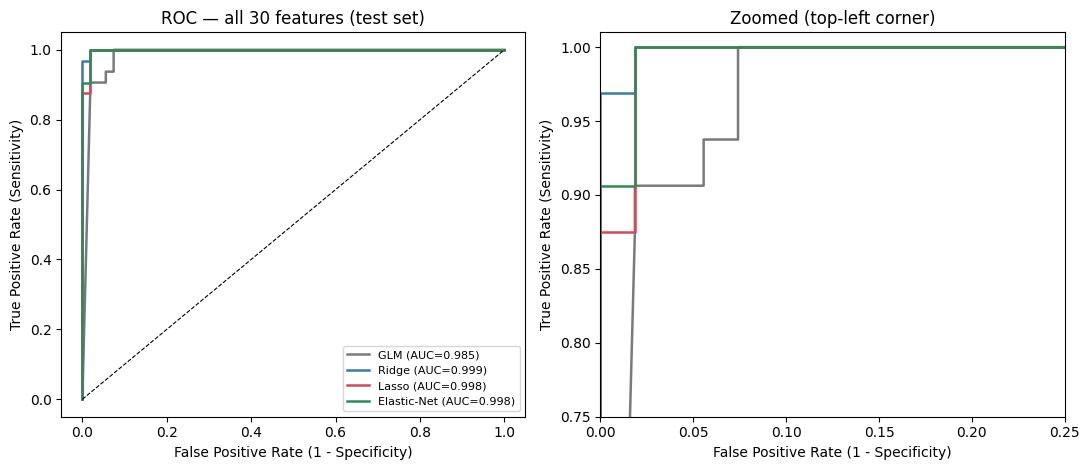

AUC 95% bootstrap CI (test, 30 features):
  GLM          0.9850  [0.9582, 1.0000]
  Ridge        0.9994  [0.9965, 1.0000]
  Lasso        0.9977  [0.9916, 1.0000]
  Elastic-Net  0.9983  [0.9929, 1.0000]


In [16]:
# ---------- (১) ৩০ ফিচারে ৪ মডেলের ROC (paper Fig 1 ধাঁচে) ----------
paper_probs_te = {n: m.predict_proba(Xte_all)[:, 1] for n, m in paper_models.items()}   # test probability
pcolors = {"GLM": "#7A7A7A", "Ridge": "#3A7CA5", "Lasso": "#D1495B", "Elastic-Net": "#2E8B57"}

fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
for a in ax:
    for name, p in paper_probs_te.items():
        fpr, tpr, _ = roc_curve(y_test, p)                               # ROC বিন্দু
        a.plot(fpr, tpr, color=pcolors[name], lw=1.8, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
    a.plot([0, 1], [0, 1], "k--", lw=0.8)
    a.set_xlabel("False Positive Rate (1 - Specificity)"); a.set_ylabel("True Positive Rate (Sensitivity)")
ax[0].set_title("ROC — all 30 features (test set)"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].set_xlim(0, 0.25); ax[1].set_ylim(0.75, 1.01); ax[1].set_title("Zoomed (top-left corner)")   # কাছাকাছি curve আলাদা করে দেখতে
plt.tight_layout(); savefig("14_roc_30features_4models.png"); plt.show()

auc_ci = {}                                                              # AUC-এর bootstrap 95% CI
rng_roc = np.random.RandomState(SEED)
for name, p in paper_probs_te.items():
    vals = []
    for _ in range(N_BOOT_CI):
        ix = rng_roc.choice(len(y_test), len(y_test), replace=True)
        if len(np.unique(y_test[ix])) == 2: vals.append(roc_auc_score(y_test[ix], p[ix]))
    auc_ci[name] = np.percentile(vals, [2.5, 97.5])
print("AUC 95% bootstrap CI (test, 30 features):")
for n, (lo, hi) in auc_ci.items():
    print(f"  {n:12s} {roc_auc_score(y_test, paper_probs_te[n]):.4f}  [{lo:.4f}, {hi:.4f}]")

📊 Calibration ও probability accuracy (test set, 30 ফিচার):


,model,training,brier,ece,cal_slope,cal_intercept,mean_pred,prevalence,auc
0,Elastic-Net,No-SMOTE,0.0153,0.0266,2.4324,0.8022,0.3644,0.3721,0.9994
1,Elastic-Net,SMOTE,0.0158,0.0211,1.9294,-0.0205,0.3743,0.3721,0.9983
2,GLM,No-SMOTE,0.0581,0.0116,0.2000,-0.0895,0.3605,0.3721,0.9858
3,GLM,SMOTE,0.0581,0.0349,0.2112,-0.0145,0.3604,0.3721,0.9850
4,Lasso,No-SMOTE,0.0170,0.0273,2.1717,0.8599,0.3636,0.3721,0.9977
5,Lasso,SMOTE,0.0182,0.0225,1.6790,0.2275,0.3708,0.3721,0.9977
6,Ridge,No-SMOTE,0.0130,0.0285,8.7376,1.4449,0.3634,0.3721,0.9994
7,Ridge,SMOTE,0.0132,0.0218,3.0981,-0.3510,0.3751,0.3721,0.9994


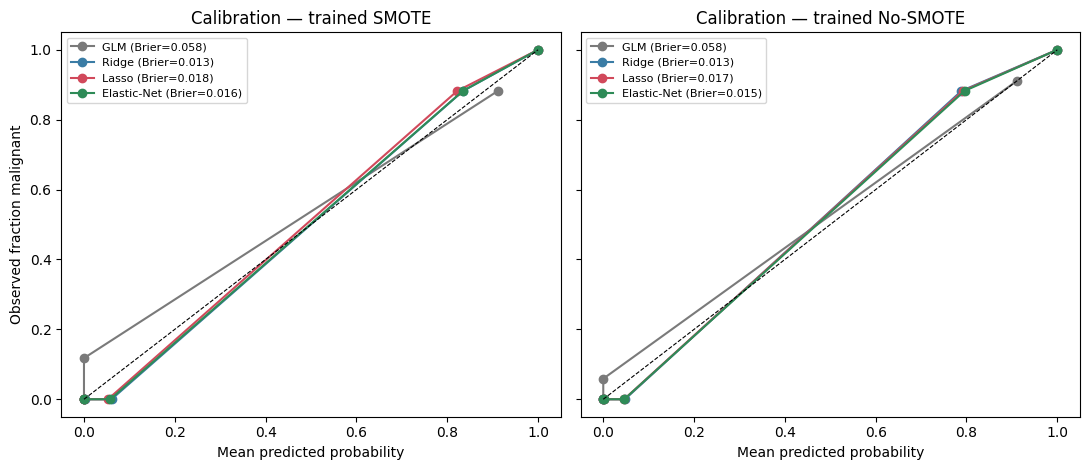

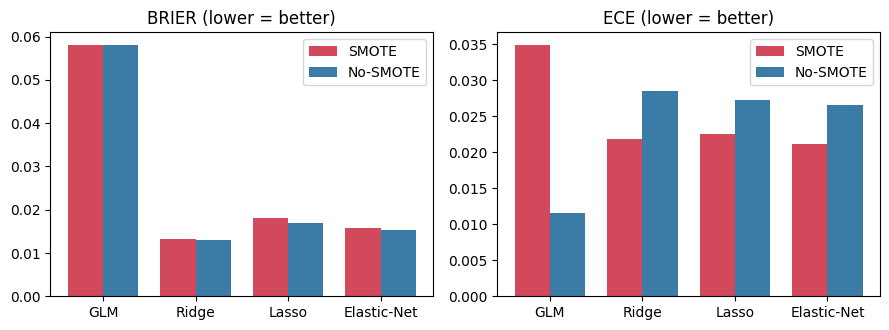

In [17]:
# ---------- (২) ৪ মডেলের Calibration: SMOTE বনাম No-SMOTE ----------
from sklearn.calibration import calibration_curve

def calib_slope_intercept(y_true, p):                                    # logit(p)-এর বিপরীতে y regress করা
    pc = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    z = np.log(pc / (1 - pc)).reshape(-1, 1)
    lr = LogisticRegression(C=1e6, max_iter=2000).fit(z, y_true)
    return float(lr.coef_[0, 0]), float(lr.intercept_[0])               # আদর্শ: slope=1, intercept=0

def ece_score(y_true, p, n_bins=5):                                      # সমান-সংখ্যক নমুনার bin দিয়ে ECE
    y_true, p = np.asarray(y_true), np.asarray(p)
    bins = np.array_split(np.argsort(p), n_bins)
    return float(sum(len(b) / len(p) * abs(y_true[b].mean() - p[b].mean()) for b in bins))

# SMOTE-করা train-এ fit করা মডেল = paper_models; No-SMOTE: একই tuned প্যারামিটার, কিন্তু আসল (imbalanced) train-এ fit
kind_of = {"GLM": "glm", "Ridge": "ridge", "Lasso": "lasso", "Elastic-Net": "enet"}
paper_models_nosmote = {}
for label, kind in kind_of.items():
    paper_models_nosmote[label] = make_lr(kind, **paper_params[kind]).fit(X_train_s.values, y_train)
probs_cal = {("SMOTE", n): paper_models[n].predict_proba(Xte_all)[:, 1] for n in kind_of}
probs_cal.update({("No-SMOTE", n): paper_models_nosmote[n].predict_proba(Xte_all)[:, 1] for n in kind_of})

rows = []
for (setting, name), p in probs_cal.items():
    s, i = calib_slope_intercept(y_test, p)
    rows.append(dict(model=name, training=setting, brier=brier_score_loss(y_test, p), ece=ece_score(y_test, p),
                     cal_slope=s, cal_intercept=i, mean_pred=p.mean(), prevalence=y_test.mean(), auc=roc_auc_score(y_test, p)))
calib_table = pd.DataFrame(rows).sort_values(["model", "training"]).round(4).reset_index(drop=True)
print("📊 Calibration ও probability accuracy (test set, 30 ফিচার):")
display(calib_table)
calib_table.to_csv(os.path.join(OUT_DIR, "calibration_table_30feat.csv"), index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for a, setting in zip(ax, ["SMOTE", "No-SMOTE"]):
    for name in kind_of:
        fp_, mp_ = calibration_curve(y_test, probs_cal[(setting, name)], n_bins=5, strategy="quantile")
        b = calib_table[(calib_table.model == name) & (calib_table.training == setting)].brier.iloc[0]
        a.plot(mp_, fp_, "o-", color=pcolors[name], label=f"{name} (Brier={b:.3f})")
    a.plot([0, 1], [0, 1], "k--", lw=0.8); a.set_xlabel("Mean predicted probability"); a.set_title(f"Calibration — trained {setting}")
    a.legend(fontsize=8, loc="upper left")
ax[0].set_ylabel("Observed fraction malignant")
plt.tight_layout(); savefig("15_calibration_4models_smote_vs_nosmote.png"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))                           # Brier ও ECE তুলনা
x = np.arange(len(kind_of)); w = 0.38
for a, metric in zip(ax, ["brier", "ece"]):
    for k, (setting, col) in enumerate([("SMOTE", "#D1495B"), ("No-SMOTE", "#3A7CA5")]):
        vals = [calib_table[(calib_table.model == n) & (calib_table.training == setting)][metric].iloc[0] for n in kind_of]
        a.bar(x + (k - 0.5) * w, vals, w, label=setting, color=col)
    a.set_xticks(x); a.set_xticklabels(list(kind_of)); a.set_title(f"{metric.upper()} (lower = better)"); a.legend()
plt.tight_layout(); savefig("15b_brier_ece_smote_vs_nosmote.png"); plt.show()

## 🧮 ধাপ ৯খ: Coefficient Shrinkage ও Sparsity Pattern (Journal-এর জন্য নতুন)
- **Coefficient table:** GLM / Ridge / Lasso / Elastic-Net-এর (standardized) coefficient পাশাপাশি।
- **Sparsity:** Lasso ও Elastic-Net কতগুলো coefficient **ঠিক শূন্য** করে; Ridge শূন্য করে না (শুধু সংকুচিত করে)।
- **Coefficient path:** penalty `C = 1/λ` বদলালে প্রতিটি coefficient কীভাবে সংকুচিত হয়; লাল ড্যাশ রেখা = CV-তে বাছাই করা `C`।

📊 Sparsity সারাংশ (tuned মডেল, ৩০ ফিচার):


,model,n_nonzero,n_zero,L1_norm,L2_norm,max_abs_coef
0,GLM,30,0,2796.0393,599.3304,211.7959
1,Ridge,30,0,15.2393,3.1794,1.1116
2,Lasso,17,13,16.7694,5.3675,3.2659
3,Elastic-Net,20,10,17.0636,4.6265,2.2040


📊 Coefficient table (standardized):


,GLM,Ridge,Lasso,Elastic-Net
texture_worst,211.7959,1.1116,2.3261,2.1632
radius_se,207.1805,1.0702,3.2659,2.2040
compactness_mean,-191.3802,-0.3155,0.0000,0.0000
concave points_mean,158.8384,0.7052,1.7376,1.2306
texture_se,-155.7508,-0.1909,-0.7536,-0.6319
concave points_se,139.1801,0.3758,0.4870,0.4057
symmetry_worst,138.5124,0.9342,0.7528,0.8791
concavity_mean,137.8462,0.6399,0.0000,0.4841
area_se,136.3417,0.8008,0.0000,1.1767
perimeter_se,131.3478,0.7578,0.0000,0.4238


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


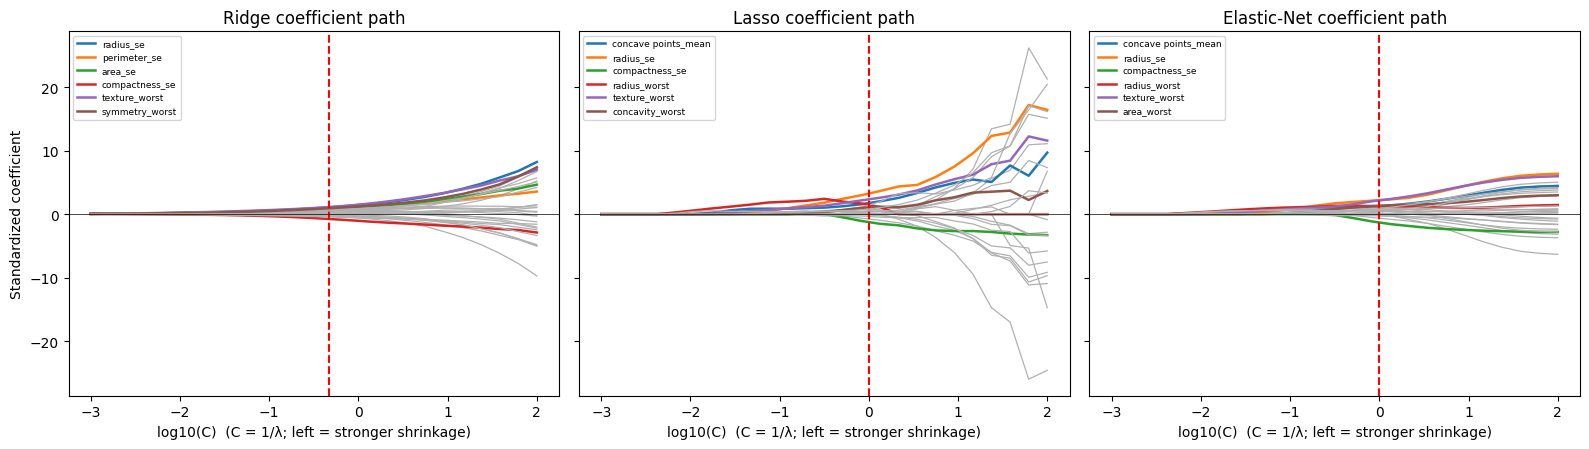

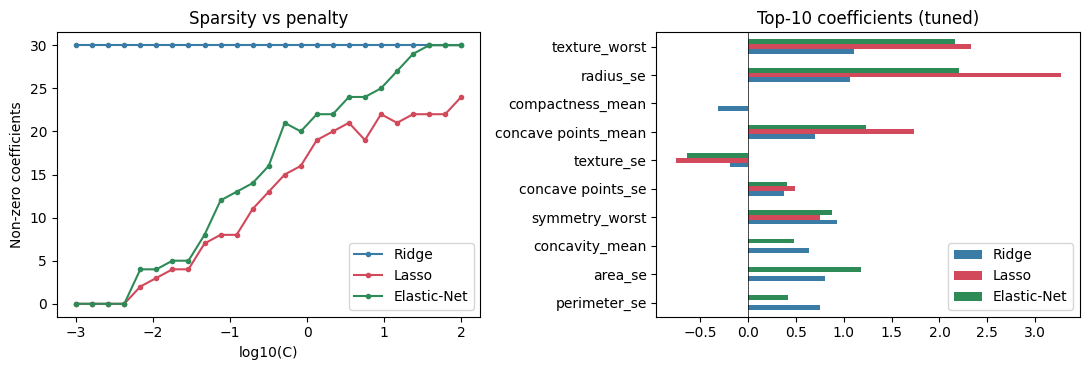

In [18]:
# ---------- (১) Coefficient table ও Sparsity সারাংশ ----------
coef_tab = pd.DataFrame({n: m.coef_.ravel() for n, m in paper_models.items()}, index=feat_names)   # feature × model
sparsity_rows = []
for n in coef_tab.columns:
    c = coef_tab[n].values
    sparsity_rows.append(dict(model=n, n_nonzero=int((np.abs(c) > 1e-8).sum()), n_zero=int((np.abs(c) <= 1e-8).sum()),
                              L1_norm=np.abs(c).sum(), L2_norm=np.sqrt((c ** 2).sum()), max_abs_coef=np.abs(c).max()))
sparsity_table = pd.DataFrame(sparsity_rows).round(4)
print("📊 Sparsity সারাংশ (tuned মডেল, ৩০ ফিচার):"); display(sparsity_table)
print("📊 Coefficient table (standardized):")
display(coef_tab.assign(_s=coef_tab.abs().max(axis=1)).sort_values("_s", ascending=False).drop(columns="_s").round(4))
coef_tab.round(5).to_csv(os.path.join(OUT_DIR, "coefficient_table_30feat.csv"))
sparsity_table.to_csv(os.path.join(OUT_DIR, "sparsity_table.csv"), index=False)

# ---------- (২) Coefficient path: C বদলালে কী হয় ----------
Cs = np.logspace(-3, 2, 25)
paths, nnz = {}, {}
for kind, label in [("ridge", "Ridge"), ("lasso", "Lasso"), ("enet", "Elastic-Net")]:
    P = []
    for C in Cs:
        kw = {"C": C}
        if kind == "enet": kw["l1_ratio"] = paper_params["enet"]["l1_ratio"]    # tuned mixing α স্থির রাখা
        P.append(make_lr(kind, **kw).fit(Xtr_all, y_train_bal).coef_.ravel())
    paths[label] = np.array(P); nnz[label] = (np.abs(paths[label]) > 1e-8).sum(axis=1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for a, (label, P) in zip(ax, paths.items()):
    top = np.argsort(-np.abs(coef_tab[label].values))[:6]                       # শীর্ষ ৬ ফিচার চিহ্নিত
    for j in range(P.shape[1]):
        a.plot(np.log10(Cs), P[:, j], color="#B0B0B0" if j not in top else None, lw=0.9 if j not in top else 1.8,
               label=feat_names[j] if j in top else None)
    a.axvline(np.log10(paper_params[{"Ridge": "ridge", "Lasso": "lasso", "Elastic-Net": "enet"}[label]]["C"]), color="red", ls="--")
    a.axhline(0, color="k", lw=0.5); a.set_xlabel("log10(C)  (C = 1/λ; left = stronger shrinkage)"); a.set_title(f"{label} coefficient path")
    a.legend(fontsize=6.5, loc="upper left")
ax[0].set_ylabel("Standardized coefficient")
plt.tight_layout(); savefig("16_coefficient_paths.png"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))                                # sparsity vs C এবং top coefficient তুলনা
for label, col in [("Ridge", "#3A7CA5"), ("Lasso", "#D1495B"), ("Elastic-Net", "#2E8B57")]:
    ax[0].plot(np.log10(Cs), nnz[label], "o-", ms=3, color=col, label=label)
ax[0].set_xlabel("log10(C)"); ax[0].set_ylabel("Non-zero coefficients"); ax[0].set_title("Sparsity vs penalty"); ax[0].legend()
top10 = coef_tab.abs().max(axis=1).sort_values(ascending=False).head(10).index
coef_tab.loc[top10[::-1], ["Ridge", "Lasso", "Elastic-Net"]].plot(kind="barh", ax=ax[1], color=["#3A7CA5", "#D1495B", "#2E8B57"])
ax[1].set_title("Top-10 coefficients (tuned)"); ax[1].axvline(0, color="k", lw=0.5)
plt.tight_layout(); savefig("17_sparsity_and_top_coefficients.png"); plt.show()

## 🔗 ধাপ ৯গ: Feature Stability Across Penalization Methods
**Lasso, Elastic-Net (CV-optimal) ও Elastic-Net (1-SE)**-এর stable feature set-এর মিল-অমিল: selection-frequency heatmap, Jaccard, Venn, Spearman ρ, সব পদ্ধতিতে stable "core" feature।

> 📝 Ridge এখানে নেই: Ridge কখনো coefficient শূন্য করে না, তাই selection frequency ≡ 1.0। **Jaccard = 1.0 মানে 1-SE ও CV-optimal EN একই set — তখন "sparse EN" দাবি করা যাবে না** (ডেটা dense)।

Stable set আকার: {'Lasso': 10, 'Elastic-Net': 15, 'Elastic-Net (1-SE)': 11}

Jaccard similarity (stable sets):


,Lasso,Elastic-Net,Elastic-Net (1-SE)
Lasso,1.000,0.667,0.615
Elastic-Net,0.667,1.000,0.733
Elastic-Net (1-SE),0.615,0.733,1.000


Spearman ρ (selection-frequency rank):


,Lasso,Elastic-Net,Elastic-Net (1-SE)
Lasso,1.000,0.875,0.848
Elastic-Net,0.875,1.000,0.970
Elastic-Net (1-SE),0.848,0.970,1.000



✅ তিন পদ্ধতিতেই stable 'core' ফিচার (8): ['texture_worst', 'radius_se', 'area_worst', 'symmetry_worst', 'concavity_worst', 'concave points_mean', 'compactness_se', 'smoothness_worst']


,Lasso,Elastic-Net,Elastic-Net (1-SE),n_methods,mean_freq
texture_worst,1,1,1,3,0.995
radius_se,1,1,1,3,0.954
area_worst,1,1,1,3,0.950
symmetry_worst,1,1,1,3,0.944
concavity_worst,1,1,1,3,0.918
concave points_mean,1,1,1,3,0.887
compactness_se,1,1,1,3,0.876
smoothness_worst,1,1,1,3,0.773
radius_worst,0,1,1,2,0.888
concave points_worst,0,1,1,2,0.756


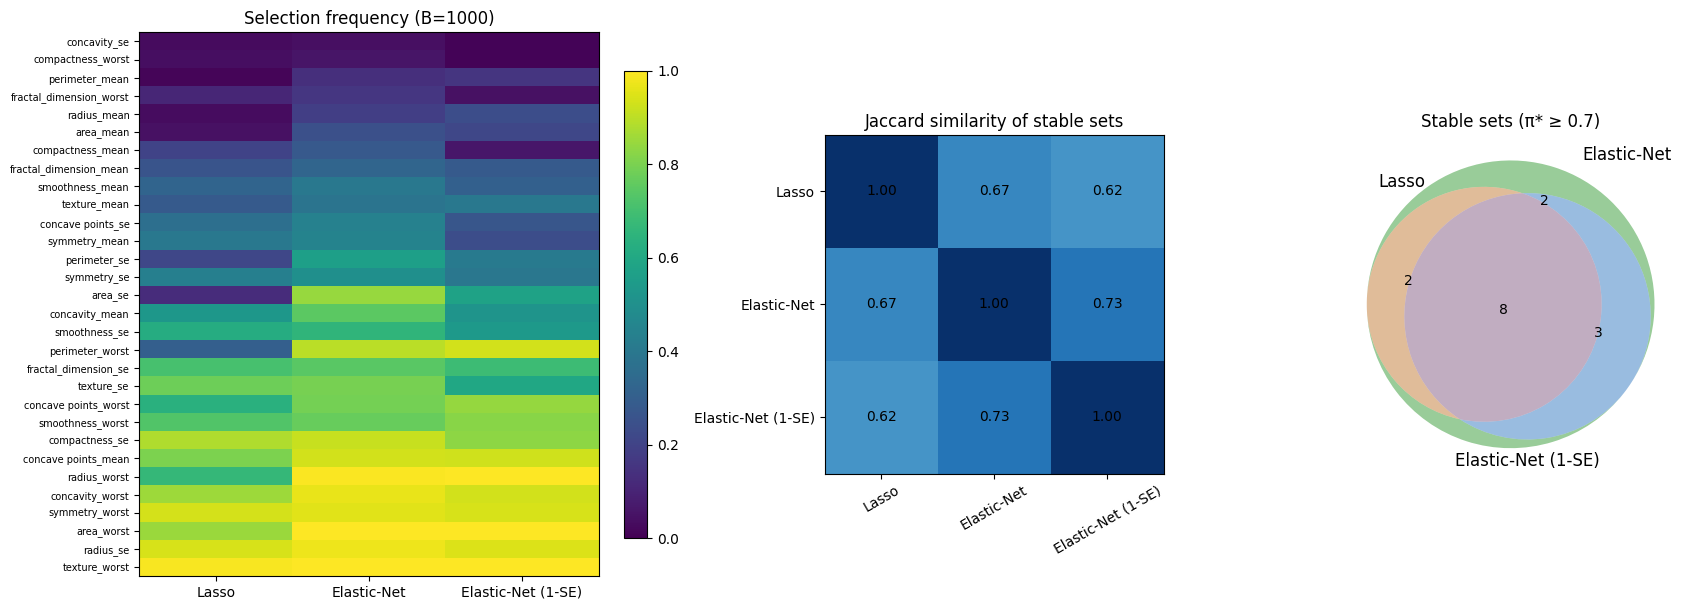

In [19]:
from itertools import combinations
from scipy.stats import spearmanr
methods = ["Lasso", "Elastic-Net", "Elastic-Net (1-SE)"]
freq_df = pd.DataFrame({m: freq[m] for m in methods})                    # feature × method frequency
sets = {m: set(stable_sets[m]) for m in methods}                         # stable set (π̂ ≥ STAB_THR)

# ---------- (১) Jaccard ও Spearman ----------
jac = pd.DataFrame(index=methods, columns=methods, dtype=float)
rho_df = pd.DataFrame(index=methods, columns=methods, dtype=float)
for a_, b_ in combinations(methods, 2):
    u = len(sets[a_] | sets[b_])
    jac.loc[a_, b_] = jac.loc[b_, a_] = len(sets[a_] & sets[b_]) / u if u else np.nan
    r = spearmanr(freq_df[a_], freq_df[b_]).correlation
    rho_df.loc[a_, b_] = rho_df.loc[b_, a_] = r
for m in methods: jac.loc[m, m] = 1.0; rho_df.loc[m, m] = 1.0
print("Stable set আকার:", {m: len(s) for m, s in sets.items()})
print("\nJaccard similarity (stable sets):"); display(jac.astype(float).round(3))
print("Spearman ρ (selection-frequency rank):"); display(rho_df.astype(float).round(3))

core = sorted(set.intersection(*sets.values()), key=lambda f: -freq_df.loc[f].mean())
print(f"\n✅ তিন পদ্ধতিতেই stable 'core' ফিচার ({len(core)}):", core)
membership = pd.DataFrame({m: [int(f in sets[m]) for f in feat_names] for m in methods}, index=feat_names)
membership["n_methods"] = membership.sum(axis=1)
membership["mean_freq"] = freq_df.mean(axis=1)
membership = membership.sort_values(["n_methods", "mean_freq"], ascending=False)
display(membership.round(3).head(20)); membership.round(4).to_csv(os.path.join(OUT_DIR, "cross_method_stability.csv"))

# ---------- (২) Heatmap + Venn ----------
fig, ax = plt.subplots(1, 3, figsize=(17, 6.2), gridspec_kw={"width_ratios": [1.5, 1, 1]})
order = freq_df.assign(m=freq_df.mean(axis=1)).sort_values("m", ascending=True).index
im = ax[0].imshow(freq_df.loc[order].values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(methods); ax[0].set_yticks(range(len(order))); ax[0].set_yticklabels(order, fontsize=7)
ax[0].set_title(f"Selection frequency (B={B_BOOT})"); plt.colorbar(im, ax=ax[0], fraction=0.046)
im2 = ax[1].imshow(jac.astype(float).values, vmin=0, vmax=1, cmap="Blues")
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(methods, rotation=30); ax[1].set_yticks(range(3)); ax[1].set_yticklabels(methods)
for i in range(3):
    for j in range(3): ax[1].text(j, i, f"{jac.astype(float).values[i, j]:.2f}", ha="center", va="center")
ax[1].set_title("Jaccard similarity of stable sets")
try:
    from matplotlib_venn import venn3
    venn3([sets[m] for m in methods], set_labels=methods, ax=ax[2]); ax[2].set_title(f"Stable sets (π* ≥ {STAB_THR})")
except Exception as e:                                                   # library না থাকলে টেক্সট fallback
    ax[2].axis("off"); ax[2].text(0, 0.5, "\n".join(f"{m}: {len(s)}" for m, s in sets.items()) + f"\ncore: {len(core)}")
    print("Venn skip:", e)
plt.tight_layout(); savefig("18_cross_method_stability.png"); plt.show()

## 🧩 ধাপ ১০: Hybrid Feature Selection (Hybrid-FS)
তিনটি পদ্ধতির **voting**: কমপক্ষে **২টি** পদ্ধতিতে নির্বাচিত feature = Hybrid-FS final।
- RFE → top-K  · Random Forest → top-K  · **Elastic-Net (1-SE, fewest non-zero) → bootstrap-stable (π̂ ≥ 0.70)**

> ⚠️ Hybrid-FS এখানে **একবারই, মূল train split-এ** বাছাই হয়েছে। এর প্রকৃত উপকার (বা অপকার) বুঝতে ধাপ ২১-এর **in-fold ablation** দেখুন — সেখানে "No FS (all 30)" ও "Full" তুলনা করা হয়। উপকার প্রমাণিত না হলে paper-এ লিখুন "FS reduces dimensionality / improves interpretability without loss", "improves accuracy" নয়।

In [20]:
sel_en = stable_sets["Elastic-Net (1-SE)"]                           # sparse EN stable set
if len(sel_en) >= len(feat_names) - 2:
    print("⚠️ EN stable set প্রায় সব ফিচার — vote-এ তথ্য নেই (Hybrid ≈ RFE ∪ RF); STAB_THR/1-SE যাচাই করুন")
print(f"EN (1-SE) stable ফিচার: {len(sel_en)}/{len(feat_names)}")
votes = Counter()                                                    # ভোট গণনা
for s in (sel_rfe, sel_rf, sel_en):                                  # তিন পদ্ধতি
    votes.update(s)                                                  # ভোট যোগ

vote_df = pd.DataFrame({"feature": feat_names})                      # ভোট টেবিল
vote_df["RFE"] = vote_df.feature.isin(sel_rfe).astype(int)           # RFE ভোট
vote_df["RF"] = vote_df.feature.isin(sel_rf).astype(int)             # RF ভোট
vote_df["EN_stable"] = vote_df.feature.isin(sel_en).astype(int)      # EN ভোট
vote_df["votes"] = vote_df[["RFE", "RF", "EN_stable"]].sum(axis=1)   # মোট ভোট
vote_df["rf_importance"] = vote_df.feature.map(rf_imp)               # tie-break-এর জন্য

sel_hybrid = vote_df[vote_df.votes >= 2].feature.tolist()            # ≥২ ভোট
if len(sel_hybrid) < 8:                                              # খুব কম হলে নিরাপদ fallback
    sel_hybrid = vote_df.sort_values(["votes", "rf_importance"], ascending=False).feature.head(10).tolist()

vote_df = vote_df.sort_values(["votes", "rf_importance"], ascending=False).reset_index(drop=True)
display(vote_df.round(4))                                            # ভোট টেবিল
print(f"\n✅ Hybrid-FS final ({len(sel_hybrid)} ফিচার):", sel_hybrid)

sel_idx = [feat_names.index(f) for f in sel_hybrid]                  # ফিচারের index (deployment-এ লাগবে)
X_tr_h = X_train_bal[sel_hybrid].values                              # Hybrid train (SMOTE-সহ)
X_va_h = X_val_s[sel_hybrid].values                                  # Hybrid val
X_te_h = X_test_s[sel_hybrid].values                                 # Hybrid test
y_tr = y_train_bal                                                   # train label (balanced)
y_va, y_te = y_val, y_test                                           # val/test label
print("Hybrid shapes:", X_tr_h.shape, X_va_h.shape, X_te_h.shape)
X_tr_h_unbal = X_train_s[sel_hybrid].values        # un-SMOTEd Hybrid train (FL ও no-SMOTE baseline-এর জন্য)


EN (1-SE) stable ফিচার: 11/30


,feature,RFE,RF,EN_stable,votes,rf_importance
0,perimeter_worst,1,1,1,3,0.1492
1,area_worst,1,1,1,3,0.1483
2,concave points_mean,1,1,1,3,0.0961
3,radius_worst,1,1,1,3,0.0762
4,concave points_worst,1,1,1,3,0.0750
5,texture_worst,1,1,1,3,0.0198
6,radius_se,1,1,1,3,0.0176
7,symmetry_worst,1,1,1,3,0.0160
8,concavity_mean,1,1,0,2,0.0442
9,area_mean,1,1,0,2,0.0423



✅ Hybrid-FS final (15 ফিচার): ['area_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'radius_se', 'area_se', 'compactness_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst']
Hybrid shapes: (500, 15) (85, 15) (86, 15)


## 💾 ধাপ ১১: Final Data সেভ
Feature selection শেষে চূড়ান্ত data Drive-এ সেভ হচ্ছে (পরে আবার চালাতে না হয়)।

In [21]:
final_dir = os.path.join(OUT_DIR, "final_data")                      # ফোল্ডার
os.makedirs(final_dir, exist_ok=True)

def save_split(Xdf, yy, name, cols):                                 # CSV সেভ helper
    out = pd.DataFrame(np.asarray(Xdf)[:, [feat_names.index(c) for c in cols]] if not isinstance(Xdf, pd.DataFrame) else Xdf[cols].values, columns=cols)
    out["diagnosis"] = np.asarray(yy)                                # label যোগ
    out.to_csv(os.path.join(final_dir, name), index=False)           # সেভ

save_split(X_train_bal, y_train_bal, "train_balanced_hybrid.csv", sel_hybrid)   # SMOTE-করা train
save_split(X_val_s, y_val, "val_hybrid.csv", sel_hybrid)             # val
save_split(X_test_s, y_test, "test_hybrid.csv", sel_hybrid)          # test
save_split(X_train_bal, y_train_bal, "train_balanced_all30.csv", feat_names)    # সব ফিচার (train)
vote_df.to_csv(os.path.join(final_dir, "feature_selection_votes.csv"), index=False)   # ভোট টেবিল
json.dump({"selected_features": sel_hybrid, "rfe": sel_rfe, "rf": sel_rf, "elastic_net_stable": sel_en},
          open(os.path.join(final_dir, "selected_features.json"), "w"), indent=2, ensure_ascii=False)   # ফিচার তালিকা
print("✅ সেভ হয়েছে:", os.listdir(final_dir))

✅ সেভ হয়েছে: ['train_balanced_hybrid.csv', 'test_hybrid.csv', 'val_hybrid.csv', 'train_balanced_all30.csv', 'selected_features.json', 'feature_selection_votes.csv']


## 🧠 ধাপ ১২: Custom Model Development
**Residual-Gated MLP (PyTorch):**
- **Feature Gate:** প্রতিটি input feature-এর জন্য শেখা যায় এমন attention weight (interpretability)
- **Residual Block:** LayerNorm + Linear + GELU + Dropout + skip connection
- Dropout ব্যবহার হওয়ায় পরে **MC-Dropout** দিয়ে uncertainty বের করা যাবে
- Threshold: Validation set-এর **Youden's index** (paper-এর মতো)

In [22]:
import torch, torch.nn as nn, torch.nn.functional as F             # PyTorch
DEVICE = torch.device("cpu")                                         # ছোট data, তাই CPU যথেষ্ট

def set_seed(seed=SEED):                                             # সব seed এক সাথে সেট
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

class ResBlock(nn.Module):                                           # Residual ব্লক
    def __init__(self, dim, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim), nn.GELU(),
                                 nn.Dropout(dropout), nn.Linear(dim, dim))   # ভেতরের স্তর
    def forward(self, x):
        return x + self.net(x)                                       # skip connection

class CustomNet(nn.Module):                                          # আমাদের Custom মডেল
    def __init__(self, in_dim, hidden=64, n_blocks=2, dropout=0.3, use_gate=True):
        super().__init__()
        self.use_gate = use_gate                                     # gate চালু/বন্ধ (ablation-এর জন্য)
        self.gate = nn.Parameter(torch.zeros(in_dim))                # feature gate (শুরুতে 2*sigmoid(0)=1)
        self.inp = nn.Sequential(nn.Linear(in_dim, hidden), nn.GELU(), nn.Dropout(dropout))   # ইনপুট স্তর
        self.blocks = nn.Sequential(*[ResBlock(hidden, dropout) for _ in range(n_blocks)])     # residual ব্লকগুলো
        self.out = nn.Linear(hidden, 1)                              # আউটপুট logit
    def forward(self, x):
        if self.use_gate:
            x = x * (2 * torch.sigmoid(self.gate))                   # প্রতিটি ফিচারকে gate দিয়ে গুণ
        return self.out(self.blocks(self.inp(x))).squeeze(-1)        # logit রিটার্ন

def predict_proba(model, X):                                         # probability বের করা (dropout বন্ধ)
    model.eval()                                                     # eval মোড
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(np.asarray(X), dtype=torch.float32))).numpy()

def train_model(model, X, yv, epochs=100, lr=1e-3, wd=1e-4, bs=32, X_val=None, y_val=None,
                patience=15, prox_mu=0.0, global_params=None):       # সাধারণ training ফাংশন
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)   # optimizer
    Xt = torch.tensor(np.asarray(X), dtype=torch.float32)            # ইনপুট tensor
    yt = torch.tensor(np.asarray(yv), dtype=torch.float32)           # label tensor
    n = len(Xt); best, best_state, wait = float("inf"), None, 0      # early stopping ভেরিয়েবল
    for ep in range(epochs):
        model.train()                                                # train মোড (dropout চালু)
        perm = torch.randperm(n)                                     # shuffle
        for i in range(0, n, bs):
            idx = perm[i:i + bs]                                     # mini-batch
            opt.zero_grad()                                          # gradient শূন্য
            loss = F.binary_cross_entropy_with_logits(model(Xt[idx]), yt[idx])   # BCE loss
            if prox_mu > 0 and global_params is not None:            # FedProx-এর proximal term
                loss = loss + (prox_mu / 2) * sum(((p - g) ** 2).sum() for p, g in zip(model.parameters(), global_params))
            loss.backward(); opt.step()                              # backprop ও আপডেট
        if X_val is not None:                                        # validation-based early stopping
            model.eval()
            with torch.no_grad():
                vl = F.binary_cross_entropy_with_logits(model(torch.tensor(np.asarray(X_val), dtype=torch.float32)),
                                                        torch.tensor(np.asarray(y_val), dtype=torch.float32)).item()
            if vl < best - 1e-5:                                     # উন্নতি হলে সংরক্ষণ
                best, best_state, wait = vl, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
                if wait >= patience: break                           # patience শেষ → থামা
    if best_state is not None:
        model.load_state_dict(best_state)                            # সেরা weight ফেরত
    return model

def build_and_train(hp, Xtr, ytr, Xva, yva, seed=SEED, use_gate=True):   # মডেল বানিয়ে train করা
    set_seed(seed)
    m = CustomNet(Xtr.shape[1], hp["hidden"], hp["n_blocks"], hp["dropout"], use_gate)
    return train_model(m, Xtr, ytr, epochs=EPOCHS_MAX, lr=hp["lr"], wd=hp["wd"], bs=hp["bs"],
                       X_val=Xva, y_val=yva, patience=PATIENCE)

HP_DEFAULT = dict(hidden=64, n_blocks=2, dropout=0.3, lr=1e-3, wd=1e-4, bs=32)   # ডিফল্ট প্যারামিটার
model_default = build_and_train(HP_DEFAULT, X_tr_h, y_tr, X_va_h, y_va)          # Hybrid ফিচারে train
p_va = predict_proba(model_default, X_va_h); p_te = predict_proba(model_default, X_te_h)
thr_default = youden_threshold(y_va, p_va)                           # val থেকে Youden threshold
res_default = compute_metrics(y_te, p_te, thr_default)               # test মূল্যায়ন
print("Custom (default HP) Test:", {k: round(v, 4) if isinstance(v, float) else v for k, v in res_default.items()})

Custom (default HP) Test: {'threshold': 0.883, 'accuracy': 0.9884, 'precision': 1.0, 'sensitivity': 0.9688, 'specificity': np.float64(1.0), 'f1': 0.9841, 'auc': np.float64(1.0), 'brier': np.float64(0.0075), 'ece': 0.008, 'tp': 31, 'tn': 54, 'fp': 0, 'fn': 1}


### 📊 Baseline তুলনা (Hybrid ফিচারে)
Paper-এর মডেল (GLM, Ridge, Lasso, Elastic-Net) ছাড়াও Random Forest ও SVM-এর সাথে Custom মডেলের তুলনা।

📊 Test set তুলনা (Hybrid-FS ফিচার):


,model,threshold,accuracy,precision,sensitivity,specificity,f1,auc,brier,ece,tp,tn,fp,fn
0,GLM,0.512,0.9884,0.9697,1.0000,0.9815,0.9846,0.9994,0.0156,0.0204,32,53,1,0
5,SVM (RBF),0.391,0.9884,1.0000,0.9688,1.0000,0.9841,1.0000,0.0085,0.0223,31,54,0,1
4,Random Forest,0.543,0.9884,1.0000,0.9688,1.0000,0.9841,0.9988,0.0155,0.0397,31,54,0,1
6,Custom MLP (default HP),0.883,0.9884,1.0000,0.9688,1.0000,0.9841,1.0000,0.0075,0.0080,31,54,0,1
1,Ridge,0.540,0.9767,0.9688,0.9688,0.9815,0.9688,0.9994,0.0121,0.0119,31,53,1,1
2,Lasso,0.504,0.9767,0.9688,0.9688,0.9815,0.9688,0.9988,0.0164,0.0178,31,53,1,1
3,Elastic-Net,0.547,0.9767,0.9688,0.9688,0.9815,0.9688,0.9994,0.0125,0.0126,31,53,1,1


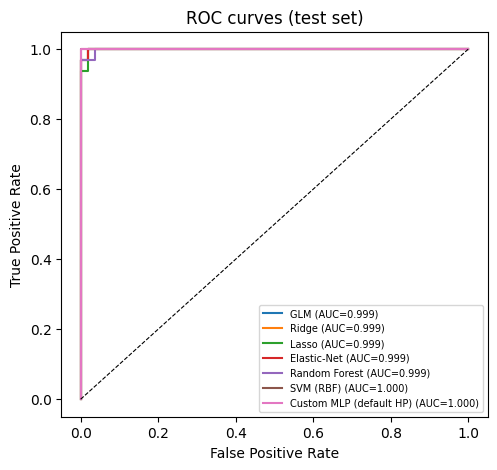

In [23]:
from sklearn.svm import SVC                                          # SVM

base_models, base_params = {}, {}                                    # baseline সংরক্ষণ
for kind, label in [("glm", "GLM"), ("ridge", "Ridge"), ("lasso", "Lasso"), ("enet", "Elastic-Net")]:
    base_models[label], base_params[kind] = tune_lr(kind, X_train_raw[sel_hybrid].values, y_train, X_tr_h, y_tr)   # Hybrid ফিচারে tune
base_models["Random Forest"] = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_tr_h, y_tr)
base_models["SVM (RBF)"] = SVC(probability=True, random_state=SEED).fit(X_tr_h, y_tr)

test_probs, val_probs, rows = {}, {}, []                             # প্রেডিকশন সংরক্ষণ
for name, mdl in base_models.items():
    val_probs[name] = mdl.predict_proba(X_va_h)[:, 1]                # val probability
    test_probs[name] = mdl.predict_proba(X_te_h)[:, 1]               # test probability
val_probs["Custom MLP (default HP)"], test_probs["Custom MLP (default HP)"] = p_va, p_te       # Custom যোগ

for name in test_probs:
    thr = youden_threshold(y_va, val_probs[name])                    # প্রতি মডেলের Youden threshold
    rows.append({"model": name, **compute_metrics(y_te, test_probs[name], thr)})
cmp_table = pd.DataFrame(rows).round(4).sort_values("accuracy", ascending=False)
print("📊 Test set তুলনা (Hybrid-FS ফিচার):")
display(cmp_table)

plt.figure(figsize=(5.5, 5))                                         # ROC কার্ভ (paper Fig 1)
for name, p in test_probs.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_te, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(fontsize=7); plt.title("ROC curves (test set)")
savefig("05_roc_curves.png"); plt.show()

## 🎛️ ধাপ ১৩: Hyperparameter Tuning (Optuna)
`hidden`, `n_blocks`, `dropout`, `lr`, `weight decay`, `batch size` — **Validation log-loss** minimize করে সেরা সংমিশ্রণ খোঁজা হবে। (Test set এখানে একবারও ব্যবহার হচ্ছে না।)
`dropout ≥ 0.1` রাখা হয়েছে, যাতে পরে MC-Dropout কাজ করে।

✅ Tuning শেষ (99s) | best val log-loss = 0.0505
🏆 সেরা Hyperparameter: {'hidden': 16, 'n_blocks': 2, 'dropout': 0.45032609262832346, 'lr': 0.007436230989609517, 'wd': 3.410577936664645e-05, 'bs': 16}
ℹ️ HP_BEST শুধু hold-out/FL/deployment-এ ব্যবহার হবে। Ablation ও Nested CV-তে HP প্রতি fold-এর ভেতরে আবার tune হয় (leakage নেই)।


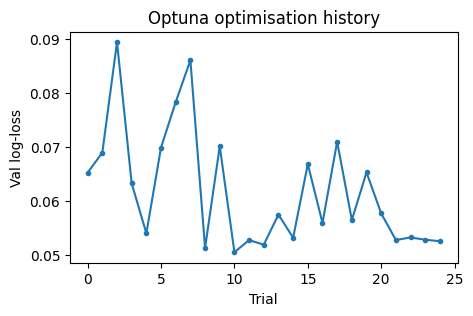

In [24]:
import optuna                                                       # Optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)                 # লগ কমানো

def sample_hp(trial):                                                # v2: একটাই search space (Optuna, ablation, nested CV সবখানে)
    return dict(hidden=trial.suggest_categorical("hidden", [16, 32, 64, 128]),
                n_blocks=trial.suggest_int("n_blocks", 1, 3),
                dropout=trial.suggest_float("dropout", 0.1, 0.5),
                lr=trial.suggest_float("lr", 1e-4, 1e-2, log=True),
                wd=trial.suggest_float("wd", 1e-6, 1e-2, log=True),
                bs=trial.suggest_categorical("bs", [16, 32, 64]))

def objective(trial):                                                # প্রতিটি trial-এর লক্ষ্য ফাংশন
    m = build_and_train(sample_hp(trial), X_tr_h, y_tr, X_va_h, y_va)   # train
    return log_loss(y_va, np.clip(predict_proba(m, X_va_h), 1e-6, 1 - 1e-6))   # val log-loss

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS)                         # tuning চালানো
HP_BEST = study.best_params                                          # সেরা প্যারামিটার
print(f"✅ Tuning শেষ ({time.time()-t0:.0f}s) | best val log-loss = {study.best_value:.4f}")
print("🏆 সেরা Hyperparameter:", HP_BEST)
print("ℹ️ HP_BEST শুধু hold-out/FL/deployment-এ ব্যবহার হবে। Ablation ও Nested CV-তে HP প্রতি fold-এর ভেতরে আবার tune হয় (leakage নেই)।")

plt.figure(figsize=(5, 3))                                           # trial-এর উন্নতির প্লট
plt.plot([t.value for t in study.trials], "o-", ms=3); plt.xlabel("Trial"); plt.ylabel("Val log-loss")
plt.title("Optuna optimisation history"); savefig("06_optuna_history.png"); plt.show()

In [25]:
# ---------- সেরা HP দিয়ে final Custom মডেল (Centralized) ----------
from scipy import stats
final_model = build_and_train(HP_BEST, X_tr_h, y_tr, X_va_h, y_va)
pv_c, pt_c = predict_proba(final_model, X_va_h), predict_proba(final_model, X_te_h)
thr_final = youden_threshold(y_va, pv_c)
res_final = compute_metrics(y_te, pt_c, thr_final)
res_050 = compute_metrics(y_te, pt_c, 0.5)
val_probs["Custom MLP (tuned)"], test_probs["Custom MLP (tuned)"] = pv_c, pt_c

print("🏁 Tuned Custom MLP — hold-out test (Youden thr):", {k: round(v, 4) if isinstance(v, float) else v for k, v in res_final.items()})
print("🏁 Tuned Custom MLP — hold-out test (thr 0.5)   :", {k: round(v, 4) if isinstance(v, float) else v for k, v in res_050.items()})
n_te = len(y_te)
for nm, r_ in [("Youden thr", res_final), ("thr 0.5", res_050)]:
    k_ = int(round(r_["accuracy"] * n_te))
    ci_ = stats.binomtest(k_, n_te).proportion_ci(method="exact")
    print(f"Hold-out accuracy ({nm}) = {k_}/{n_te} = {k_/n_te:.4f} | exact 95% CI [{ci_.low:.3f}, {ci_.high:.3f}]")
print(f"ℹ️ Hold-out test মাত্র {n_te} নমুনা (1 নমুনা ≈ {100/n_te:.2f}%) — এটি মূল ফলাফল নয়। মূল ফলাফল: Nested CV (ধাপ ২২)।")

🏁 Tuned Custom MLP — hold-out test (Youden thr): {'threshold': 0.942, 'accuracy': 0.9884, 'precision': 1.0, 'sensitivity': 0.9688, 'specificity': np.float64(1.0), 'f1': 0.9841, 'auc': np.float64(1.0), 'brier': np.float64(0.0063), 'ece': 0.0125, 'tp': 31, 'tn': 54, 'fp': 0, 'fn': 1}
🏁 Tuned Custom MLP — hold-out test (thr 0.5)   : {'threshold': 0.5, 'accuracy': 0.9884, 'precision': 0.9697, 'sensitivity': 1.0, 'specificity': np.float64(0.9815), 'f1': 0.9846, 'auc': np.float64(1.0), 'brier': np.float64(0.0063), 'ece': 0.0125, 'tp': 32, 'tn': 53, 'fp': 1, 'fn': 0}
Hold-out accuracy (Youden thr) = 85/86 = 0.9884 | exact 95% CI [0.937, 1.000]
Hold-out accuracy (thr 0.5) = 85/86 = 0.9884 | exact 95% CI [0.937, 1.000]
ℹ️ Hold-out test মাত্র 86 নমুনা (1 নমুনা ≈ 1.16%) — এটি মূল ফলাফল নয়। মূল ফলাফল: Nested CV (ধাপ ২২)।


## 🌐 ধাপ ১৪: Federated Learning (FedAvg ও FedProx) — v4
- Training data **N_CLIENTS** টি client-এ ভাগ হবে (hospital *simulation* — একই ডেটাসেট থেকে; কোনো real multi-site ডেটা নয়)।
- তিনটি সেটআপ: **IID FedAvg**, **Non-IID FedAvg**, **Non-IID FedProx** (μ)। Non-IID বানাতে **Dirichlet(α)**।
- **v4:** (১) FL-এ **SMOTE নেই** — pooled SMOTE করে client-এ ভাগ করা FL-এর premise ভাঙে ও client-এর মধ্যে synthetic তথ্য leak করে; client raw (imbalanced) local data-তে train করে। (২) **একাধিক seed** → mean ± std। (৩) তুলনার জন্য **Centralized (SMOTE) ও Centralized (no SMOTE)** দুটোই।



In [26]:
from scipy.spatial.distance import jensenshannon
from scipy.stats import wasserstein_distance

def partition_by_props(yv, props, rng):
    idx_clients = [[] for _ in range(props.shape[1])]
    for c in np.unique(yv):
        idx_c = np.where(yv == c)[0]; rng.shuffle(idx_c)
        cuts = (np.cumsum(props[int(c)]) * len(idx_c)).astype(int)[:-1]
        for k, part in enumerate(np.split(idx_c, cuts)):
            idx_clients[k].extend(part.tolist())
    return [np.array(sorted(ix), dtype=int) for ix in idx_clients]

def make_clients(props, seed):
    r = np.random.RandomState(seed)
    itr = partition_by_props(y_train, props, r); iva = partition_by_props(y_va, props, r); ite = partition_by_props(y_te, props, r)
    return [dict(id=k, Xtr=X_tr_h_unbal[itr[k]], ytr=y_train[itr[k]], Xva=X_va_h[iva[k]], yva=y_va[iva[k]],
                 Xte=X_te_h[ite[k]], yte=y_te[ite[k]]) for k in range(props.shape[1])]   # raw (un-SMOTEd) local data

def find_noniid_props(alpha):
    for s in range(SEED, SEED + 2000):
        props = np.random.RandomState(s).dirichlet(alpha * np.ones(N_CLIENTS), size=2)
        r = np.random.RandomState(s)
        a = partition_by_props(y_train, props, r); b = partition_by_props(y_va, props, r); c = partition_by_props(y_te, props, r)
        ok = all(len(i) >= 30 and np.bincount(y_train[i], minlength=2).min() >= 5 for i in a)
        ok = ok and all(len(i) >= 5 for i in b) and all(len(i) >= 5 for i in c)
        if ok: return props, s
    raise RuntimeError("বৈধ Non-IID partition পাওয়া যায়নি — ALPHA_NONIID বাড়ান")

props_iid = np.ones((2, N_CLIENTS)) / N_CLIENTS
props_non, seed_non = find_noniid_props(ALPHA_NONIID)
clients_iid = make_clients(props_iid, SEED)
clients_non = make_clients(props_non, seed_non)
print("Non-IID class অনুপাত (সারি=class, কলাম=client):\n", np.round(props_non, 3))

Non-IID class অনুপাত (সারি=class, কলাম=client):
 [[0.03  0.697 0.174 0.099]
 [0.283 0.225 0.07  0.422]]


FedAvg (IID): 3 seed × 30 round শেষ (23s)
FedAvg (Non-IID): 3 seed × 30 round শেষ (22s)
FedProx (Non-IID): 3 seed × 30 round শেষ (33s)

📊 Global hold-out test, thr 0.5 — mean ± std over seeds (Centralized: একটি seed, std = 0):


,accuracy,sensitivity,specificity,f1,auc,brier
setting,,,,,,
FedAvg (IID),0.9884 ± 0.0000,0.9688 ± 0.0000,1.0000 ± 0.0000,0.9841 ± 0.0000,0.9998 ± 0.0003,0.0119 ± 0.0007
FedAvg (Non-IID),0.9651 ± 0.0000,0.9375 ± 0.0000,0.9815 ± 0.0000,0.9524 ± 0.0000,0.9911 ± 0.0065,0.0349 ± 0.0000
FedProx (Non-IID),0.9884 ± 0.0000,0.9688 ± 0.0000,1.0000 ± 0.0000,0.9841 ± 0.0000,0.9992 ± 0.0003,0.0119 ± 0.0004
Centralized (SMOTE),0.9884 ± 0.0000,1.0000 ± 0.0000,0.9815 ± 0.0000,0.9846 ± 0.0000,1.0000 ± 0.0000,0.0063 ± 0.0000
Centralized (no SMOTE),0.9884 ± 0.0000,0.9688 ± 0.0000,1.0000 ± 0.0000,0.9841 ± 0.0000,1.0000 ± 0.0000,0.0053 ± 0.0000


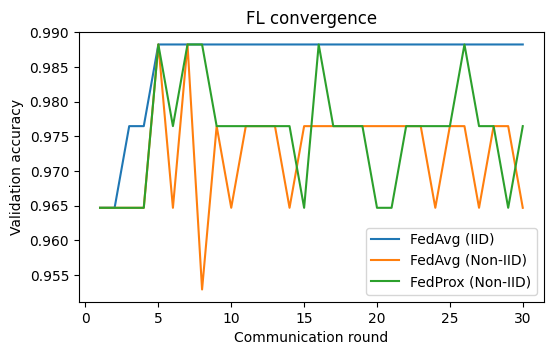

In [27]:
def fedavg_aggregate(states, sizes):
    w = np.array(sizes, dtype=float); w = w / w.sum()
    avg = copy.deepcopy(states[0])
    for k in avg:
        avg[k] = sum(float(wi) * s[k] for s, wi in zip(states, w))
    return avg

def run_federated(clients, hp, rounds, local_epochs, mu=0.0, seed=SEED, track=True):
    set_seed(seed)
    gm = CustomNet(clients[0]["Xtr"].shape[1], hp["hidden"], hp["n_blocks"], hp["dropout"])
    hist = []
    for r in range(rounds):
        gparams = [p.detach().clone() for p in gm.parameters()]
        states, sizes = [], []
        for c in clients:
            local = copy.deepcopy(gm)
            train_model(local, c["Xtr"], c["ytr"], epochs=local_epochs, lr=hp["lr"], wd=hp["wd"],
                        bs=hp["bs"], prox_mu=mu, global_params=gparams)
            states.append(copy.deepcopy(local.state_dict())); sizes.append(len(c["ytr"]))
        gm.load_state_dict(fedavg_aggregate(states, sizes))
        if track:
            pv = predict_proba(gm, X_va_h)
            hist.append(dict(round=r + 1, val_loss=log_loss(y_va, np.clip(pv, 1e-6, 1 - 1e-6)),
                             val_acc=accuracy_score(y_va, pv >= 0.5)))
    return gm, pd.DataFrame(hist)

HP_FL = HP_BEST
FL_SEEDS = [SEED, SEED + 1] if FAST else [SEED, SEED + 1, SEED + 2]
settings = [("FedAvg (IID)", clients_iid, 0.0), ("FedAvg (Non-IID)", clients_non, 0.0), ("FedProx (Non-IID)", clients_non, 0.05)]
fl_models, fl_hist, fl_rows = {}, {}, []
for name, cl, mu in settings:
    t0 = time.time()
    for s in FL_SEEDS:
        gm, hist = run_federated(cl, HP_FL, FL_ROUNDS, LOCAL_EPOCHS, mu=mu, seed=s, track=(s == SEED))
        if s == SEED:
            fl_models[name], fl_hist[name] = gm, hist          # প্রথম seed-এর মডেল পরের ধাপে (personalization, XAI) যাবে
        fl_rows.append({"setting": name, "seed": s, **compute_metrics(y_te, predict_proba(gm, X_te_h), 0.5)})
    print(f"{name}: {len(FL_SEEDS)} seed × {FL_ROUNDS} round শেষ ({time.time()-t0:.0f}s)")

# Centralized reference (একই HP): SMOTE সহ ও ছাড়া
set_seed(SEED)
centralized = {"Centralized (SMOTE)": final_model,
               "Centralized (no SMOTE)": build_and_train(HP_BEST, X_tr_h_unbal, y_train, X_va_h, y_va)}
for name, m in centralized.items():
    fl_rows.append({"setting": name, "seed": SEED, **compute_metrics(y_te, predict_proba(m, X_te_h), 0.5)})

fl_raw = pd.DataFrame(fl_rows)
mets = ["accuracy", "sensitivity", "specificity", "f1", "auc", "brier"]
agg = fl_raw.groupby("setting", sort=False)[mets].agg(["mean", "std"])
fl_summary = pd.DataFrame({m: [f"{agg.loc[s, (m, 'mean')]:.4f} ± {np.nan_to_num(agg.loc[s, (m, 'std')]):.4f}" for s in agg.index]
                           for m in mets}, index=agg.index)
print("\n📊 Global hold-out test, thr 0.5 — mean ± std over seeds (Centralized: একটি seed, std = 0):")
display(fl_summary)
fl_raw.to_csv(os.path.join(OUT_DIR, "fl_results_per_seed.csv"), index=False)

plt.figure(figsize=(6, 3.5))
for name, h in fl_hist.items():
    plt.plot(h["round"], h["val_acc"], label=name)
plt.xlabel("Communication round"); plt.ylabel("Validation accuracy"); plt.legend(); plt.title("FL convergence")
savefig("07_fl_convergence.png"); plt.show()

## 🧪 ধাপ ১৫: Non-IID Client Characterization
প্রতিটি client-এর data কতটা আলাদা — তা সংখ্যায় মাপা:
- **Label skew:** malignant অনুপাত ও global অনুপাত থেকে **Jensen–Shannon distance**
- **Feature shift:** global train-এর সাপেক্ষে প্রতিটি feature-এর গড় **Wasserstein distance**
- IID বনাম Non-IID পাশাপাশি দেখানো হবে।


=== IID clients === (গড় label-skew=0.002, গড় feature-shift=0.097)


,client,n_train,benign,malignant,malignant_ratio,label_skew_JS,feature_shift_W,n_val,n_test
0,0,99,62,37,0.374,0.002,0.095,21,21
1,1,100,63,37,0.370,0.002,0.099,21,22
2,2,99,62,37,0.374,0.002,0.091,21,21
3,3,100,63,37,0.370,0.002,0.104,22,22



=== Non-IID clients === (গড় label-skew=0.277, গড় feature-shift=0.368)


,client,n_train,benign,malignant,malignant_ratio,label_skew_JS,feature_shift_W,n_val,n_test
0,0,48,7,41,0.854,0.433,0.622,10,10
1,1,208,174,34,0.163,0.202,0.231,44,45
2,2,54,44,10,0.185,0.178,0.262,11,11
3,3,88,25,63,0.716,0.296,0.359,20,20


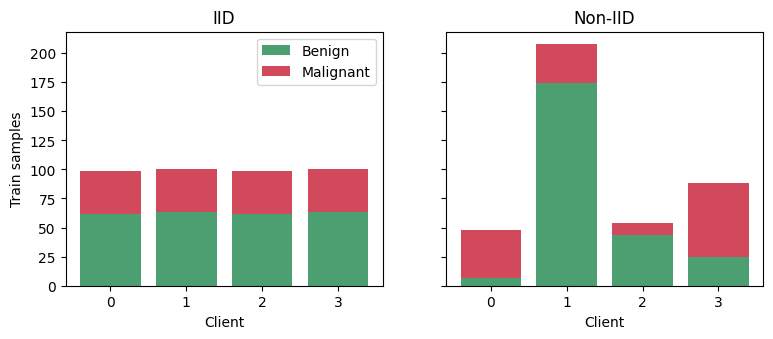

In [28]:
def characterize(clients, title):                                    # client-এর বৈশিষ্ট্য টেবিল
    g_ratio = y_train.mean()                                            # global malignant অনুপাত
    rows = []
    for c in clients:
        n, m = len(c["ytr"]), int(c["ytr"].sum())                    # সংখ্যা ও malignant
        js = jensenshannon([1 - c["ytr"].mean(), c["ytr"].mean()], [1 - g_ratio, g_ratio], base=2)   # label skew
        wd = np.mean([wasserstein_distance(c["Xtr"][:, j], X_tr_h_unbal[:, j]) for j in range(X_tr_h.shape[1])])   # feature shift
        rows.append(dict(client=c["id"], n_train=n, benign=n - m, malignant=m, malignant_ratio=round(m / n, 3),
                         label_skew_JS=round(float(js), 3), feature_shift_W=round(float(wd), 3),
                         n_val=len(c["yva"]), n_test=len(c["yte"])))
    t = pd.DataFrame(rows)
    print(f"\n=== {title} === (গড় label-skew={t.label_skew_JS.mean():.3f}, গড় feature-shift={t.feature_shift_W.mean():.3f})")
    display(t)
    return t

char_iid = characterize(clients_iid, "IID clients")
char_non = characterize(clients_non, "Non-IID clients")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3), sharey=True)          # stacked bar
for a, (t, cl) in zip(ax, [("IID", char_iid), ("Non-IID", char_non)]):
    a.bar(cl.client, cl.benign, label="Benign", color="#4C9F70")
    a.bar(cl.client, cl.malignant, bottom=cl.benign, label="Malignant", color="#D1495B")
    a.set_title(t); a.set_xlabel("Client"); a.set_xticks(cl.client)
ax[0].set_ylabel("Train samples"); ax[0].legend()
savefig("08_noniid_characterization.png"); plt.show()

## 👤 ধাপ ১৬: Personalized FL — v2
Global model (FedAvg Non-IID) প্রতিটি client-এ কয়েকটি **personalization বিকল্প** থেকে বাছাই হয়, client-এর **নিজের validation loss** দেখে:
1. `global (none)` — কিছুই বদলানো নয়
2. `local temperature` — শুধু ১টি scalar দিয়ে local calibration (ছোট ডেটায় সবচেয়ে স্থিতিশীল)
3. `head fine-tune` — শুধু শেষ স্তর + feature-gate fine-tune
4. `full fine-tune + proximal` — পুরো মডেল, global-এর কাছাকাছি থাকার penalty সহ

**Margin rule:** global-এর চেয়ে validation log-loss অন্তত `0.01` ভালো না হলে global-ই থাকে। (v4-এ personalized = global আসত কারণ probability 0/1-এ saturated ছিল ও fine-tune log-loss বাড়াত; v2 সেটা স্পষ্ট দেখায়।)
> ⚠️ প্রতি client-এর test ছোট (≈10–45) — পার্থক্যকে statistical দাবি বানাবেন না।

,client,n_test,chosen,acc_global,acc_personal,brier_global,brier_personal,ece_global,ece_personal
0,0,10,full fine-tune+prox (10 ep),0.9000,0.9000,0.1000,0.0918,0.1000,0.0952
1,1,45,full fine-tune+prox (10 ep),0.9778,0.9778,0.0222,0.0222,0.0222,0.0222
2,2,11,local temperature,0.9091,0.9091,0.0909,0.0856,0.0909,0.0969
3,3,20,global (none),1.0000,1.0000,0.0000,0.0000,0.0000,0.0000


Personalization বেছে নেওয়া হয়েছে 3/4 client-এ (বাকিদের জন্য global model-ই সেরা, যা validation loss-এ প্রমাণিত)।
গড় Accuracy: Global=0.9467 → Personalized=0.9467
গড় Brier   : Global=0.0533 → Personalized=0.0499
গড় ECE     : Global=0.0533 → Personalized=0.0536


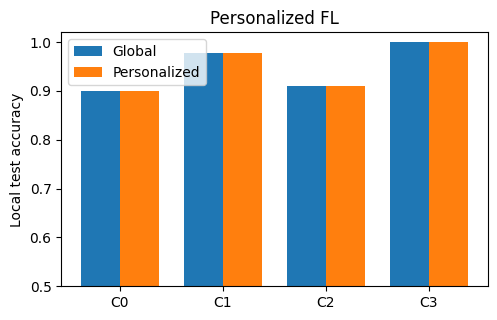

Pooled test accuracy (n=86): Global=0.9651 → Personalized=0.9651
⚠️ প্রতি client-এর test মাত্র 10–45 নমুনা: পার্থক্য কয়েকটি নমুনার সমান — statistical দাবি করবেন না।


In [29]:
class TempWrap(nn.Module):                                           # logits / T (local temperature scaling)
    def __init__(self, base, T):
        super().__init__(); self.base = base; self.T = float(T)
    def forward(self, x):
        return self.base(x) / self.T

def fit_temperature(model, X, yv):                                   # val NLL minimize করে T
    model.eval()
    with torch.no_grad():
        z = model(torch.tensor(np.asarray(X), dtype=torch.float32)).numpy()
    best_l, best_T = float("inf"), 1.0
    for T in np.exp(np.linspace(np.log(0.5), np.log(10.0), 60)):
        p = 1 / (1 + np.exp(-z / T))
        l = log_loss(yv, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1])
        if l < best_l - 1e-9: best_l, best_T = l, T
    return best_T

PERS_MARGIN = 0.01                                                   # global-এর চেয়ে অন্তত এতটা ভালো হতে হবে

def personalize(global_model, c, hp):                                # একটি client-এর personalization
    cands = {"global (none)": copy.deepcopy(global_model)}
    cands["local temperature"] = TempWrap(copy.deepcopy(global_model), fit_temperature(global_model, c["Xva"], c["yva"]))
    g_params = [p.detach().clone() for p in global_model.parameters()]
    for e in (2, 5, 10):
        m = copy.deepcopy(global_model)
        for n_, p_ in m.named_parameters():
            p_.requires_grad = n_.startswith("out") or n_.startswith("gate")      # শুধু head + gate
        set_seed(SEED); train_model(m, c["Xtr"], c["ytr"], epochs=e, lr=hp["lr"] * 0.5, wd=hp["wd"], bs=hp["bs"])
        cands[f"head fine-tune ({e} ep)"] = m
        m2 = copy.deepcopy(global_model)
        set_seed(SEED); train_model(m2, c["Xtr"], c["ytr"], epochs=e, lr=hp["lr"] * 0.5, wd=hp["wd"], bs=hp["bs"],
                                    prox_mu=0.05, global_params=g_params)
        cands[f"full fine-tune+prox ({e} ep)"] = m2
    losses = {k: log_loss(c["yva"], np.clip(predict_proba(m, c["Xva"]), 1e-6, 1 - 1e-6), labels=[0, 1]) for k, m in cands.items()}
    base = losses["global (none)"]
    best_k = min(losses, key=losses.get)
    choice = best_k if losses[best_k] < base - PERS_MARGIN else "global (none)"
    return cands[choice], choice

gm_non = fl_models["FedAvg (Non-IID)"]                               # global Non-IID মডেল
rows, pers_models = [], {}
for c in clients_non:
    pm, choice = personalize(gm_non, c, HP_FL); pers_models[c["id"]] = pm
    pg, pp = predict_proba(gm_non, c["Xte"]), predict_proba(pm, c["Xte"])   # local test প্রেডিকশন
    mg, mp = compute_metrics(c["yte"], pg, 0.5), compute_metrics(c["yte"], pp, 0.5)
    rows.append(dict(client=c["id"], n_test=len(c["yte"]), chosen=choice,
                     acc_global=mg["accuracy"], acc_personal=mp["accuracy"],
                     brier_global=mg["brier"], brier_personal=mp["brier"],
                     ece_global=mg["ece"], ece_personal=mp["ece"]))
pers_table = pd.DataFrame(rows).round(4)
display(pers_table)
n_changed = int((pers_table.chosen != "global (none)").sum())
print(f"Personalization বেছে নেওয়া হয়েছে {n_changed}/{len(pers_table)} client-এ (বাকিদের জন্য global model-ই সেরা, যা validation loss-এ প্রমাণিত)।")
print(f"গড় Accuracy: Global={pers_table.acc_global.mean():.4f} → Personalized={pers_table.acc_personal.mean():.4f}")
print(f"গড় Brier   : Global={pers_table.brier_global.mean():.4f} → Personalized={pers_table.brier_personal.mean():.4f}")
print(f"গড় ECE     : Global={pers_table.ece_global.mean():.4f} → Personalized={pers_table.ece_personal.mean():.4f}")

x = np.arange(len(pers_table)); w = 0.38                             # তুলনামূলক বার চার্ট
plt.figure(figsize=(5.5, 3.3))
plt.bar(x - w / 2, pers_table.acc_global, w, label="Global"); plt.bar(x + w / 2, pers_table.acc_personal, w, label="Personalized")
plt.xticks(x, [f"C{i}" for i in pers_table.client]); plt.ylim(0.5, 1.02); plt.ylabel("Local test accuracy"); plt.legend()
plt.title("Personalized FL"); savefig("09_personalized_fl.png"); plt.show()
pool_y = np.concatenate([c["yte"] for c in clients_non])
pool_g = np.concatenate([predict_proba(gm_non, c["Xte"]) for c in clients_non]) >= 0.5
pool_p = np.concatenate([predict_proba(pers_models[c["id"]], c["Xte"]) for c in clients_non]) >= 0.5
print(f"Pooled test accuracy (n={len(pool_y)}): Global={(pool_g == pool_y).mean():.4f} → Personalized={(pool_p == pool_y).mean():.4f}")
print("⚠️ প্রতি client-এর test মাত্র 10–45 নমুনা: পার্থক্য কয়েকটি নমুনার সমান — statistical দাবি করবেন না।")

## 🔀 ধাপ ১৭: Cross-Client Generalization (Leave-One-Client-Out)
একটি client-কে **পুরোপুরি বাদ** দিয়ে বাকিদের নিয়ে FL train করা হয়, তারপর বাদ-পড়া (unseen) client-এর test data-তে মডেল পরীক্ষা হয়।
এতে বোঝা যায় নতুন হাসপাতালে মডেল কতটা কাজ করবে।

In [30]:
rows = []
for held in clients_non:
    others = [c for c in clients_non if c["id"] != held["id"]]       # বাকি client
    m_loco, _ = run_federated(others, HP_FL, LOCO_ROUNDS, LOCAL_EPOCHS, track=False)   # held-out ছাড়া FL
    p_un = predict_proba(m_loco, held["Xte"])                        # unseen client-এর test
    p_seen = predict_proba(gm_non, held["Xte"])                      # seen (সবাইকে নিয়ে train) মডেল
    mu_, ms_ = compute_metrics(held["yte"], p_un, 0.5), compute_metrics(held["yte"], p_seen, 0.5)
    rows.append(dict(held_out_client=held["id"], n_test=len(held["yte"]),
                     acc_unseen=mu_["accuracy"], acc_seen=ms_["accuracy"], gap=ms_["accuracy"] - mu_["accuracy"],
                     auc_unseen=mu_["auc"], auc_seen=ms_["auc"]))
loco_table = pd.DataFrame(rows).round(4)
display(loco_table)
print(f"গড় Accuracy — Unseen: {loco_table.acc_unseen.mean():.4f} | Seen: {loco_table.acc_seen.mean():.4f} | গড় gap: {loco_table.gap.mean():.4f}")

,held_out_client,n_test,acc_unseen,acc_seen,gap,auc_unseen,auc_seen
0,0,10,0.9000,0.9000,0.0,1.0,1.0000
1,1,45,0.9778,0.9778,0.0,1.0,0.9868
2,2,11,0.9091,0.9091,0.0,1.0,0.9444
3,3,20,1.0000,1.0000,0.0,1.0,1.0000


গড় Accuracy — Unseen: 0.9467 | Seen: 0.9467 | গড় gap: 0.0000


## 🔍 ধাপ ১৮: Federated XAI — v2 (একই মডেল, একই data)
v4-এ federated importance (FL মডেল, client **train** data) বনাম centralized importance (**অন্য** মডেল, **test** data) তুলনা হচ্ছিল — দুটো আলাদা জিনিস, তাই ρ অর্থহীন ছিল। v2-এ:
1. প্রতিটি client **নিজের held-out test data**-য় **FL global model**-এর permutation importance বের করে (শুধু importance vector server-এ যায়) → size-weighted average = **Federated importance**।
2. **Fidelity check:** একই FL model-এর **pooled test** importance-এর সাথে Federated importance-এর Spearman ρ (aggregation কতটা বিশ্বস্ত)।
3. **Model-to-model:** FL model বনাম Centralized model — **একই pooled test data**-য় importance-এর ρ।
4. দুটো ρ-এর **bootstrap 95% CI** (test নমুনা resample)।
5. বাড়তি: **SHAP** ও শেখা **feature gate**।

Aggregation fidelity  ρ(Federated-avg, Pooled)  — SAME FL model : 0.840  (bootstrap 95% CI [-0.16, 0.94])
Model-to-model        ρ(FL model, Centralized)  — SAME test data: 0.627  (bootstrap 95% CI [0.07, 0.79])


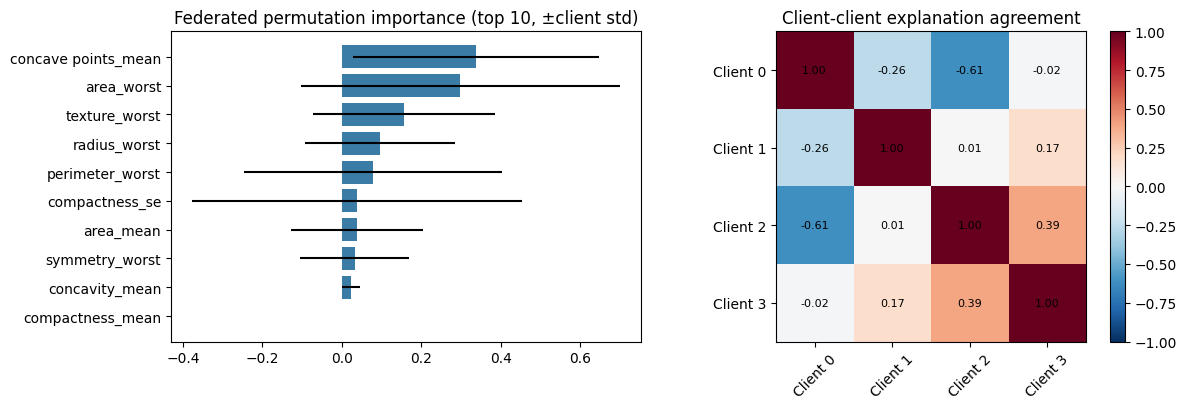

গড় client-agreement (off-diagonal ρ) = -0.052  (client test ছোট ⇒ noisy)


In [31]:
from scipy.stats import spearmanr                                    # rank correlation

def perm_importance(model, X, yv, n_repeats=10, seed=0):             # Permutation importance (Δ log-loss)
    rng = np.random.RandomState(seed)
    base = log_loss(yv, np.clip(predict_proba(model, X), 1e-6, 1 - 1e-6), labels=[0, 1])   # বেস loss
    imp = np.zeros(X.shape[1])
    for j in range(X.shape[1]):                                      # প্রতিটি ফিচার
        ds = []
        for _ in range(n_repeats):
            Xp = X.copy(); Xp[:, j] = rng.permutation(Xp[:, j])      # ফিচার j এলোমেলো করা
            ds.append(log_loss(yv, np.clip(predict_proba(model, Xp), 1e-6, 1 - 1e-6), labels=[0, 1]) - base)
        imp[j] = np.mean(ds)                                         # loss-এর বৃদ্ধি = importance
    return imp

# ---- (1) Federated importance: FL model, each client's OWN held-out test data ----
client_imp = [perm_importance(gm_non, c["Xte"], c["yte"], n_repeats=20, seed=c["id"]) for c in clients_non]
imp_mat = pd.DataFrame(client_imp, index=[f"Client {c['id']}" for c in clients_non], columns=sel_hybrid)
n_te_c = np.array([len(c["yte"]) for c in clients_non], dtype=float); wts = n_te_c / n_te_c.sum()
fed_imp = pd.Series((imp_mat.values * wts[:, None]).sum(0), index=sel_hybrid)
fed_std = imp_mat.std(axis=0)

# ---- (2) Pooled importance of the SAME FL model, and (3) centralized model — SAME pooled test data ----
X_pool = np.vstack([c["Xte"] for c in clients_non]); y_pool = np.concatenate([c["yte"] for c in clients_non])
pooled_fl = pd.Series(perm_importance(gm_non, X_pool, y_pool, n_repeats=20, seed=0), index=sel_hybrid)
central_imp = pd.Series(perm_importance(final_model, X_pool, y_pool, n_repeats=20, seed=0), index=sel_hybrid)
rho_fid = spearmanr(fed_imp.values, pooled_fl.values).correlation        # aggregation fidelity (same model)
rho_m2m = spearmanr(pooled_fl.values, central_imp.values).correlation    # FL vs centralized (same data)

# ---- bootstrap CI (resample within each client's test set) ----
rng_b = np.random.RandomState(SEED)
bf, bm = [], []
for b in range(XAI_BOOT):
    idxs = [rng_b.choice(len(c["yte"]), len(c["yte"]), replace=True) for c in clients_non]
    cimp = [perm_importance(gm_non, c["Xte"][ix], c["yte"][ix], n_repeats=3, seed=b) for c, ix in zip(clients_non, idxs)]
    fed_b = (np.array(cimp) * wts[:, None]).sum(0)
    Xb_ = np.vstack([c["Xte"][ix] for c, ix in zip(clients_non, idxs)]); yb_ = np.concatenate([c["yte"][ix] for c, ix in zip(clients_non, idxs)])
    pfl_b = perm_importance(gm_non, Xb_, yb_, n_repeats=3, seed=b); cen_b = perm_importance(final_model, Xb_, yb_, n_repeats=3, seed=b)
    bf.append(spearmanr(fed_b, pfl_b).correlation); bm.append(spearmanr(pfl_b, cen_b).correlation)
ci_f = np.nanpercentile(bf, [2.5, 97.5]); ci_m = np.nanpercentile(bm, [2.5, 97.5])
print(f"Aggregation fidelity  ρ(Federated-avg, Pooled)  — SAME FL model : {rho_fid:.3f}  (bootstrap 95% CI [{ci_f[0]:.2f}, {ci_f[1]:.2f}])")
print(f"Model-to-model        ρ(FL model, Centralized)  — SAME test data: {rho_m2m:.3f}  (bootstrap 95% CI [{ci_m[0]:.2f}, {ci_m[1]:.2f}])")

top = fed_imp.sort_values(ascending=False).head(10)                  # top-10
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].barh(top.index[::-1], top.values[::-1], xerr=fed_std[top.index].values[::-1], color="#3A7CA5")
ax[0].set_title("Federated permutation importance (top 10, ±client std)")
cm = imp_mat.T.corr(method="spearman")                               # client-client সামঞ্জস্য
im = ax[1].imshow(cm.values, vmin=-1, vmax=1, cmap="RdBu_r")
ax[1].set_xticks(range(len(cm))); ax[1].set_xticklabels(cm.columns, rotation=45); ax[1].set_yticks(range(len(cm))); ax[1].set_yticklabels(cm.index)
for i in range(len(cm)):
    for j in range(len(cm)): ax[1].text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[1].set_title("Client-client explanation agreement"); plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); savefig("10_federated_xai.png"); plt.show()
print(f"গড় client-agreement (off-diagonal ρ) = {(cm.values.sum() - len(cm)) / (len(cm) * (len(cm) - 1)):.3f}  (client test ছোট ⇒ noisy)")

🔑 FL global মডেলের Feature-gate (বড় = বেশি গুরুত্ব):


,gate
area_worst,1.200
concave points_mean,1.157
texture_worst,1.092
radius_se,1.077
radius_worst,1.068
concavity_mean,1.060
perimeter_worst,1.024
area_se,1.024


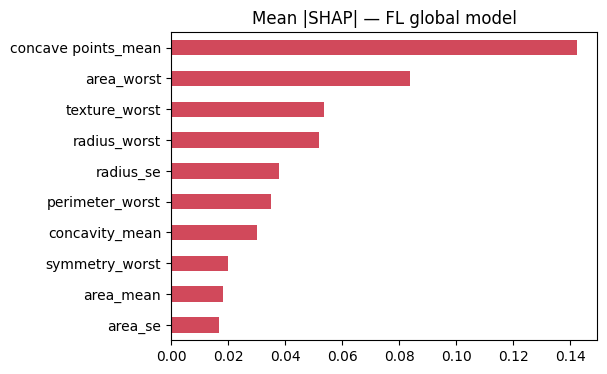

In [32]:
# ---------- মডেলের শেখা Feature Gate ও SHAP (global FL model) ----------
gate_vals = pd.Series((2 * torch.sigmoid(gm_non.gate)).detach().numpy(), index=sel_hybrid).sort_values(ascending=False)   # gate মান
print("🔑 FL global মডেলের Feature-gate (বড় = বেশি গুরুত্ব):")
display(gate_vals.round(3).head(8).to_frame("gate"))

try:                                                                 # SHAP (সময় বাঁচাতে ছোট sample)
    import shap
    bg = shap.sample(X_tr_h, 40, random_state=SEED)                  # background data
    expl = shap.KernelExplainer(lambda Z: predict_proba(gm_non, Z), bg)   # Kernel SHAP
    sv = expl.shap_values(X_te_h[:30], nsamples=100, silent=True)    # ৩০টি test নমুনা
    sv = np.asarray(sv).reshape(30, -1)                              # আকার ঠিক করা
    shap_imp = pd.Series(np.abs(sv).mean(0), index=sel_hybrid).sort_values(ascending=False)   # গড় |SHAP|
    plt.figure(figsize=(5.5, 4)); shap_imp.head(10)[::-1].plot(kind="barh", color="#D1495B")
    plt.title("Mean |SHAP| — FL global model"); savefig("11_shap_global.png"); plt.show()
except Exception as e:
    print("SHAP ধাপ skip (ঐচ্ছিক):", e)

## 🔄 ধাপ ১৯: Counterfactual Explainability — v2 (plausibility-constrained)
প্রশ্ন: *"এই রোগীর কোন মান বদলালে মডেলের সিদ্ধান্ত উল্টে যেত?"*

v4-এর সমস্যা: গড়ে ~13/16 feature বদলাত; `radius/perimeter/area` প্রায় সম্পূর্ণ correlated (ρ≈0.99) হওয়ায় আলাদা আলাদা বদলানো বাস্তবে সম্ভব নয়। v2:
- **Feature group:** |ρ| ≥ 0.90 হলে feature-গুলো **একসাথে** (একই standardized shift, correlation-এর চিহ্ন অনুযায়ী) বদলায় → sparsity মাপা হয় **group সংখ্যায়**।
- **Plausibility:** প্রতিটি মান **training range**-এর ভেতরে clip।
- **L1 penalty (group-level)** + greedy pruning।
- **সৎ রিপোর্টিং:** মূল উন্নতি হলো *plausibility* (সব মান range-এর ভেতরে, manifold-এর কাছাকাছি)। Sparsity না কমলে (যেমন Malignant→Benign উল্টাতে বড় পরিবর্তন লাগে) paper-এ সেটাই লিখুন।
- মাপকাঠি: Validity, Sparsity (group ও feature), Proximity (L1), **In-range %**, **data-manifold দূরত্ব** (training নমুনার nearest-neighbour)।
- **Before/After** টেবিল: unconstrained (v4 পদ্ধতি) বনাম constrained (v2)।
> এটি মডেলের আচরণ বোঝার টুল — চিকিৎসা পরামর্শ নয়।

In [33]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.neighbors import NearestNeighbors

# ---------- feature groups (|rho| >= 0.90 → move together) & plausible bounds ----------
Xs_sel = X_train_s[sel_hybrid].values                                # train, standardized, Hybrid ফিচার
corr_ = np.corrcoef(Xs_sel.T)
dist_ = 1 - np.abs(corr_); np.fill_diagonal(dist_, 0)
grp_ = fcluster(linkage(squareform(dist_, checks=False), method="average"), t=0.10, criterion="distance")
G_ = int(grp_.max()); F_ = len(sel_hybrid)
CF_M = np.zeros((G_, F_))                                            # group → feature mapping (sign-aware)
for g in range(1, G_ + 1):
    members = np.where(grp_ == g)[0]; anchor = members[0]
    for j in members:
        CF_M[g - 1, j] = 1.0 if corr_[anchor, j] >= 0 else -1.0
CF_LO, CF_HI = Xs_sel.min(0), Xs_sel.max(0)                          # training range (standardized)
print(f"Feature groups (|ρ|≥0.90): {G_} groups from {F_} features")
for g in range(1, G_ + 1):
    mem = [sel_hybrid[j] for j in np.where(grp_ == g)[0]]
    if len(mem) > 1: print(f"  group {g}: {mem}")

def generate_counterfactual(model, x_std, target, M, lo, hi, lambda_l1=0.10, steps=500, lr=0.05, margin=0.05):
    # M: (G × F) group→feature matrix; lo/hi: allowed range. Returns (delta in feature space, found)
    model.eval()
    x0 = torch.tensor(np.asarray(x_std), dtype=torch.float32).reshape(1, -1)
    Mt = torch.tensor(np.asarray(M), dtype=torch.float32)
    lot, hit = torch.tensor(np.asarray(lo), dtype=torch.float32), torch.tensor(np.asarray(hi), dtype=torch.float32)
    g = torch.zeros(1, Mt.shape[0], requires_grad=True)
    opt = torch.optim.Adam([g], lr=lr)
    tgt = torch.tensor([float(target)])
    def make(gv):                                                    # group shift → clipped candidate point
        return torch.minimum(torch.maximum(x0 + gv @ Mt, lot), hit)
    def ok(gv):
        with torch.no_grad():
            p = torch.sigmoid(model(make(gv))).item()
        return (p >= 0.5 + margin) if target == 1 else (p <= 0.5 - margin)
    found = False
    for _ in range(steps):
        opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(model(make(g)), tgt) + lambda_l1 * g.abs().sum()
        loss.backward(); opt.step()
        if ok(g.detach()):
            found = True; break
    gd = g.detach().clone()
    if not found:
        return (make(gd) - x0).detach().squeeze(0).numpy(), False
    for j in torch.argsort(gd.abs().squeeze(0)):                     # ছোট group-পরিবর্তন আগে বাদ
        t = gd.clone(); t[0, j] = 0.0
        if ok(t): gd = t
    return (make(gd) - x0).detach().squeeze(0).numpy(), True

nn_ = NearestNeighbors(n_neighbors=1).fit(Xs_sel)                    # data-manifold দূরত্বের জন্য
INF = np.full(F_, np.inf)

final_model.eval()
pred_te = (predict_proba(final_model, X_te_h) >= 0.5).astype(int)    # test-এ প্রেডিকশন
def run_cf(M, lo, hi, lam, n=40):
    rows_, ex_ = [], []
    for i in range(min(n, len(X_te_h))):
        tgt = 1 - pred_te[i]
        d, ok_ = generate_counterfactual(final_model, X_te_h[i], tgt, M, lo, hi, lambda_l1=lam)
        xc = X_te_h[i] + d
        n_feat = int((np.abs(d) > 1e-6).sum())
        n_grp = int(sum(np.any(np.abs(d[grp_ == g]) > 1e-6) for g in range(1, G_ + 1)))
        in_rng = bool(np.all(xc >= CF_LO - 1e-6) and np.all(xc <= CF_HI + 1e-6))
        d0 = nn_.kneighbors(X_te_h[i][None, :])[0][0, 0]; d1 = nn_.kneighbors(xc[None, :])[0][0, 0]
        rows_.append(dict(valid=ok_, n_features=n_feat, n_groups=n_grp, l1=float(np.abs(d).sum()), in_range=in_rng, nn_ratio=d1 / (d0 + 1e-9)))
        if ok_: ex_.append((i, tgt, d))
    return pd.DataFrame(rows_), ex_

cf_unc, _ = run_cf(np.eye(F_), -INF, INF, 0.05)                      # v4 পদ্ধতি (unconstrained)
cf_df, cf_examples = run_cf(CF_M, CF_LO, CF_HI, 0.25)                # v2 (constrained)
def summ(df_):
    v = df_[df_.valid]
    return dict(validity_pct=100 * df_.valid.mean(), groups_changed=v.n_groups.mean(), features_changed=v.n_features.mean(),
                mean_L1=v.l1.mean(), in_training_range_pct=100 * v.in_range.mean(), manifold_dist_ratio=v.nn_ratio.mean())
cf_cmp = pd.DataFrame({"unconstrained (v4 method)": summ(cf_unc), "constrained (v2)": summ(cf_df)}).T.round(2)
print("Counterfactual — before/after (লক্ষ্য: কম group, সব মান range-এর ভেতরে, manifold-এর কাছাকাছি):")
display(cf_cmp)

# ---------- একটি উদাহরণ (মূল একক-এ) ----------
mu_sel, sd_sel = scaler_all.mean_[sel_idx], scaler_all.scale_[sel_idx]   # মূল একক-এ ফেরার জন্য
if len(cf_examples):
    i0, tgt0, d0 = cf_examples[0]
    chg = np.where(np.abs(d0) > 1e-6)[0]
    ex = pd.DataFrame({"feature": np.array(sel_hybrid)[chg],
                       "original": (X_te_h[i0] * sd_sel + mu_sel)[chg],
                       "counterfactual": ((X_te_h[i0] + d0) * sd_sel + mu_sel)[chg]})
    ex["change_%"] = (ex.counterfactual / ex.original - 1) * 100
    print(f"\nরোগী #{i0}: মডেলের প্রেডিকশন {['Benign','Malignant'][1 - tgt0]} → counterfactual {['Benign','Malignant'][tgt0]}")
    display(ex.round(3))
else:
    print("কোনো valid counterfactual পাওয়া যায়নি — lambda_l1 কমান বা steps বাড়ান।")

Feature groups (|ρ|≥0.90): 10 groups from 15 features
  group 3: ['concavity_mean', 'concave points_mean']
  group 7: ['area_mean', 'radius_worst', 'perimeter_worst', 'area_worst']
  group 8: ['radius_se', 'area_se']
Counterfactual — before/after (লক্ষ্য: কম group, সব মান range-এর ভেতরে, manifold-এর কাছাকাছি):


,validity_pct,groups_changed,features_changed,mean_L1,in_training_range_pct,manifold_dist_ratio
unconstrained (v4 method),100.0,7.60,11.38,9.04,62.5,1.61
constrained (v2),100.0,6.62,11.60,8.88,100.0,1.48



রোগী #0: মডেলের প্রেডিকশন Malignant → counterfactual Benign


,feature,original,counterfactual,change_%
0,area_mean,1214.000,422.423,-65.204
1,concavity_mean,0.251,0.212,-15.433
2,concave points_mean,0.129,0.110,-14.582
3,radius_se,0.736,0.201,-72.736
4,area_se,97.070,13.316,-86.282
5,radius_worst,26.730,15.870,-40.630
6,texture_worst,26.390,12.660,-52.029
7,perimeter_worst,174.900,99.452,-43.138
8,area_worst,2232.000,963.283,-56.842
9,smoothness_worst,0.144,0.091,-37.031


## 🎲 ধাপ ২০: Uncertainty-Aware Prediction & Calibration — v2
- **MC-Dropout:** dropout চালু রেখে `T` বার predict → গড় = prediction, **std = epistemic uncertainty**
- **Calibration — v2:** তিনটি বিকল্প (`raw`, `temperature`, `Platt`) **validation set-এর ভেতরেই 5-fold CV-এ** তুলনা (out-of-fold log-loss)। raw-এর চেয়ে কমপক্ষে ৫% ভালো না হলে **raw-ই থাকে** (v4-এ Platt Brier খারাপ করেছিল)। Test-এ তিনটিরই Brier/ECE শুধু রিপোর্ট করা হয়, বাছাই করা হয় না।
- **Referral rule:** uncertainty বেশি বা probability ০.৩৫–০.৬৫-এর মধ্যে হলে **"Needs Review"**
- **Accuracy–Coverage** কার্ভ: অনিশ্চিত কেস বাদ দিলে accuracy বাড়ে কিনা

Validation out-of-fold log-loss: {'raw': 0.0622, 'temp': 0.0603, 'platt': 0.1281} → বাছাই: raw (a=1.000, b=0.000)
Test Brier / ECE (বাছাই হয়েছে validation থেকে, test থেকে নয়):
  raw    Brier=0.0099  ECE=0.0287   ← ব্যবহৃত
  temp   Brier=0.0086  ECE=0.0130
  platt  Brier=0.0151  ECE=0.0248
MC-Dropout Test accuracy = 0.9884 (85/86)
Needs-Review হার = 10.5% (9/86)
Accuracy (confident) = 1.0000  |  Accuracy (flagged) = 0.8889


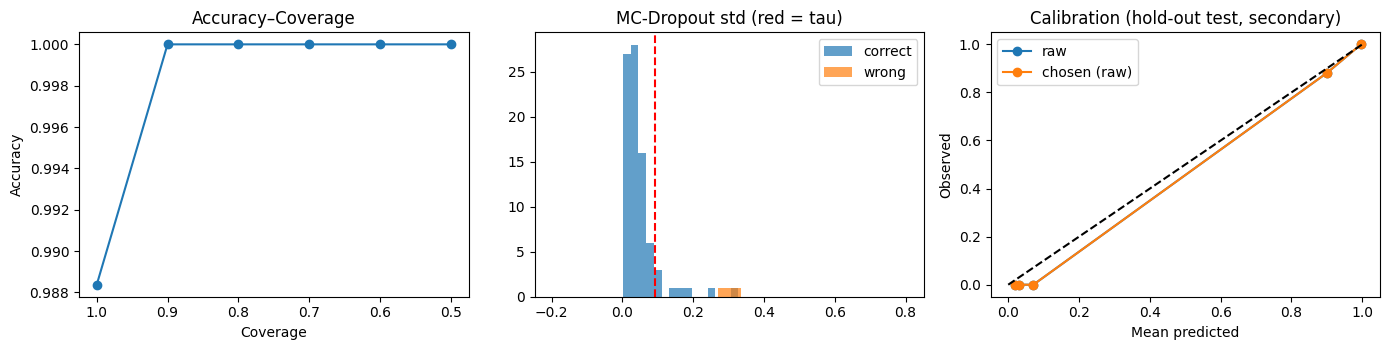

In [34]:
def mc_dropout_probs(model, X, T=50):                                # MC-Dropout: T বার stochastic predict
    model.train()                                                    # dropout চালু (LayerNorm-এ batch stat নেই, তাই নিরাপদ)
    with torch.no_grad():
        xt = torch.tensor(np.asarray(X), dtype=torch.float32)
        probs = torch.stack([torch.sigmoid(model(xt)) for _ in range(T)]).numpy()   # (T, N)
    model.eval()
    return probs

def platt_scale(p, a, b):                                            # σ(a·logit(p)+b)  (temperature scaling = a=1/T, b=0)
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return 1 / (1 + np.exp(-(a * np.log(p / (1 - p)) + b)))

def to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

set_seed(SEED)
pr_va, pr_te = mc_dropout_probs(final_model, X_va_h, MC_T), mc_dropout_probs(final_model, X_te_h, MC_T)
mean_va, std_va = pr_va.mean(0), pr_va.std(0)                        # val: গড় ও std
mean_te, std_te = pr_te.mean(0), pr_te.std(0)                        # test: গড় ও std

# ---------- calibrator selection by CV INSIDE the validation set ----------
def fit_ab(z, yv, mode):
    if mode == "raw": return 1.0, 0.0
    if mode == "temp":
        best_l, best_T = float("inf"), 1.0
        for T in np.exp(np.linspace(np.log(0.5), np.log(10.0), 80)):
            l = log_loss(yv, np.clip(1 / (1 + np.exp(-z / T)), 1e-6, 1 - 1e-6), labels=[0, 1])
            if l < best_l - 1e-9: best_l, best_T = l, T
        return 1.0 / best_T, 0.0
    m_ = LogisticRegression(C=1e6).fit(z.reshape(-1, 1), yv)         # Platt
    return float(m_.coef_[0, 0]), float(m_.intercept_[0])

modes = ["raw", "temp", "platt"]
z_va = to_logit(mean_va)
oof_cal = {m: np.zeros(len(y_va)) for m in modes}
skf_ = StratifiedKFold(n_splits=min(5, int(np.bincount(y_va).min())), shuffle=True, random_state=SEED)
for tr_i, te_i in skf_.split(z_va, y_va):
    for m in modes:
        a_, b_ = fit_ab(z_va[tr_i], y_va[tr_i], m)
        oof_cal[m][te_i] = 1 / (1 + np.exp(-(a_ * z_va[te_i] + b_)))
cv_nll = {m: log_loss(y_va, np.clip(oof_cal[m], 1e-6, 1 - 1e-6), labels=[0, 1]) for m in modes}
CALIB = min(cv_nll, key=cv_nll.get)
if CALIB != "raw" and cv_nll[CALIB] > 0.95 * cv_nll["raw"]:           # কমপক্ষে ৫% উন্নতি না হলে raw
    CALIB = "raw"
platt_a_use, platt_b_use = fit_ab(z_va, y_va, CALIB)                 # val-এর পুরো ডেটায় fit
print("Validation out-of-fold log-loss:", {m: round(v, 4) for m, v in cv_nll.items()}, "→ বাছাই:", CALIB, f"(a={platt_a_use:.3f}, b={platt_b_use:.3f})")

cal_all = {m: platt_scale(mean_te, *fit_ab(z_va, y_va, m)) for m in modes}   # শুধু রিপোর্টের জন্য
print("Test Brier / ECE (বাছাই হয়েছে validation থেকে, test থেকে নয়):")
for m in modes:
    print(f"  {m:6s} Brier={brier_score_loss(y_te, cal_all[m]):.4f}  ECE={ece_score(y_te, cal_all[m]):.4f}" + ("   ← ব্যবহৃত" if m == CALIB else ""))
cal_te = cal_all[CALIB]
final_prob_te = cal_te

thr_mc = youden_threshold(y_va, mean_va)
tau = float(np.quantile(std_va, 0.90))                               # uncertainty cutoff (val-এর ৯০ শতাংশ)
REVIEW_BAND = (0.35, 0.65)                                           # অনিশ্চিত probability-র বলয়
def needs_review(p_mean, p_std):                                     # ডাক্তারকে রেফার করার নিয়ম
    return (np.asarray(p_std) > tau) | ((np.asarray(p_mean) >= REVIEW_BAND[0]) & (np.asarray(p_mean) <= REVIEW_BAND[1]))

pred_mc = (mean_te >= thr_mc).astype(int)                            # চূড়ান্ত class
flag = needs_review(mean_te, std_te)                                 # Needs Review পতাকা
correct = (pred_mc == y_te)                                          # সঠিক/ভুল
print(f"MC-Dropout Test accuracy = {correct.mean():.4f} ({correct.sum()}/{len(correct)})")
print(f"Needs-Review হার = {flag.mean()*100:.1f}% ({flag.sum()}/{len(flag)})")
print(f"Accuracy (confident) = {correct[~flag].mean():.4f}  |  Accuracy (flagged) = {correct[flag].mean() if flag.any() else float('nan'):.4f}")

order = np.argsort(std_te)                                           # কম uncertainty আগে
covs = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]
acc_cov = [correct[order[:max(1, int(c * len(order)))]].mean() for c in covs]   # coverage অনুযায়ী accuracy
from sklearn.calibration import calibration_curve                    # calibration plot
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(covs, acc_cov, "o-"); ax[0].invert_xaxis(); ax[0].set_xlabel("Coverage"); ax[0].set_ylabel("Accuracy"); ax[0].set_title("Accuracy–Coverage")
ax[1].hist(std_te[correct], bins=15, alpha=0.7, label="correct"); ax[1].hist(std_te[~correct], bins=15, alpha=0.7, label="wrong")
ax[1].axvline(tau, color="r", ls="--"); ax[1].legend(); ax[1].set_title("MC-Dropout std (red = tau)")
for nm, pp in [("raw", mean_te), (f"chosen ({CALIB})", cal_te)]:
    fp_, mp_ = calibration_curve(y_te, pp, n_bins=5, strategy="quantile"); ax[2].plot(mp_, fp_, "o-", label=nm)
ax[2].plot([0, 1], [0, 1], "k--"); ax[2].legend(); ax[2].set_xlabel("Mean predicted"); ax[2].set_ylabel("Observed"); ax[2].set_title("Calibration (hold-out test, secondary)")
plt.tight_layout(); savefig("12_uncertainty_calibration.png"); plt.show()

## 🧱 ধাপ ২১: Ablation Study (Repeated CV, **সব tuning fold-এর ভেতরে**) — v2
v4-এ সমস্যা: `HP_BEST` ও `params_1se` মূল train/val-এ tune হয়েছিল, কিন্তু ablation CV পুরো 569 নমুনায় চলত — ফলে কিছু test-fold নমুনা আগে tuning-এ দেখা ছিল ("Full" model-এর পক্ষে হালকা optimism)।

v2: 5-fold × `ABL_REPEATS` repeated CV (পুরো ডেটা), এবং **প্রতি fold-এর inner-train-এর ভেতরে**:
- scaler · SMOTE · **feature selection (RFE ∪ RF ∪ bootstrap-stable Elastic-Net, EN-এর hyper-parameter-ও in-fold tuned)**
- **Custom MLP HP: প্রতি (fold, feature-set)-এ Optuna `ABL_TRIALS` trial** (inner validation log-loss)
- প্রতি variant একই fold, threshold 0.5, **paired Wilcoxon** (বনাম Full) + Holm।

| Variant | কী বদলানো হয় |
|---|---|
| Full | Hybrid-FS + SMOTE + Tuned HP + Gate + Residual |
| No SMOTE | SMOTE বাদ |
| No FS | সব ৩০ ফিচার |
| RFE only / RF only / L1-sparse only | Hybrid-এর বদলে একক FS |
| Default HP | Tuning বাদ |
| No Gate / No Residual | architecture-এর অংশ বাদ |

> HP প্রতি feature-set-এ আলাদা tune হয় (Hybrid-এর জন্য tune করা HP দিয়ে "No FS" চালালে No-FS-এর বিরুদ্ধে পক্ষপাত হতো)। "No SMOTE", "No gate", "No residual" একই feature-set-এর tuned HP পুনর্ব্যবহার করে।

fold 1/10 শেষ (226s)
fold 2/10 শেষ (388s)
fold 3/10 শেষ (584s)
fold 4/10 শেষ (785s)
fold 5/10 শেষ (1047s)
fold 6/10 শেষ (1219s)
fold 7/10 শেষ (1363s)
fold 8/10 শেষ (1551s)
fold 9/10 শেষ (1662s)
fold 10/10 শেষ (1787s)
Hybrid-FS (in-fold) গড় ফিচার সংখ্যা: 14.0 / 30


,variant,accuracy,f1,auc,delta_acc_vs_full,wilcoxon_p_vs_full,p_holm
0,Full (Hybrid-FS+SMOTE+Tuned),0.9666 ± 0.0110,0.9547 ± 0.0147,0.9936 ± 0.0053,0.0000,NaN,NaN
1,No SMOTE,0.9684 ± 0.0071,0.9568 ± 0.0099,0.9941 ± 0.0049,0.0017,0.6250,1.0
2,No FS (all 30),0.9710 ± 0.0136,0.9606 ± 0.0189,0.9942 ± 0.0061,0.0044,0.5312,1.0
3,RFE only,0.9605 ± 0.0106,0.9467 ± 0.0143,0.9935 ± 0.0058,-0.0062,0.2500,1.0
4,RF-importance only,0.9605 ± 0.0172,0.9467 ± 0.0230,0.9943 ± 0.0053,-0.0061,0.4375,1.0
5,L1-sparse only,0.9649 ± 0.0110,0.9527 ± 0.0144,0.9927 ± 0.0071,-0.0017,0.6875,1.0
6,Default HP (no tuning),0.9614 ± 0.0167,0.9482 ± 0.0219,0.9933 ± 0.0068,-0.0053,0.4453,1.0
7,No feature gate,0.9649 ± 0.0096,0.9523 ± 0.0130,0.9932 ± 0.0062,-0.0018,0.5000,1.0
8,No residual blocks,0.9701 ± 0.0112,0.9597 ± 0.0149,0.9955 ± 0.0041,0.0035,0.5859,1.0


📌 FS verdict (ablation): Hybrid-FS ≈ No-FS (ছোট পার্থক্য, dimensionality কমায়) | Full=0.9666 vs No-FS=0.9710


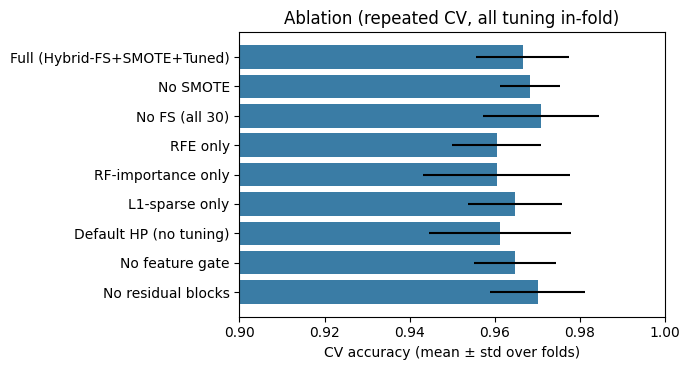

In [35]:
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.feature_selection import RFE

def fs_infold(Xs, ys, Xi_raw, yi_raw):
    """Feature selection using ONLY the fold's inner-train data. Xs/ys = SMOTE-balanced, Xi_raw/yi_raw = un-SMOTEd.
    Same recipe as the main pipeline: RFE ∪ RF ∪ bootstrap-stable Elastic-Net, with EN hyper-parameters tuned in-fold."""
    rfe_ = RFE(LogisticRegression(max_iter=5000), n_features_to_select=K_FS).fit(Xs, ys)
    s_rfe = list(np.where(rfe_.support_)[0])
    rf_ = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(Xs, ys)
    s_rf = list(np.argsort(-rf_.feature_importances_)[:K_FS])
    _, prm_en = tune_lr("enet", Xi_raw, yi_raw, Xs, ys, one_se=True, n_C=7)          # in-fold EN tuning
    freq_ = selection_frequency("enet", prm_en, Xi_raw, yi_raw, ABL_BOOT)             # in-fold bootstrap stability
    s_en = list(np.where(freq_ >= STAB_THR)[0])
    votes = Counter(s_rfe + s_rf + s_en)
    hyb = sorted(j for j, v in votes.items() if v >= 2)
    if len(hyb) < 8:
        hyb = sorted(sorted(votes, key=lambda j: -votes[j])[:10])
    return {"hybrid": hyb, "rfe": sorted(s_rfe), "rf": sorted(s_rf),
            "l1": sorted(s_en) if len(s_en) >= 3 else list(range(Xs.shape[1])), "all": list(range(Xs.shape[1]))}

def tune_hp_infold(cols, Xi_bal, yi_bal, Xv, yv, seed):
    """Optuna INSIDE the fold: train on the fold's inner-train, score on the fold's inner-validation."""
    def obj(trial):
        m_ = build_and_train(sample_hp(trial), Xi_bal[:, cols], yi_bal, Xv[:, cols], yv, seed=seed)
        return log_loss(yv, np.clip(predict_proba(m_, Xv[:, cols]), 1e-6, 1 - 1e-6), labels=[0, 1])
    st_ = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=seed))
    st_.optimize(obj, n_trials=ABL_TRIALS)
    return st_.best_params

FULL = "Full (Hybrid-FS+SMOTE+Tuned)"
variants = {   # name: (fs_key, use_smote, hp_mode, use_gate)
    FULL: ("hybrid", True, "tuned", True),
    "No SMOTE": ("hybrid", False, "tuned", True),
    "No FS (all 30)": ("all", True, "tuned", True),
    "RFE only": ("rfe", True, "tuned", True),
    "RF-importance only": ("rf", True, "tuned", True),
    "L1-sparse only": ("l1", True, "tuned", True),
    "Default HP (no tuning)": ("hybrid", True, "default", True),
    "No feature gate": ("hybrid", True, "tuned", False),
    "No residual blocks": ("hybrid", True, "noblock", True),
}

X_abl, y_abl = X.values.astype(float), y.copy()
abl_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=ABL_REPEATS, random_state=SEED)
results = {v: [] for v in variants}
n_hyb = []
t0 = time.time()
for fi, (tr, te) in enumerate(abl_cv.split(X_abl, y_abl)):
    sc = StandardScaler().fit(X_abl[tr])
    Xtr_f, Xte_f, ytr_f, yte_f = sc.transform(X_abl[tr]), sc.transform(X_abl[te]), y_abl[tr], y_abl[te]
    itr, iva = train_test_split(np.arange(len(tr)), test_size=0.2, stratify=ytr_f, random_state=SEED + fi)
    Xi_raw, yi_raw, Xv, yv = Xtr_f[itr], ytr_f[itr], Xtr_f[iva], ytr_f[iva]
    Xi_bal, yi_bal = SMOTE(random_state=SEED + fi).fit_resample(Xi_raw, yi_raw)
    fs = fs_infold(Xi_bal, yi_bal, Xi_raw, yi_raw); n_hyb.append(len(fs["hybrid"]))
    hp_fold = {k: tune_hp_infold(fs[k], Xi_bal, yi_bal, Xv, yv, SEED + fi) for k in ("hybrid", "all", "rfe", "rf", "l1")}   # in-fold HP
    for name, (fs_key, use_smote, hp_mode, use_gate) in variants.items():
        cols = fs[fs_key]
        hp = HP_DEFAULT if hp_mode == "default" else ({**hp_fold[fs_key], "n_blocks": 0} if hp_mode == "noblock" else hp_fold[fs_key])
        Xt, yt = (Xi_bal, yi_bal) if use_smote else (Xi_raw, yi_raw)
        m = build_and_train(hp, Xt[:, cols], yt, Xv[:, cols], yv, seed=SEED + fi, use_gate=use_gate)
        r = compute_metrics(yte_f, predict_proba(m, Xte_f[:, cols]), 0.5)
        results[name].append((r["accuracy"], r["f1"], r["auc"]))
    print(f"fold {fi+1}/{abl_cv.get_n_splits()} শেষ ({time.time()-t0:.0f}s)")

full_acc = np.array([r[0] for r in results[FULL]])
rows = []
for name, runs in results.items():
    a, f1s, aucs = (np.array([r[i] for r in runs]) for i in range(3))
    if name == FULL:
        p = np.nan
    else:
        try: p = stats.wilcoxon(a - full_acc).pvalue
        except ValueError: p = 1.0           # সব পার্থক্য শূন্য
    rows.append(dict(variant=name, accuracy=f"{a.mean():.4f} ± {a.std():.4f}", f1=f"{f1s.mean():.4f} ± {f1s.std():.4f}",
                     auc=f"{aucs.mean():.4f} ± {aucs.std():.4f}", delta_acc_vs_full=a.mean() - full_acc.mean(), wilcoxon_p_vs_full=p))
abl_df = pd.DataFrame(rows)
abl_df["p_holm"] = np.nan
mask = abl_df.wilcoxon_p_vs_full.notna()
pv_ = abl_df.loc[mask, "wilcoxon_p_vs_full"].values
order_ = np.argsort(pv_); adj = np.empty(len(pv_)); run_ = 0
for rank, i in enumerate(order_):
    run_ = max(run_, (len(pv_) - rank) * pv_[i]); adj[i] = min(1.0, run_)
abl_df.loc[mask, "p_holm"] = adj
print(f"Hybrid-FS (in-fold) গড় ফিচার সংখ্যা: {np.mean(n_hyb):.1f} / {X_abl.shape[1]}")
display(abl_df.round(4))
abl_df.round(4).to_csv(os.path.join(OUT_DIR, "ablation_cv.csv"), index=False)

nofs_acc = np.array([r[0] for r in results["No FS (all 30)"]])
FS_VERDICT = ("Hybrid-FS ≈ No-FS (ছোট পার্থক্য, dimensionality কমায়)" if abs(full_acc.mean() - nofs_acc.mean()) < 0.01
              else ("Hybrid-FS accuracy বাড়ায়" if full_acc.mean() > nofs_acc.mean() else "Hybrid-FS accuracy কমায় — FS-কে accuracy-booster বলা যাবে না"))
print("📌 FS verdict (ablation):", FS_VERDICT, f"| Full={full_acc.mean():.4f} vs No-FS={nofs_acc.mean():.4f}")

plt.figure(figsize=(7, 3.8))
names_ = list(results.keys())
means_ = [np.mean([r[0] for r in results[n]]) for n in names_]
stds_ = [np.std([r[0] for r in results[n]]) for n in names_]
plt.barh(names_[::-1], means_[::-1], xerr=stds_[::-1], color="#3A7CA5")
plt.xlim(0.90, 1.0); plt.xlabel("CV accuracy (mean ± std over folds)"); plt.title("Ablation (repeated CV, all tuning in-fold)")
plt.tight_layout(); savefig("13_ablation.png"); plt.show()

## 📐 ধাপ ২২: Nested Cross-Validation (সব মডেল) + Statistical Significance — v2
1. **Outer:** Repeated Stratified 5-fold × `CV_REPEATS` — **সব মডেলের জন্য একই fold**।
2. **Inner:** প্রতি outer-train-এর ভেতরে 3-fold CV দিয়ে tuning (LR: `C`, `l1_ratio`; RF: depth/leaf; SVM: `C`; Custom MLP: Optuna `NESTED_MLP_TRIALS` trial) — outer-test কখনো দেখা হয় না।
3. **Scaler, imputer, SMOTE প্রতি fold-এর ভেতরে**; সব ৩০ ফিচার।
4. **Friedman** → **Wilcoxon + Nadeau–Bengio corrected t** (Custom MLP বনাম প্রতিটি baseline) + **Holm**।
5. **v2:** **Non-inferiority test** (margin δ = `NI_MARGIN`): "Custom MLP সেরা baseline-এর চেয়ে ≥1 pp খারাপ নয়" — "better" প্রমাণ না হলেও এটাই সৎ দাবি।
6. **v2:** প্রতি outer fold-এর **out-of-fold probability** সংরক্ষণ → ধাপ ২৩-এর DCA/Calibration পুরো 569 নমুনায় (hold-out n=86 নয়)।
7. Threshold = 0.5।

In [36]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, cross_validate, train_test_split
from sklearn.metrics import make_scorer
from sklearn.svm import SVC
from scipy import stats
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

X_all = X.values.astype(float); y_all = y.copy()
outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=CV_REPEATS, random_state=SEED)
outer_splits = list(outer_cv.split(X_all, y_all))                     # SAME folds for every model
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
nested_scoring = {"acc": "accuracy", "f1": "f1", "auc": "roc_auc", "brier": "neg_brier_score",
                  "sens": "recall", "spec": make_scorer(recall_score, pos_label=0)}

def sk_pipe(clf):
    return ImbPipeline([("sc", StandardScaler()), ("imp", KNNImputer(n_neighbors=5)), ("smote", SMOTE(random_state=SEED)), ("clf", clf)])

def nested_estimator(kind):
    if kind in ("glm", "ridge", "lasso", "enet"):
        pipe = sk_pipe(make_lr(kind))
        grid = {} if kind == "glm" else {"clf__C": np.logspace(-2, 1 if kind == "enet" else 2, 7)}
        if kind == "enet": grid["clf__l1_ratio"] = [0.3, 0.6, 0.9]
    elif kind == "rf":
        pipe = sk_pipe(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1))
        grid = {"clf__max_depth": [None, 6], "clf__min_samples_leaf": [1, 3]}
    else:
        pipe = sk_pipe(SVC(probability=True, random_state=SEED))
        grid = {"clf__C": [0.5, 1, 2, 5]}
    return GridSearchCV(pipe, grid, cv=inner_cv, scoring="neg_log_loss", n_jobs=1) if grid else pipe

N_REP_ = max(1, len(outer_splits) // 5)
oof_prob = {}                                                         # v2: out-of-fold probability (repeat × sample)
def collect_oof(label, get_prob):
    arr = np.full((N_REP_, len(y_all)), np.nan)
    for fi, (tr, te) in enumerate(outer_splits):
        arr[fi // 5, te] = get_prob(fi, te)
    oof_prob[label] = arr

nested_res, nested_hp = {}, {}
for kind, label in [("glm", "GLM"), ("ridge", "Ridge"), ("lasso", "Lasso"), ("enet", "Elastic-Net"),
                    ("rf", "Random Forest"), ("svm", "SVM (RBF)")]:
    t0 = time.time()
    r = cross_validate(nested_estimator(kind), X_all, y_all, cv=outer_splits, scoring=nested_scoring,
                       n_jobs=-1, return_estimator=True)
    nested_res[label] = r
    ests_ = r["estimator"]
    collect_oof(label, lambda fi, te, ests_=ests_: ests_[fi].predict_proba(X_all[te])[:, 1])
    if kind != "glm":
        nested_hp[label] = [e.best_params_ for e in ests_]
    print(f"{label:14s} acc={r['test_acc'].mean():.4f}±{r['test_acc'].std():.4f} ({time.time()-t0:.0f}s)")

# ---------- Custom MLP: একই outer fold, inner split-এ Optuna ----------
mlp = {k: [] for k in ["acc", "f1", "auc", "brier", "sens", "spec"]}
mlp_hp, mlp_oof = [], {}
t0 = time.time()
for fold, (tr, te) in enumerate(outer_splits):
    sc = StandardScaler().fit(X_all[tr]); knn_f = KNNImputer(n_neighbors=5).fit(sc.transform(X_all[tr]))
    Xtr_f, Xte_f = knn_f.transform(sc.transform(X_all[tr])), knn_f.transform(sc.transform(X_all[te]))
    itr, iva = train_test_split(np.arange(len(tr)), test_size=0.2, stratify=y_all[tr], random_state=SEED + fold)
    Xi, yi = SMOTE(random_state=SEED + fold).fit_resample(Xtr_f[itr], y_all[tr][itr])
    Xv, yv = Xtr_f[iva], y_all[tr][iva]
    def obj(trial):
        m_ = build_and_train(sample_hp(trial), Xi, yi, Xv, yv, seed=SEED + fold)
        return log_loss(yv, np.clip(predict_proba(m_, Xv), 1e-6, 1 - 1e-6), labels=[0, 1])
    st = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED + fold))
    st.optimize(obj, n_trials=NESTED_MLP_TRIALS)
    m = build_and_train(st.best_params, Xi, yi, Xv, yv, seed=SEED + fold)
    p_te_ = predict_proba(m, Xte_f); mlp_oof[fold] = p_te_
    mt = compute_metrics(y_all[te], p_te_, 0.5)
    mlp["acc"].append(mt["accuracy"]); mlp["f1"].append(mt["f1"]); mlp["auc"].append(mt["auc"])
    mlp["brier"].append(-mt["brier"]); mlp["sens"].append(mt["sensitivity"]); mlp["spec"].append(mt["specificity"])
    mlp_hp.append(st.best_params)
    print(f"Custom MLP fold {fold+1}/{len(outer_splits)}: acc={mt['accuracy']:.4f} ({time.time()-t0:.0f}s)")
nested_res["Custom MLP"] = {f"test_{k}": np.array(v) for k, v in mlp.items()}
nested_hp["Custom MLP"] = mlp_hp
collect_oof("Custom MLP", lambda fi, te: mlp_oof[fi])

cv_res = nested_res                                                   # ধাপ ২২-এর test-গুলো এই fold-score ব্যবহার করে
cv_table = pd.DataFrame({n: dict(accuracy=f"{r['test_acc'].mean():.4f} ± {r['test_acc'].std():.4f}",
                                 f1=f"{r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f}",
                                 auc=f"{r['test_auc'].mean():.4f} ± {r['test_auc'].std():.4f}") for n, r in cv_res.items()}).T
print("\n📊 Nested CV ফলাফল (mean ± std over outer folds):"); display(cv_table)

GLM            acc=0.9590±0.0186 (1s)
Ridge          acc=0.9731±0.0118 (5s)
Lasso          acc=0.9672±0.0149 (5s)
Elastic-Net    acc=0.9707±0.0105 (270s)
Random Forest  acc=0.9602±0.0163 (98s)
SVM (RBF)      acc=0.9754±0.0117 (5s)
Custom MLP fold 1/15: acc=0.9825 (37s)
Custom MLP fold 2/15: acc=0.9649 (51s)
Custom MLP fold 3/15: acc=0.9561 (80s)
Custom MLP fold 4/15: acc=0.9649 (102s)
Custom MLP fold 5/15: acc=0.9912 (133s)
Custom MLP fold 6/15: acc=0.9912 (159s)
Custom MLP fold 7/15: acc=0.9737 (178s)
Custom MLP fold 8/15: acc=0.9649 (205s)
Custom MLP fold 9/15: acc=0.9737 (228s)
Custom MLP fold 10/15: acc=0.9558 (246s)
Custom MLP fold 11/15: acc=0.9649 (264s)
Custom MLP fold 12/15: acc=0.9912 (280s)
Custom MLP fold 13/15: acc=0.9825 (327s)
Custom MLP fold 14/15: acc=0.9825 (343s)
Custom MLP fold 15/15: acc=0.9646 (360s)

📊 Nested CV ফলাফল (mean ± std over outer folds):


,accuracy,f1,auc
GLM,0.9590 ± 0.0186,0.9451 ± 0.0250,0.9842 ± 0.0127
Ridge,0.9731 ± 0.0118,0.9636 ± 0.0162,0.9943 ± 0.0051
Lasso,0.9672 ± 0.0149,0.9553 ± 0.0209,0.9945 ± 0.0042
Elastic-Net,0.9707 ± 0.0105,0.9602 ± 0.0147,0.9940 ± 0.0056
Random Forest,0.9602 ± 0.0163,0.9467 ± 0.0216,0.9921 ± 0.0055
SVM (RBF),0.9754 ± 0.0117,0.9669 ± 0.0158,0.9958 ± 0.0043
Custom MLP,0.9736 ± 0.0120,0.9640 ± 0.0167,0.9931 ± 0.0074


In [37]:
acc_cv = {n: r["test_acc"] for n, r in cv_res.items()}               # fold-অনুযায়ী accuracy
fr = stats.friedmanchisquare(*acc_cv.values())                       # Friedman test
print(f"Friedman χ² = {fr.statistic:.3f}, p = {fr.pvalue:.4f}  →", "মডেলগুলোর মধ্যে উল্লেখযোগ্য পার্থক্য আছে" if fr.pvalue < 0.05 else "উল্লেখযোগ্য পার্থক্য প্রমাণিত নয়")

def holm(pvals):                                                     # Holm-Bonferroni correction
    p = np.asarray(pvals); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

k = len(acc_cv["Custom MLP"]); ratio = 1 / 4                         # 5-fold-এ n_test/n_train = 1/4
rows = []
for other in [n for n in acc_cv if n != "Custom MLP"]:
    d = acc_cv["Custom MLP"] - acc_cv[other]                         # জোড়া-পার্থক্য
    try: pw = stats.wilcoxon(d).pvalue                               # Wilcoxon
    except ValueError: pw = 1.0                                      # সব পার্থক্য শূন্য হলে
    var = d.var(ddof=1)
    se_nb = np.sqrt((1 / k + ratio) * var)                           # Nadeau–Bengio corrected SE
    t = d.mean() / se_nb if var > 0 else 0.0
    pt = 2 * (1 - stats.t.cdf(abs(t), df=k - 1))
    lo90 = d.mean() - stats.t.ppf(0.95, k - 1) * se_nb               # 90% two-sided = TOST α=0.05
    rows.append(dict(comparison=f"Custom MLP vs {other}", mean_diff_acc=d.mean(), wilcoxon_p=pw, corrected_t_p=pt,
                     NB_90CI_lower=lo90, noninferior=bool(lo90 > -NI_MARGIN)))
sig = pd.DataFrame(rows)
sig["wilcoxon_p_holm"] = holm(sig.wilcoxon_p); sig["corrected_t_p_holm"] = holm(sig.corrected_t_p)
sig["significant(α=0.05)"] = (sig.corrected_t_p_holm < 0.05)
print("\n📊 Pairwise tests (nested-CV fold accuracy; Custom MLP বনাম বাকিরা):"); display(sig.round(4))

# ---- automatic, honest claim ----
base_means = {n: v.mean() for n, v in acc_cv.items() if n != "Custom MLP" and n != "GLM"}   # GLM = weak reference, বাদ
best_base = max(base_means, key=base_means.get)
row_b = sig[sig.comparison == f"Custom MLP vs {best_base}"].iloc[0]
mlp_m = acc_cv["Custom MLP"].mean()
if row_b["significant(α=0.05)"] and row_b.mean_diff_acc > 0:
    CLAIM = f"Custom MLP significantly outperforms the strongest baseline ({best_base}) after Holm correction."
elif row_b["noninferior"]:
    CLAIM = (f"Custom MLP is NON-INFERIOR (margin {NI_MARGIN*100:.0f} pp) to the strongest baseline ({best_base}): "
             f"Δacc={row_b.mean_diff_acc*100:+.2f} pp, but superiority is NOT demonstrated (Holm-adjusted p={row_b.corrected_t_p_holm:.3f}).")
elif row_b["corrected_t_p_holm"] >= 0.05:
    CLAIM = (f"No statistically significant difference between Custom MLP and the strongest baseline ({best_base}) after Holm correction "
             f"(Δacc={row_b.mean_diff_acc*100:+.2f} pp, Holm p={row_b.corrected_t_p_holm:.2f}); the models are comparable, but formal equivalence/non-inferiority "
             f"within {NI_MARGIN*100:.0f} pp is not established with this sample size.")
else:
    CLAIM = f"Custom MLP is significantly WORSE than {best_base} (Δacc={row_b.mean_diff_acc*100:+.2f} pp, Holm p={row_b.corrected_t_p_holm:.3f})."
print("\n📌 Allowed claim:", CLAIM)

Friedman χ² = 18.611, p = 0.0049  → মডেলগুলোর মধ্যে উল্লেখযোগ্য পার্থক্য আছে

📊 Pairwise tests (nested-CV fold accuracy; Custom MLP বনাম বাকিরা):


,comparison,mean_diff_acc,wilcoxon_p,corrected_t_p,NB_90CI_lower,noninferior,wilcoxon_p_holm,corrected_t_p_holm,significant(α=0.05)
0,Custom MLP vs GLM,0.0146,0.0130,0.2499,-0.0068,True,0.0648,1.0000,False
1,Custom MLP vs Ridge,0.0006,1.0000,0.9435,-0.0136,False,1.0000,1.0000,False
2,Custom MLP vs Lasso,0.0064,0.1092,0.3805,-0.0061,True,0.4367,1.0000,False
3,Custom MLP vs Elastic-Net,0.0029,0.2374,0.6044,-0.0068,True,0.7123,1.0000,False
4,Custom MLP vs Random Forest,0.0135,0.0033,0.0462,0.0026,True,0.0198,0.2769,False
5,Custom MLP vs SVM (RBF),-0.0018,0.5128,0.8061,-0.0141,False,1.0000,1.0000,False



📌 Allowed claim: No statistically significant difference between Custom MLP and the strongest baseline (SVM (RBF)) after Holm correction (Δacc=-0.18 pp, Holm p=1.00); the models are comparable, but formal equivalence/non-inferiority within 1 pp is not established with this sample size.


In [38]:
# ---------- McNemar (hold-out test set) ----------
ref = "Custom MLP (tuned)"
preds = {n: (test_probs[n] >= youden_threshold(y_va, val_probs[n])).astype(int) for n in test_probs}   # প্রতি মডেলের class
rows = []
for n in preds:
    if n == ref: continue
    c_ok, o_ok = preds[ref] == y_te, preds[n] == y_te
    b, c = int((c_ok & ~o_ok).sum()), int((~c_ok & o_ok).sum())      # discordant জোড়া
    p = stats.binomtest(min(b, c), b + c, 0.5).pvalue if (b + c) > 0 else 1.0   # exact McNemar
    rows.append(dict(vs=n, custom_right_other_wrong=b, custom_wrong_other_right=c, mcnemar_p=p))
mc_df = pd.DataFrame(rows); mc_df["p_holm"] = holm(mc_df.mcnemar_p)
print("📊 McNemar test (Custom MLP tuned বনাম অন্য):"); display(mc_df.round(4))

# ---------- Hold-out accuracy: exact (Clopper–Pearson) 95% CI ----------
# (bootstrap CI 0 ভুলে [1,1] হয়ে যায় — মিথ্যা নিশ্চয়তা; exact CI ছোট n-এ ঠিক)
for nm, thr_ in [("Youden thr", thr_final), ("thr 0.5", 0.5)]:
    k_ = int((((pt_c >= thr_).astype(int)) == y_te).sum())
    ci_ = stats.binomtest(k_, len(y_te)).proportion_ci(method="exact")
    print(f"🎯 Hold-out accuracy ({nm}) = {k_}/{len(y_te)} = {k_/len(y_te):.4f} | exact 95% CI [{ci_.low:.4f}, {ci_.high:.4f}]")


📊 McNemar test (Custom MLP tuned বনাম অন্য):


,vs,custom_right_other_wrong,custom_wrong_other_right,mcnemar_p,p_holm
0,GLM,1,1,1.0,1.0
1,Ridge,1,0,1.0,1.0
2,Lasso,1,0,1.0,1.0
3,Elastic-Net,1,0,1.0,1.0
4,Random Forest,1,1,1.0,1.0
5,SVM (RBF),0,0,1.0,1.0
6,Custom MLP (default HP),0,0,1.0,1.0


🎯 Hold-out accuracy (Youden thr) = 85/86 = 0.9884 | exact 95% CI [0.9369, 0.9997]
🎯 Hold-out accuracy (thr 0.5) = 85/86 = 0.9884 | exact 95% CI [0.9369, 0.9997]


## 📋 ধাপ ২২ক: Nested CV সারণি (Nadeau–Bengio corrected 95% CI)
Fold গুলো overlap করে বলে সাধারণ CI খুব ছোট আসে; তাই Nadeau–Bengio সংশোধিত CI। **এটিই paper-এর মূল ফলাফল-সারণি।**

📊 Nested CV — সব মডেল (outer 5-fold × 3 repeat, একই fold, thr 0.5) — mean [Nadeau–Bengio 95% CI]:


,model,accuracy,sensitivity,specificity,f1,auc,brier
0,GLM,"0.959 [0.936, 0.982]","0.948 [0.905, 0.991]","0.965 [0.941, 0.990]","0.945 [0.914, 0.976]","0.984 [0.968, 1.000]","0.040 [0.017, 0.063]"
1,Ridge,"0.973 [0.958, 0.988]","0.959 [0.922, 0.996]","0.981 [0.961, 1.000]","0.964 [0.943, 0.984]","0.994 [0.988, 1.000]","0.022 [0.013, 0.031]"
2,Lasso,"0.967 [0.949, 0.986]","0.945 [0.903, 0.987]","0.980 [0.965, 0.996]","0.955 [0.929, 0.981]","0.995 [0.989, 1.000]","0.024 [0.016, 0.032]"
3,Elastic-Net,"0.971 [0.958, 0.984]","0.951 [0.912, 0.991]","0.982 [0.963, 1.000]","0.960 [0.942, 0.979]","0.994 [0.987, 1.000]","0.023 [0.015, 0.032]"
4,Random Forest,"0.960 [0.940, 0.981]","0.951 [0.913, 0.989]","0.965 [0.940, 0.991]","0.947 [0.920, 0.974]","0.992 [0.985, 0.999]","0.032 [0.023, 0.041]"
5,SVM (RBF),"0.975 [0.961, 0.990]","0.965 [0.932, 0.999]","0.981 [0.965, 0.998]","0.967 [0.947, 0.987]","0.996 [0.990, 1.000]","0.020 [0.012, 0.029]"
6,Custom MLP,"0.974 [0.959, 0.989]","0.954 [0.914, 0.995]","0.985 [0.968, 1.000]","0.964 [0.943, 0.985]","0.993 [0.984, 1.000]","0.023 [0.011, 0.034]"


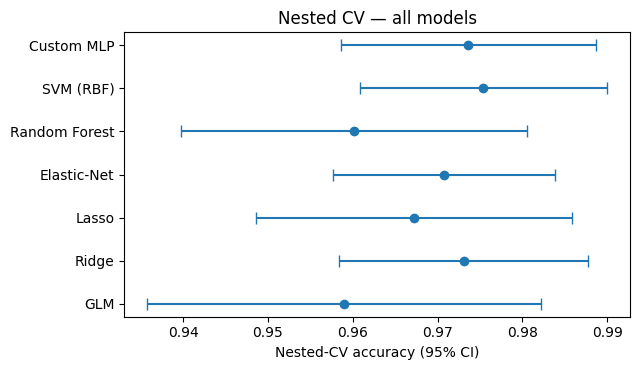

In [39]:
def nb_ci(v, test_train_ratio=1 / 4):                                      # 5-fold ⇒ n_test/n_train = 1/4
    v = np.asarray(v, dtype=float); k = len(v); var = v.var(ddof=1)
    half = stats.t.ppf(0.975, k - 1) * np.sqrt((1 / k + test_train_ratio) * var)
    return max(0.0, v.mean() - half), min(1.0, v.mean() + half)

def summarize_nested(res_dict):
    rows = []
    for n, r in res_dict.items():
        row = {"model": n}
        for key, nm in [("acc", "accuracy"), ("sens", "sensitivity"), ("spec", "specificity"), ("f1", "f1"), ("auc", "auc")]:
            v = np.asarray(r[f"test_{key}"]); lo, hi = nb_ci(v); row[nm] = f"{v.mean():.3f} [{lo:.3f}, {hi:.3f}]"
        b = -np.asarray(r["test_brier"]); lo, hi = nb_ci(b); row["brier"] = f"{b.mean():.3f} [{lo:.3f}, {hi:.3f}]"
        rows.append(row)
    return pd.DataFrame(rows)

nested_all = summarize_nested(nested_res)
print(f"📊 Nested CV — সব মডেল (outer 5-fold × {CV_REPEATS} repeat, একই fold, thr 0.5) — mean [Nadeau–Bengio 95% CI]:")
display(nested_all)
nested_all.to_csv(os.path.join(OUT_DIR, "nested_cv_all_models.csv"), index=False)

plt.figure(figsize=(6.5, 3.8))
names = list(nested_res)
means = [np.mean(nested_res[n]["test_acc"]) for n in names]
cis = [nb_ci(nested_res[n]["test_acc"]) for n in names]
plt.errorbar(means, range(len(names)), xerr=[[m - c[0] for m, c in zip(means, cis)], [c[1] - m for m, c in zip(means, cis)]], fmt="o", capsize=4)
plt.yticks(range(len(names)), names); plt.xlabel("Nested-CV accuracy (95% CI)"); plt.title("Nested CV — all models")
plt.tight_layout(); savefig("19_nested_cv_all.png"); plt.show()

In [40]:
# ---------- outer fold-গুলোতে বাছাই হওয়া hyperparameter কতটা স্থিতিশীল ----------
for n, plist in nested_hp.items():
    if n == "Custom MLP":
        print("Custom MLP — প্রতি outer fold-এ বাছাই হওয়া HP:"); display(pd.DataFrame(plist).round(5))
    else:
        print(f"{n}: →", pd.DataFrame(plist).apply(lambda s: s.value_counts().to_dict()).to_dict())

Ridge: → {'clf__C': {1.0: 13, 0.21544346900318834: 1, 4.6415888336127775: 1}}
Lasso: → {'clf__C': {1.0: 15}}
Elastic-Net: → {'clf__C': {1.0: 11, 3.1622776601683795: 3, 0.31622776601683794: 1}, 'clf__l1_ratio': {0.3: 11, 0.6: 2, 0.9: 2}}
Random Forest: → {'clf__max_depth': {6.0: 5}, 'clf__min_samples_leaf': {1: 13, 3: 2}}
SVM (RBF): → {'clf__C': {2: 8, 1: 6, 5: 1}}
Custom MLP — প্রতি outer fold-এ বাছাই হওয়া HP:


,hidden,n_blocks,dropout,lr,wd,bs
0,128,1,0.30569,0.00153,0.00000,16
1,64,2,0.49743,0.00296,0.00006,64
2,32,1,0.29745,0.00541,0.00000,64
3,32,2,0.20078,0.00017,0.00081,32
4,128,1,0.14163,0.00402,0.00004,16
5,32,3,0.41984,0.00195,0.00005,16
6,32,3,0.22979,0.00536,0.00006,16
7,64,3,0.15483,0.00720,0.00031,16
8,16,3,0.25508,0.00039,0.00029,64
9,32,2,0.16577,0.00025,0.00001,16


## 🩺 ধাপ ২৩: Risk Scoring ও Doctor Assignment
**Risk Score (০–১০০)** = calibrated malignancy probability × 100

| Band | নিয়ম | বিশেষজ্ঞ | অগ্রাধিকার |
|---|---|---|---|
| Low | score < 30 | Breast Clinic Physician | Routine follow-up |
| Medium | 30 ≤ score < 70 | Radiologist | ১ সপ্তাহের মধ্যে |
| High | score ≥ 70 | Oncologist | জরুরি (২৪–৪৮ ঘণ্টা) |
| Needs Review | অনিশ্চিত (MC-Dropout / বলয়) | Senior Oncologist | Second opinion |

Doctor assignment: ওই specialty-র মধ্যে **সবচেয়ে কম workload-ratio** যে ডাক্তারের, তাকে দেওয়া হয় (load balancing)।
> ⚠️ নিচের ডাক্তারের তালিকা **ডামি** — নিজের হাসপাতালের তালিকা দিয়ে বদলান।

In [41]:
SPECIALTY = {"Low": "Breast Clinic Physician", "Medium": "Radiologist", "High": "Oncologist", "Needs Review": "Senior Oncologist"}
PRIORITY = {"Low": "Routine follow-up", "Medium": "Within 1 week", "High": "Urgent (24-48h)", "Needs Review": "Second opinion (priority)"}

def risk_band(score, review, low=30, high=70):                       # ঝুঁকির স্তর নির্ধারণ
    if review: return "Needs Review"
    if score < low: return "Low"
    if score < high: return "Medium"
    return "High"

def assign_doctor(doctors, band):                                    # load-balanced ডাক্তার নির্ধারণ
    pool = doctors[doctors.specialty == SPECIALTY[band]].copy()      # ওই specialty-র ডাক্তার
    pool["ratio"] = pool.current_load / pool.capacity                # workload অনুপাত
    pick = pool.sort_values(["ratio", "doctor_id"]).iloc[0]          # সবচেয়ে কম ব্যস্ত

    # সঠিক Load Update এবং Overload Check
    new_load = pick.current_load + 1
    doctors.loc[pick.name, "current_load"] = new_load                # আসল ডাটাফ্রেমে লোড আপডেট

    return dict(
        doctor_id=pick.doctor_id,
        doctor=pick["name"],
        specialty=pick.specialty,
        priority=PRIORITY[band],
        overloaded=bool(new_load > pick.capacity)                    # সঠিকভাবে overload যাচাই
    )

doctors_df = pd.DataFrame([                                          # ডামি ডাক্তার তালিকা
    ("D01", "Dr. A (Clinic)", "Breast Clinic Physician", 0, 25), ("D02", "Dr. B (Clinic)", "Breast Clinic Physician", 0, 25),
    ("D03", "Dr. C (Radiology)", "Radiologist", 0, 15), ("D04", "Dr. D (Radiology)", "Radiologist", 0, 15),
    ("D05", "Dr. E (Oncology)", "Oncologist", 0, 10), ("D06", "Dr. F (Oncology)", "Oncologist", 0, 10),
    ("D07", "Dr. G (Senior Onc.)", "Senior Oncologist", 0, 8), ("D08", "Dr. H (Senior Onc.)", "Senior Oncologist", 0, 8)],
    columns=["doctor_id", "name", "specialty", "current_load", "capacity"])

risk_score = 100 * final_prob_te                                            # ০–১০০ ঝুঁকি স্কোর
bands = [risk_band(s, r) for s, r in zip(risk_score, flag)]          # প্রতি রোগীর band
assign_log, doc_sim = [], doctors_df.copy()
for i, b in enumerate(bands):
    assign_log.append(dict(patient=i, true_label=["Benign", "Malignant"][y_te[i]], risk_score=round(risk_score[i], 1), band=b, **assign_doctor(doc_sim, b)))
assign_df = pd.DataFrame(assign_log)
print("📋 প্রথম ১০ রোগীর Risk Score ও Doctor Assignment:"); display(assign_df.head(10))

band_tab = assign_df.groupby("band").agg(n=("patient", "count"), malignant_rate=("true_label", lambda s: (s == "Malignant").mean())).round(3)
print("\n📊 Band-ভিত্তিক বাস্তব malignant হার (scoring-এর কার্যকারিতা যাচাই):"); display(band_tab)
print("\n👩‍⚕️ ডাক্তারদের workload:"); display(doc_sim)
print("\nBand সংখ্যা:", assign_df.band.value_counts().to_dict(), "| (MLP-র probability চরম মানে থাকে — Medium band প্রায় খালি থাকতে পারে)")


📋 প্রথম ১০ রোগীর Risk Score ও Doctor Assignment:


,patient,true_label,risk_score,band,doctor_id,doctor,specialty,priority,overloaded
0,0,Malignant,98.6,High,D05,Dr. E (Oncology),Oncologist,Urgent (24-48h),False
1,1,Benign,2.3,Low,D01,Dr. A (Clinic),Breast Clinic Physician,Routine follow-up,False
2,2,Benign,1.8,Low,D02,Dr. B (Clinic),Breast Clinic Physician,Routine follow-up,False
3,3,Benign,3.1,Low,D01,Dr. A (Clinic),Breast Clinic Physician,Routine follow-up,False
4,4,Benign,4.3,Low,D02,Dr. B (Clinic),Breast Clinic Physician,Routine follow-up,False
5,5,Malignant,99.2,High,D06,Dr. F (Oncology),Oncologist,Urgent (24-48h),False
6,6,Benign,4.2,Low,D01,Dr. A (Clinic),Breast Clinic Physician,Routine follow-up,False
7,7,Malignant,99.6,High,D05,Dr. E (Oncology),Oncologist,Urgent (24-48h),False
8,8,Benign,1.8,Low,D02,Dr. B (Clinic),Breast Clinic Physician,Routine follow-up,False
9,9,Benign,2.9,Low,D01,Dr. A (Clinic),Breast Clinic Physician,Routine follow-up,False



📊 Band-ভিত্তিক বাস্তব malignant হার (scoring-এর কার্যকারিতা যাচাই):


,n,malignant_rate
band,,
High,30,1.000
Low,47,0.000
Needs Review,9,0.222



👩‍⚕️ ডাক্তারদের workload:


,doctor_id,name,specialty,current_load,capacity
0,D01,Dr. A (Clinic),Breast Clinic Physician,24,25
1,D02,Dr. B (Clinic),Breast Clinic Physician,23,25
2,D03,Dr. C (Radiology),Radiologist,0,15
3,D04,Dr. D (Radiology),Radiologist,0,15
4,D05,Dr. E (Oncology),Oncologist,15,10
5,D06,Dr. F (Oncology),Oncologist,15,10
6,D07,Dr. G (Senior Onc.),Senior Oncologist,5,8
7,D08,Dr. H (Senior Onc.),Senior Oncologist,4,8



Band সংখ্যা: {'Low': 47, 'High': 30, 'Needs Review': 9} | (MLP-র probability চরম মানে থাকে — Medium band প্রায় খালি থাকতে পারে)


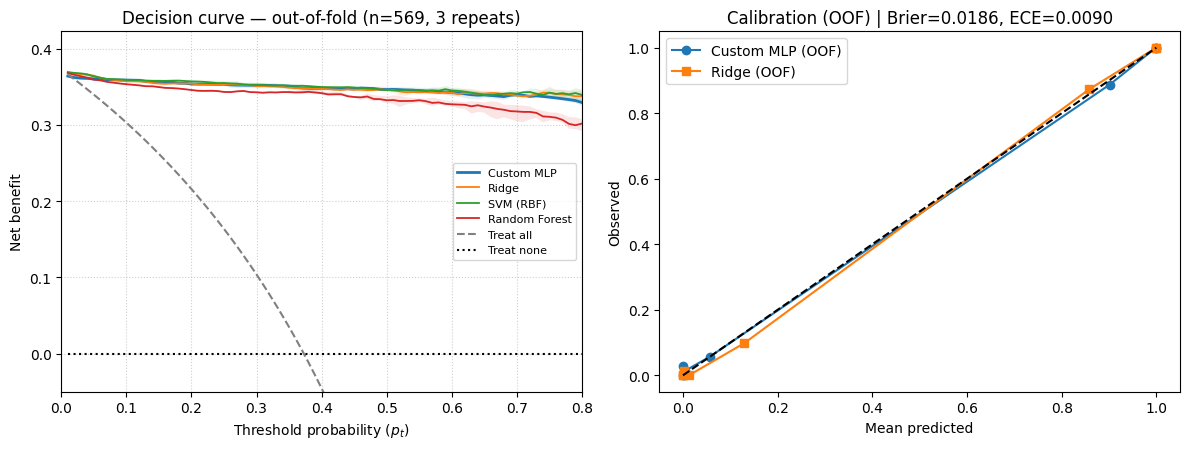

Out-of-fold (repeat-averaged) discrimination & calibration:


,model,auc,brier,ece
0,GLM,0.9827,0.0298,0.0220
1,Ridge,0.9939,0.0210,0.0048
2,Lasso,0.9944,0.0229,0.0065
3,Elastic-Net,0.9926,0.0222,0.0045
4,Random Forest,0.9915,0.0313,0.0294
5,SVM (RBF),0.9950,0.0197,0.0049
6,Custom MLP,0.9884,0.0186,0.0090


In [42]:
# ==========================================
# 📈 Decision Curve Analysis + Calibration — OUT-OF-FOLD (nested CV, n = 569)
# v2: hold-out n=86 থেকে নয়; প্রতিটি নমুনার prediction এমন মডেল থেকে যে মডেল ওই নমুনা দেখেনি।
# ==========================================
def decision_curve_analysis(y_true, y_prob, thresholds):
    y_true = np.asarray(y_true); n = len(y_true); out = []
    for pt_ in thresholds:
        y_pred = (y_prob >= pt_).astype(int)
        tp = np.sum((y_pred == 1) & (y_true == 1)); fp = np.sum((y_pred == 1) & (y_true == 0))
        out.append(tp / n - fp / n * (pt_ / (1 - pt_)))             # Net Benefit
    return np.array(out)

pt_range = np.linspace(0.01, 0.80, 80)
show = [m for m in ["Custom MLP", "Ridge", "SVM (RBF)", "Random Forest"] if m in oof_prob]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for m in show:
    nb_rep = np.array([decision_curve_analysis(y_all, oof_prob[m][r], pt_range) for r in range(oof_prob[m].shape[0])])
    ax[0].plot(pt_range, nb_rep.mean(0), lw=2 if m == "Custom MLP" else 1.3, label=m)
    if nb_rep.shape[0] > 1: ax[0].fill_between(pt_range, nb_rep.min(0), nb_rep.max(0), alpha=0.12)
prev = np.mean(y_all)
ax[0].plot(pt_range, prev - (1 - prev) * (pt_range / (1 - pt_range)), "--", color="gray", label="Treat all")
ax[0].plot(pt_range, np.zeros_like(pt_range), ":", color="black", label="Treat none")
ax[0].set_xlim(0, 0.8); ax[0].set_ylim(-0.05, prev + 0.05)
ax[0].set_xlabel("Threshold probability ($p_t$)"); ax[0].set_ylabel("Net benefit"); ax[0].legend(fontsize=8)
ax[0].set_title(f"Decision curve — out-of-fold (n={len(y_all)}, {oof_prob['Custom MLP'].shape[0]} repeats)"); ax[0].grid(True, ls=":", alpha=0.6)

p_mlp = np.nanmean(oof_prob["Custom MLP"], axis=0)
from sklearn.calibration import calibration_curve
fp_, mp_ = calibration_curve(y_all, p_mlp, n_bins=8, strategy="quantile")
ax[1].plot(mp_, fp_, "o-", label="Custom MLP (OOF)")
if "Ridge" in oof_prob:
    fr_, mr_ = calibration_curve(y_all, np.nanmean(oof_prob["Ridge"], axis=0), n_bins=8, strategy="quantile"); ax[1].plot(mr_, fr_, "s-", label="Ridge (OOF)")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].legend(); ax[1].set_xlabel("Mean predicted"); ax[1].set_ylabel("Observed")
ax[1].set_title(f"Calibration (OOF) | Brier={brier_score_loss(y_all, p_mlp):.4f}, ECE={ece_score(y_all, p_mlp):.4f}")
plt.tight_layout(); savefig("24_decision_curve_analysis.png"); plt.show()

oof_rows = []
for m in oof_prob:
    p_ = np.nanmean(oof_prob[m], axis=0)
    oof_rows.append(dict(model=m, auc=roc_auc_score(y_all, p_), brier=brier_score_loss(y_all, p_), ece=ece_score(y_all, p_)))
oof_summary = pd.DataFrame(oof_rows).round(4)
print("Out-of-fold (repeat-averaged) discrimination & calibration:"); display(oof_summary)

## 🚀 ধাপ ২৪: Deployment — Streamlit App (v3 · professional UI)
নিচের cell-গুলো `deploy_app/` ফোল্ডার বানায়:
- `model.pt`, `config.json` (ফিচার, scaler, threshold, τ, calibration a/b, counterfactual group/bounds, model card), `doctors.csv`
- `model_def.py` (মডেল + inference ফাংশন)
- `report_utils.py` (validation, Rx draft, PDF report, SQLite archive)
- `.streamlit/config.toml` (light theme) ও `app.py`

**App layout (স্কেচ অনুযায়ী):**

| বাম দিক | ডান দিক |
|---|---|
| **Patient information:** Patient name · NID number · Passport number · Age · Country code + Mobile · Doctor name | **Suggestion Prescription** — Download (PDF / Rx / JSON) · Add to archive |
| **FNA measurements:** Benign / Malignant / Mean বাটন + সব ফিচার এডিট | AI risk summary → **Rx** (editable draft) → **Suggestion report** |
| **Analyse patient** বাটন | নিচে ছোট বক্স: *This is AI … not for clinical use* |

আলাদা **Archive** ট্যাবে সংরক্ষিত রেকর্ড (search, CSV export, delete)।

> ⚠️ **Rx = draft care-pathway** (imaging/biopsy/referral ধাপ)। অ্যাপ কোনো **ওষুধ prescribe করে না**। Archive-এ NID/Passport/Phone **masked** আকারে সংরক্ষিত হয় (+ salted hash)। Demo-তে আসল রোগীর তথ্য দেবেন না।


In [43]:
os.makedirs(DEPLOY_DIR, exist_ok=True)                               # deploy ফোল্ডার তৈরি (পরের %%writefile-এর আগে দরকার)
print("ফোল্ডার প্রস্তুত:", DEPLOY_DIR)

ফোল্ডার প্রস্তুত: deploy_app


In [44]:
%%writefile deploy_app/model_def.py
# ==== model_def.py — notebook-এর মডেল ও inference ফাংশনের কপি (app এটি import করে) ====
import numpy as np, pandas as pd                                     # সংখ্যা ও ডেটাফ্রেম
import torch, torch.nn as nn, torch.nn.functional as F               # PyTorch

SPECIALTY = {"Low": "Breast Clinic Physician", "Medium": "Radiologist", "High": "Oncologist", "Needs Review": "Senior Oncologist"}
PRIORITY = {"Low": "Routine follow-up", "Medium": "Within 1 week", "High": "Urgent (24-48h)", "Needs Review": "Second opinion (priority)"}

class ResBlock(nn.Module):                                           # Residual ব্লক
    def __init__(self, dim, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(dim, dim))
    def forward(self, x):
        return x + self.net(x)

class CustomNet(nn.Module):                                          # Custom মডেল (Gate + Residual MLP)
    def __init__(self, in_dim, hidden=64, n_blocks=2, dropout=0.3, use_gate=True):
        super().__init__()
        self.use_gate = use_gate
        self.gate = nn.Parameter(torch.zeros(in_dim))
        self.inp = nn.Sequential(nn.Linear(in_dim, hidden), nn.GELU(), nn.Dropout(dropout))
        self.blocks = nn.Sequential(*[ResBlock(hidden, dropout) for _ in range(n_blocks)])
        self.out = nn.Linear(hidden, 1)
    def forward(self, x):
        if self.use_gate:
            x = x * (2 * torch.sigmoid(self.gate))
        return self.out(self.blocks(self.inp(x))).squeeze(-1)

def load_model(path):                                                # সেভ করা মডেল লোড
    ckpt = torch.load(path, map_location="cpu")                      # checkpoint
    m = CustomNet(**ckpt["config"]); m.load_state_dict(ckpt["state_dict"]); m.eval()
    return m

def mc_dropout_probs(model, X, T=50):                                # MC-Dropout: T বার stochastic predict
    model.train()                                                    # dropout চালু
    with torch.no_grad():
        xt = torch.tensor(np.asarray(X), dtype=torch.float32)
        probs = torch.stack([torch.sigmoid(model(xt)) for _ in range(T)]).numpy()
    model.eval()
    return probs                                                     # আকার (T, N)

def grad_x_input(model, x_std):                                      # Gradient × Input (লোকাল ব্যাখ্যা)
    model.eval()
    x = torch.tensor(np.asarray(x_std), dtype=torch.float32).reshape(1, -1).requires_grad_(True)
    model(x).sum().backward()
    return (x.grad * x).detach().numpy().ravel()

def platt_scale(p, a, b):                                            # σ(a·logit(p)+b); raw: a=1,b=0; temperature: a=1/T,b=0
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return 1 / (1 + np.exp(-(a * np.log(p / (1 - p)) + b)))

def generate_counterfactual(model, x_std, target, M, lo, hi, lambda_l1=0.10, steps=500, lr=0.05, margin=0.05):
    # M: (G × F) group→feature matrix (correlated features move together); lo/hi: training-range bounds (standardized)
    model.eval()
    x0 = torch.tensor(np.asarray(x_std), dtype=torch.float32).reshape(1, -1)
    Mt = torch.tensor(np.asarray(M), dtype=torch.float32)
    lot, hit = torch.tensor(np.asarray(lo), dtype=torch.float32), torch.tensor(np.asarray(hi), dtype=torch.float32)
    g = torch.zeros(1, Mt.shape[0], requires_grad=True)
    opt = torch.optim.Adam([g], lr=lr)
    tgt = torch.tensor([float(target)])
    def make(gv):
        return torch.minimum(torch.maximum(x0 + gv @ Mt, lot), hit)
    def ok(gv):
        with torch.no_grad():
            p = torch.sigmoid(model(make(gv))).item()
        return (p >= 0.5 + margin) if target == 1 else (p <= 0.5 - margin)
    found = False
    for _ in range(steps):
        opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(model(make(g)), tgt) + lambda_l1 * g.abs().sum()
        loss.backward(); opt.step()
        if ok(g.detach()):
            found = True; break
    gd = g.detach().clone()
    if not found:
        return (make(gd) - x0).detach().squeeze(0).numpy(), False
    for j in torch.argsort(gd.abs().squeeze(0)):
        t = gd.clone(); t[0, j] = 0.0
        if ok(t): gd = t
    return (make(gd) - x0).detach().squeeze(0).numpy(), True

def risk_band(score, review, low=30, high=70):                       # ঝুঁকির স্তর
    if review: return "Needs Review"
    if score < low: return "Low"
    if score < high: return "Medium"
    return "High"

def assign_doctor(doctors, band):                                    # load-balanced ডাক্তার নির্ধারণ
    pool = doctors[doctors.specialty == SPECIALTY[band]].copy()
    pool["ratio"] = pool.current_load / pool.capacity
    pick = pool.sort_values(["ratio", "doctor_id"]).iloc[0]
    doctors.loc[pick.name, "current_load"] += 1
    return dict(doctor_id=pick.doctor_id, doctor=pick["name"], specialty=pick.specialty,
                priority=PRIORITY[band], overloaded=bool(pick.current_load + 1 > pick.capacity))

Writing deploy_app/model_def.py


In [45]:
# ---------- মডেল, config, doctors সেভ ----------
torch.save({"state_dict": final_model.state_dict(),
            "config": dict(in_dim=len(sel_hybrid), hidden=HP_BEST["hidden"], n_blocks=HP_BEST["n_blocks"], dropout=HP_BEST["dropout"], use_gate=True)},
           os.path.join(DEPLOY_DIR, "model.pt"))                     # মডেল weight
raw_sel = X_train_raw[sel_hybrid]                                    # মূল এককের train ফিচার
_acc = nested_res["Custom MLP"]["test_acc"]; _auc = nested_res["Custom MLP"]["test_auc"]
_lo, _hi = nb_ci(_acc)
model_card = dict(
    dataset="Wisconsin Diagnostic Breast Cancer (FNA-image-derived numeric features), n=%d" % len(y_all),
    task="Benign vs malignant, tabular model (not an image model)",
    nested_cv_accuracy=round(float(_acc.mean()), 4), nested_cv_accuracy_ci=[round(float(_lo), 4), round(float(_hi), 4)],
    nested_cv_auc=round(float(_auc.mean()), 4), cv_folds=int(len(_acc)),
    allowed_claim=CLAIM, calibration=CALIB, n_features=len(sel_hybrid))
cfg = dict(features=sel_hybrid, mean=mu_sel.tolist(), scale=sd_sel.tolist(),
           raw_min=raw_sel.min().tolist(), raw_max=raw_sel.max().tolist(), raw_mean=raw_sel.mean().tolist(),
           thr=float(thr_mc), tau=tau, review_band=list(REVIEW_BAND), platt_a=float(platt_a_use), platt_b=float(platt_b_use), mc_T=MC_T,
           cf_M=CF_M.tolist(), cf_lo=CF_LO.tolist(), cf_hi=CF_HI.tolist(),
           model_version="v3", model_card=model_card,
           example_benign=X_test_raw[sel_hybrid][y_test == 0].iloc[0].tolist(),
           example_malignant=X_test_raw[sel_hybrid][y_test == 1].iloc[0].tolist())   # app-এর নমুনা বাটনের জন্য
json.dump(cfg, open(os.path.join(DEPLOY_DIR, "config.json"), "w"), indent=2)          # config সেভ
doctors_df.to_csv(os.path.join(DEPLOY_DIR, "doctors.csv"), index=False)               # ডাক্তার তালিকা (ডামি)
open(os.path.join(DEPLOY_DIR, "requirements.txt"), "w").write("streamlit>=1.40\ntorch\nnumpy\npandas\nfpdf2\n")
THEME_TOML = """[theme]
base = "light"
primaryColor = "#1456d6"
backgroundColor = "#f1f5fb"
secondaryBackgroundColor = "#e3edff"
textColor = "#17233c"
font = "sans serif"

[server]
headless = true
"""
for _d in (os.path.join(DEPLOY_DIR, ".streamlit"), ".streamlit"):             # app-এর ভেতরে ও চালানোর ফোল্ডারে — দু'জায়গাতেই theme
    os.makedirs(_d, exist_ok=True)
    open(os.path.join(_d, "config.toml"), "w").write(THEME_TOML)
print("✅ তৈরি:", os.listdir(DEPLOY_DIR))

✅ তৈরি: ['doctors.csv', 'model_def.py', 'requirements.txt', 'config.json', 'model.pt', '.streamlit']


In [46]:
%%writefile deploy_app/report_utils.py
# ==== report_utils.py (v3) — validation, draft Rx, PDF report, SQLite archive (no ML code here) ====
import os, re, json, sqlite3, hashlib, datetime as dt
import pandas as pd
from fpdf import FPDF

DISCLAIMER_TITLE = "Not for clinical use"
DISCLAIMER_BOX = "<b>This is AI.</b> It is a research prototype and <b>not for clinical use</b>. A licensed clinician must review every output."
DISCLAIMER_TEXT = (
    "This is an AI research prototype trained on a small public dataset (Wisconsin Diagnostic Breast Cancer, 569 samples). "
    "It is NOT a medical device, has not been clinically validated, and must NOT be used for real diagnosis, treatment or any "
    "clinical decision. Every output - including the draft Rx and the report - must be reviewed by a qualified, licensed clinician. "
    "No medication is prescribed by this tool. Please do not enter real patient data into this demo."
)
DISCLAIMER_SHORT = "AI research prototype - not a medical device - not for clinical use. Review by a licensed clinician is mandatory."

COUNTRY_CODES = [("Bangladesh", "+880"), ("India", "+91"), ("Pakistan", "+92"), ("Nepal", "+977"), ("Sri Lanka", "+94"),
                 ("Bhutan", "+975"), ("Maldives", "+960"), ("UAE", "+971"), ("Saudi Arabia", "+966"), ("Qatar", "+974"),
                 ("Kuwait", "+965"), ("Oman", "+968"), ("Malaysia", "+60"), ("Singapore", "+65"), ("USA / Canada", "+1"),
                 ("United Kingdom", "+44"), ("Germany", "+49"), ("Australia", "+61"), ("Japan", "+81"), ("China", "+86")]

# ---------------------------------------------------------------- validation / masking
def validate_patient(name, age, nid, passport, cc, phone, doctor):
    """Returns {field: message}. Empty dict = valid."""
    err = {}
    name = (name or "").strip()
    if len(name) < 2 or not re.fullmatch(r"[^\d_@#$%^&*()+=\[\]{}<>/\\|~`]+", name):
        err["Patient name"] = "Enter the patient's name (letters, spaces, . - ' only)."
    try:
        a = int(age)
        if not 1 <= a <= 120: err["Age"] = "Age must be between 1 and 120."
    except (TypeError, ValueError):
        err["Age"] = "Age must be a number."
    nid_c = re.sub(r"[\s-]", "", nid or ""); pp_c = re.sub(r"[\s-]", "", (passport or "")).upper()
    if not nid_c and not pp_c:
        err["NID / Passport"] = "Provide an NID or a passport number (at least one)."
    if nid_c and not (nid_c.isdigit() and len(nid_c) in (10, 13, 17)):
        err["NID number"] = "NID must be 10, 13 or 17 digits."
    if pp_c and not re.fullmatch(r"[A-Z0-9]{6,9}", pp_c):
        err["Passport number"] = "must be 6-9 letters/digits."
    ph = re.sub(r"[\s-]", "", phone or "")
    if ph.startswith("0"): ph = ph[1:]
    if not (ph.isdigit() and 6 <= len(ph) <= 12):
        err["Phone"] = "enter 6-12 digits (without country code)."
    if not (doctor or "").strip():
        err["Doctor name"] = "Select or type the doctor's name."
    return err

def clean_phone(cc, phone):
    ph = re.sub(r"[\s-]", "", phone or "")
    if ph.startswith("0"): ph = ph[1:]
    return f"{cc} {ph}"

def mask_value(v, keep=3):
    v = re.sub(r"\s", "", v or "")
    if not v: return ""
    return ("*" * max(0, len(v) - keep)) + v[-keep:]

def id_hash(nid, passport):
    salt = os.environ.get("ARCHIVE_SALT", "demo-salt")
    raw = (re.sub(r"[\s-]", "", nid or "") or re.sub(r"[\s-]", "", passport or "").upper())
    return hashlib.sha256((salt + raw).encode()).hexdigest()[:16] if raw else ""

# ---------------------------------------------------------------- draft Rx (care pathway, NOT medication)
RX_STEPS = {
    "Low": ["AI estimate does not suggest malignancy at this time (this is not a diagnosis).",
            "Routine clinical breast examination and age-appropriate screening (mammography/ultrasound per local guideline).",
            "Breast self-awareness counselling; report a new lump, nipple discharge or skin change promptly.",
            "Routine follow-up; re-evaluate earlier if symptoms change."],
    "Medium": ["Diagnostic breast imaging (mammography and/or ultrasound) within 1 week.",
               "Clinical breast examination by a breast physician / radiologist.",
               "Consider image-guided core-needle biopsy if imaging is indeterminate or suspicious.",
               "Review the FNA cytology report with a pathologist; repeat sampling if inadequate."],
    "High": ["Urgent referral (24-48 h) to a breast oncologist / breast surgeon.",
             "Image-guided core-needle biopsy with histopathology and receptor status (ER/PR/HER2) to CONFIRM diagnosis before any treatment.",
             "Staging work-up and multidisciplinary tumour-board review as decided by the treating team.",
             "Offer psychosocial support and counselling information."],
    "Needs Review": ["The AI is uncertain about this case: second opinion by a senior oncologist / pathologist (priority).",
                     "Repeat or confirm the FNA measurements; consider additional imaging.",
                     "Do not base any decision on the AI score alone."],
}

def build_rx(band, label, age, score):
    lines = [f"Rx - DRAFT care pathway (for clinician review)",
             f"Patient age: {age} | AI estimate: {label} | Risk score: {score:.1f}/100 | Risk band: {band}", ""]
    steps = list(RX_STEPS[band])
    if band in ("Low", "Medium") and int(age) >= 40:
        steps.append("Age >= 40: ensure screening mammography is up to date per local guideline.")
    lines += [f"{i}. {s}" for i, s in enumerate(steps, 1)]
    lines += ["", "No medication is prescribed by this tool. Treatment decisions rest with the treating, licensed clinician."]
    return "\n".join(lines)

# ---------------------------------------------------------------- PDF (v3: navy header band, coloured sections)
_MAP = {"–": "-", "—": "-", "≥": ">=", "≤": "<=", "→": "->", "’": "'", "‘": "'",
        "“": '"', "”": '"', "•": "-", "℞": "Rx", "±": "+/-", "≈": "~"}
def _s(t):
    t = str(t)
    for k, v in _MAP.items(): t = t.replace(k, v)
    return t.encode("latin-1", "replace").decode("latin-1")

NAVY, BLUE, PALE, GREY = (11, 37, 69), (20, 86, 214), (227, 237, 255), (90, 104, 128)
BAND_RGB = {"Low": (46, 125, 50), "Medium": (180, 83, 9), "High": (179, 38, 30), "Needs Review": (106, 27, 154)}

class ReportPDF(FPDF):
    def header(self):
        self.set_fill_color(*NAVY); self.rect(0, 0, 210, 26, "F")
        self.set_xy(12, 7); self.set_font("Helvetica", "B", 16); self.set_text_color(255, 255, 255)
        self.cell(0, 7, _s("Breast Cancer Risk Assistant"), new_x="LMARGIN", new_y="NEXT")
        self.set_x(12); self.set_font("Helvetica", "", 9); self.set_text_color(184, 199, 224)
        self.cell(0, 5, _s("AI Suggestion Report  |  research prototype - not for clinical use"), new_x="LMARGIN", new_y="NEXT")
        self.set_text_color(0, 0, 0); self.set_y(32)
    def footer(self):
        self.set_y(-16); self.set_font("Helvetica", "I", 7); self.set_text_color(*GREY)
        self.multi_cell(0, 3.5, _s(DISCLAIMER_SHORT), align="C", new_x="LMARGIN", new_y="NEXT")
        self.cell(0, 4, f"Page {self.page_no()}", align="C")

def _section(pdf, title):
    pdf.ln(3); pdf.set_fill_color(*PALE); pdf.set_font("Helvetica", "B", 10.5); pdf.set_text_color(*NAVY)
    pdf.cell(0, 7.5, "  " + _s(title), fill=True, new_x="LMARGIN", new_y="NEXT")
    pdf.set_text_color(0, 0, 0); pdf.set_font("Helvetica", "", 9.5); pdf.ln(1)

def _row(pdf, k, v, color=None):
    pdf.set_font("Helvetica", "B", 9.5); pdf.set_text_color(*GREY); pdf.cell(52, 6, _s(k))
    pdf.set_font("Helvetica", "B" if color else "", 9.5); pdf.set_text_color(*(color or (0, 0, 0)))
    pdf.multi_cell(0, 6, _s(v), new_x="LMARGIN", new_y="NEXT"); pdf.set_text_color(0, 0, 0)

def build_pdf(rec):
    p, r, s = rec["patient"], rec["result"], rec["suggestion"]
    pdf = ReportPDF(format="A4"); pdf.set_auto_page_break(auto=True, margin=20); pdf.add_page(); pdf.set_font("Helvetica", "", 9.5)
    _row(pdf, "Generated", rec["created_at"]); _row(pdf, "Model version", rec.get("model_version", ""))
    _section(pdf, "1. Patient")
    _row(pdf, "Name", p["name"]); _row(pdf, "Age", p["age"])
    _row(pdf, "NID", mask_value(p.get("nid", ""))); _row(pdf, "Passport", mask_value(p.get("passport", "")))
    _row(pdf, "Phone", p["phone"]); _row(pdf, "Doctor (referring/treating)", p["doctor"])
    _section(pdf, "2. AI assessment")
    _row(pdf, "AI estimate", r["label"]); _row(pdf, "Risk score (0-100)", f"{r['score']:.1f}")
    _row(pdf, "Risk band", r["band"], BAND_RGB.get(r["band"])); _row(pdf, "Uncertainty (MC-dropout std)", f"{r['p_std']:.3f}")
    if r["review"]: _row(pdf, "Flag", "NEEDS REVIEW - model is uncertain about this case.", BAND_RGB["Needs Review"])
    if rec.get("top_features"):
        pdf.ln(1); pdf.set_font("Helvetica", "B", 9.5); pdf.cell(0, 6, "Top contributing features (Gradient x Input)", new_x="LMARGIN", new_y="NEXT"); pdf.set_font("Helvetica", "", 9.5)
        for nme, val in rec["top_features"][:6]:
            pdf.cell(0, 5.5, _s(f"   {nme}: {val:+.3f}  ({'towards malignant' if val > 0 else 'towards benign'})"), new_x="LMARGIN", new_y="NEXT")
    _section(pdf, "3. Suggested specialist (demo roster)")
    _row(pdf, "Specialty", s["specialty"]); _row(pdf, "Suggested doctor", s["doctor"]); _row(pdf, "Priority", s["priority"])
    _section(pdf, "4. Rx - draft care pathway (editable by clinician)")
    pdf.set_fill_color(247, 249, 253); pdf.set_font("Helvetica", "", 9.5)
    pdf.multi_cell(0, 5.5, _s(rec["rx_text"]), fill=True, new_x="LMARGIN", new_y="NEXT")
    _section(pdf, "5. Important notice")
    pdf.set_font("Helvetica", "", 9); pdf.set_text_color(179, 38, 30); pdf.multi_cell(0, 5, _s(DISCLAIMER_TEXT), new_x="LMARGIN", new_y="NEXT")
    return bytes(pdf.output())

# ---------------------------------------------------------------- SQLite archive
_SCHEMA = """CREATE TABLE IF NOT EXISTS archive (
    id INTEGER PRIMARY KEY AUTOINCREMENT, created_at TEXT, patient_name TEXT, age INTEGER,
    nid_masked TEXT, passport_masked TEXT, phone_masked TEXT, id_hash TEXT, doctor TEXT,
    prediction TEXT, risk_score REAL, band TEXT, uncertainty REAL, needs_review INTEGER,
    rx_text TEXT, features_json TEXT, model_version TEXT)"""

def init_db(path):
    with sqlite3.connect(path) as c: c.execute(_SCHEMA)

def save_record(path, rec):
    p, r = rec["patient"], rec["result"]
    with sqlite3.connect(path) as c:
        cur = c.execute("INSERT INTO archive (created_at, patient_name, age, nid_masked, passport_masked, phone_masked, id_hash, doctor, "
                        "prediction, risk_score, band, uncertainty, needs_review, rx_text, features_json, model_version) "
                        "VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?)",
                        (rec["created_at"], p["name"], int(p["age"]), mask_value(p.get("nid", "")), mask_value(p.get("passport", "")),
                         mask_value(p["phone"].replace(" ", ""), 4), id_hash(p.get("nid", ""), p.get("passport", "")), p["doctor"],
                         r["label"], float(r["score"]), r["band"], float(r["p_std"]), int(r["review"]), rec["rx_text"],
                         json.dumps(rec["features"]), rec.get("model_version", "")))
        return cur.lastrowid

def count_same_patient(path, h):
    if not h: return 0
    with sqlite3.connect(path) as c:
        return c.execute("SELECT COUNT(*) FROM archive WHERE id_hash=?", (h,)).fetchone()[0]

def load_records(path):
    with sqlite3.connect(path) as c:
        return pd.read_sql_query("SELECT * FROM archive ORDER BY id DESC", c)

def delete_record(path, rid):
    with sqlite3.connect(path) as c:
        c.execute("DELETE FROM archive WHERE id=?", (int(rid),))


Writing deploy_app/report_utils.py


In [47]:
%%writefile deploy_app/app.py
# ==================== Streamlit App: Breast Cancer Risk Assistant (v3 · professional UI) ====================
import os, json, copy, html, datetime as dt
import numpy as np, pandas as pd, streamlit as st
from model_def import (load_model, mc_dropout_probs, grad_x_input, platt_scale, risk_band,
                       assign_doctor, generate_counterfactual, SPECIALTY, PRIORITY)
from report_utils import (COUNTRY_CODES, DISCLAIMER_TITLE, DISCLAIMER_BOX, DISCLAIMER_TEXT, validate_patient, clean_phone, mask_value, id_hash,
                          build_rx, build_pdf, init_db, save_record, load_records, delete_record, count_same_patient)

BASE = os.path.dirname(os.path.abspath(__file__))
DB_PATH = os.environ.get("ARCHIVE_DB", os.path.join(BASE, "archive.db"))
init_db(DB_PATH)
st.set_page_config(page_title="Breast Cancer Risk Assistant", page_icon="🎗️", layout="wide")

# ------------------------------------------------------------------ design system (colours + CSS)
NAVY, BLUE, TEAL, INK, MUTED, LINE, PALE, BG = "#0b2545", "#1456d6", "#0e7c72", "#17233c", "#3b4a63", "#d9e2f0", "#e3edff", "#f1f5fb"
BAND_COLOR = {"Low": "#2e7d32", "Medium": "#b45309", "High": "#b3261e", "Needs Review": "#6a1b9a"}

st.markdown(f"""<style>
@import url('https://fonts.googleapis.com/css2?family=Plus+Jakarta+Sans:wght@400;500;600;700;800&display=swap');
html, body, .stApp, .stApp *:not([data-testid='stIconMaterial']):not(.material-icons) {{font-family:'Plus Jakarta Sans',system-ui,-apple-system,'Segoe UI',sans-serif;}}
.stApp {{background:{BG};color:{INK};}}
#MainMenu, footer {{visibility:hidden;}}
header[data-testid="stHeader"] {{background:transparent;}}
.stAppDeployButton {{display:none;}}
.block-container {{padding-top:1.1rem;padding-bottom:2rem;max-width:1440px;}}
.topbar {{display:flex;flex-wrap:wrap;align-items:center;justify-content:space-between;gap:12px;background:{NAVY};border-radius:14px;padding:14px 22px;margin-bottom:14px;}}
.tb-left {{display:flex;align-items:center;gap:14px;}}
.tb-logo {{width:42px;height:42px;border-radius:11px;background:#19b3a6;display:flex;align-items:center;justify-content:center;}}
.tb-title {{font-size:1.2rem;font-weight:800;color:#fff;letter-spacing:-0.01em;line-height:1.2;}}
.tb-sub {{font-size:.8rem;color:#b8c7e0;}}
.tb-chip {{background:#16355f;color:#dbe6f8;border-radius:999px;padding:6px 14px;font-size:.78rem;font-weight:600;}}
.stTabs [data-baseweb="tab-list"] {{gap:6px;border-bottom:2px solid {LINE};}}
.stTabs [data-baseweb="tab"] {{font-weight:700;color:{MUTED};padding:10px 20px;}}
.stTabs [aria-selected="true"] {{color:{BLUE};}}
.stTabs [data-baseweb="tab-highlight"] {{background:{BLUE};height:3px;}}
.st-key-patient_card, .st-key-fna_card, .st-key-rx_card, .st-key-report_card, .st-key-empty_card, .st-key-arch_card {{background:#fff;border:1px solid {LINE};border-radius:14px;padding:0 20px 18px 20px;overflow:hidden;box-shadow:0 1px 2px rgba(11,37,69,.04);}}
.st-key-rx_card {{border-top:6px solid {BLUE};}}
.st-key-report_card {{border-top:6px solid {TEAL};}}
.sec-h {{display:flex;align-items:center;gap:10px;margin:0 -20px 16px -20px;padding:13px 20px;background:{PALE};border-bottom:1px solid #c7d8f7;font-weight:700;font-size:.95rem;color:{NAVY};}}
.sec-h.teal {{background:#dff5f2;border-bottom-color:#b9e6e0;}}
.sec-h svg {{flex:none;}}
.pg-title {{display:flex;flex-wrap:wrap;align-items:center;gap:12px;margin:2px 0 12px 0;}}
.pg-title h2 {{margin:0;padding:0;font-size:1.65rem;font-weight:800;color:{NAVY};letter-spacing:-0.02em;}}
.chip {{display:inline-block;border-radius:999px;padding:4px 12px;font-size:.74rem;font-weight:700;}}
.chip.mint {{background:#dff5f2;color:#0a5d56;}}
.chip.amber {{background:#fff0c9;color:#6b4300;}}
.chip.blue {{background:{PALE};color:#0d3f9e;}}
.band {{display:inline-block;padding:4px 14px;border-radius:14px;color:#fff;font-weight:700;font-size:.85rem;}}
.rx-head {{display:flex;flex-wrap:wrap;justify-content:space-between;gap:10px;padding:6px 0 12px 0;border-bottom:2px solid {PALE};margin-bottom:8px;}}
.rx-head .who {{font-weight:800;font-size:1.02rem;color:{NAVY};}}
.rx-head .meta {{font-size:.82rem;color:{MUTED};line-height:1.5;}}
.rx-sym {{font-size:2.9rem;font-weight:800;color:{BLUE};line-height:1;}}
.rx-sub {{font-size:.85rem;font-weight:600;color:{MUTED};margin-left:10px;}}
.spec {{display:flex;flex-wrap:wrap;align-items:center;gap:10px 18px;background:#eaf2ff;border:1.5px solid {BLUE};border-radius:12px;padding:12px 16px;color:{INK};font-size:.92rem;}}
.spec b {{color:{NAVY};}}
.empty {{text-align:center;padding:34px 10px;color:{MUTED};font-size:.95rem;line-height:1.7;}}
.empty .big {{font-size:3rem;font-weight:800;color:#b7c8ea;line-height:1;margin-bottom:6px;}}
.ai-box {{display:flex;align-items:center;gap:10px;border:1.5px solid #b3261e;background:#fff4f2;color:#5c1410;border-radius:10px;padding:9px 14px;font-size:.84rem;line-height:1.45;margin-top:18px;}}
.ai-box svg {{flex:none;}}
[data-testid="stWidgetLabel"] p {{font-weight:600;color:{MUTED};font-size:.84rem;}}
.stTextInput input, .stNumberInput input, .stTextArea textarea {{border-radius:8px;background:#f7f9fd;color:{INK};}}
.stTextArea textarea {{font-size:.92rem;line-height:1.6;}}
div[data-baseweb="select"] > div {{border-radius:8px;background:#f7f9fd;}}
[data-testid="stMetric"] {{background:#fff;border:1px solid {LINE};border-left:5px solid {BLUE};border-radius:12px;padding:12px 16px;}}
[data-testid="stMetricLabel"] p {{color:{MUTED};font-weight:600;font-size:.8rem;}}
[data-testid="stMetricValue"] {{color:{NAVY};font-weight:800;font-size:1.55rem;}}
[data-testid="stMetricValue"] div {{white-space:normal;overflow:visible;text-overflow:clip;}}
.stButton, .stDownloadButton, .st-key-btn_predict, .st-key-dl_pdf, .st-key-dl_rx, .st-key-dl_json, .st-key-btn_archive, .st-key-btn_confirm {{width:100% !important;}}
.stButton > button, .stDownloadButton > button {{border-radius:10px;font-weight:700;min-height:46px;width:100%;}}
.st-key-btn_predict button {{background:{BLUE};color:#fff;border:none;}}
.st-key-btn_predict button:hover {{background:#0f45ad;color:#fff;}}
.st-key-btn_predict button p, .st-key-dl_pdf button p, .st-key-btn_archive button p, .st-key-btn_confirm button p {{color:#fff;}}
.st-key-dl_pdf button {{background:{BLUE};color:#fff;border:none;}}
.st-key-dl_pdf button:hover {{background:#0f45ad;}}
.st-key-dl_rx button, .st-key-dl_json button {{background:#fff;color:{BLUE};border:1.5px solid {BLUE};}}
.st-key-btn_archive button, .st-key-btn_confirm button {{background:{TEAL};color:#fff;border:none;}}
.st-key-btn_archive button:hover, .st-key-btn_confirm button:hover {{background:#0a5d56;color:#fff;}}
.stButton > button:disabled, .stDownloadButton > button:disabled {{background:#e8edf5 !important;color:#5a6a85 !important;border:1.5px solid #d3dcea !important;opacity:1;}}
.stButton > button:disabled p, .stDownloadButton > button:disabled p {{color:#5a6a85 !important;}}
</style>""", unsafe_allow_html=True)

ICON_USER = f"<svg width='20' height='20' viewBox='0 0 24 24' fill='none' stroke='{BLUE}' stroke-width='2' stroke-linecap='round' stroke-linejoin='round'><rect x='3' y='4' width='18' height='16' rx='2'/><circle cx='9' cy='11' r='2.5'/><path d='M14 10h4M14 14h4M6 17c.5-1.5 1.8-2 3-2s2.5.5 3 2'/></svg>"
ICON_SLIDERS = f"<svg width='20' height='20' viewBox='0 0 24 24' fill='none' stroke='{BLUE}' stroke-width='2' stroke-linecap='round'><path d='M4 6h10M18 6h2M4 12h4M12 12h8M4 18h12M20 18h0'/><circle cx='16' cy='6' r='2'/><circle cx='10' cy='12' r='2'/><circle cx='18' cy='18' r='2'/></svg>"
ICON_DOC = f"<svg width='20' height='20' viewBox='0 0 24 24' fill='none' stroke='#0a5d56' stroke-width='2' stroke-linecap='round' stroke-linejoin='round'><path d='M14 3H7a2 2 0 00-2 2v14a2 2 0 002 2h10a2 2 0 002-2V8z'/><path d='M14 3v5h5M9 13h6M9 17h6'/></svg>"
ICON_WARN = "<svg width='18' height='18' viewBox='0 0 24 24' fill='none' stroke='#b3261e' stroke-width='2.2' stroke-linecap='round' stroke-linejoin='round'><path d='M12 3l10 18H2z'/><path d='M12 10v5M12 18h0'/></svg>"

def sec(title, icon="", cls=""):
    return f"<div class='sec-h {cls}'>{icon}<span>{title}</span></div>"

@st.cache_resource
def load_assets():
    cfg = json.load(open(os.path.join(BASE, "config.json"), encoding="utf-8"))
    return cfg, load_model(os.path.join(BASE, "model.pt")), pd.read_csv(os.path.join(BASE, "doctors.csv"))

cfg, model, doctors0 = load_assets()
feats = cfg["features"]
if "doctors" not in st.session_state:
    st.session_state.doctors = doctors0.copy()
for f_, v_ in zip(feats, cfg["raw_mean"]):
    st.session_state.setdefault(f_, float(v_))
st.session_state.setdefault("errors", {})

def fill(kind):
    vals = cfg["example_malignant"] if kind == "malignant" else cfg["example_benign"] if kind == "benign" else cfg["raw_mean"]
    for f, v in zip(feats, vals):
        st.session_state[f] = float(v)

def current_doctor():
    sel = st.session_state.get("p_doc_sel", "")
    return st.session_state.get("p_doc_other", "").strip() if sel == "Other (type name)" else sel

def analyse():
    ss = st.session_state
    cc = ss.get("p_cc", "+880").split(" ")[0]
    errs = validate_patient(ss.get("p_name"), ss.get("p_age"), ss.get("p_nid"), ss.get("p_passport"), cc, ss.get("p_phone"), current_doctor())
    ss.errors = errs
    if errs: return
    x_raw = np.array([ss[f] for f in feats])
    x_std = (x_raw - np.array(cfg["mean"])) / np.array(cfg["scale"])
    probs = mc_dropout_probs(model, x_std[None, :], cfg["mc_T"])
    p_mean, p_std = float(probs.mean()), float(probs.std())
    cal = float(platt_scale(p_mean, cfg["platt_a"], cfg["platt_b"]))
    review = bool(p_std > cfg["tau"] or cfg["review_band"][0] <= p_mean <= cfg["review_band"][1])
    band = risk_band(cal * 100, review)
    pred = int(p_mean >= cfg["thr"])
    contrib = pd.Series(grad_x_input(model, x_std), index=feats)
    d, found = generate_counterfactual(model, x_std, 1 - pred, np.array(cfg["cf_M"]), np.array(cfg["cf_lo"]), np.array(cfg["cf_hi"]))
    preview = assign_doctor(ss.doctors.copy(), band)
    label = "Malignant" if pred else "Benign"
    ss.result = dict(
        created_at=dt.datetime.now().strftime("%Y-%m-%d %H:%M"),
        patient=dict(name=ss.p_name.strip(), age=int(ss.p_age), nid=ss.get("p_nid", "").strip(), passport=ss.get("p_passport", "").strip().upper(),
                     phone=clean_phone(cc, ss.p_phone), doctor=current_doctor()),
        result=dict(label=label, score=cal * 100, band=band, p_mean=p_mean, p_std=p_std, review=review),
        suggestion=preview, contrib=contrib, d=d, found=found, x_raw=x_raw, x_std=x_std, band=band, confirmed=False)
    ss.rx_text = build_rx(band, label, int(ss.p_age), cal * 100)     # editable draft
    ss.archived_id = None

def confirm():
    r = st.session_state.result
    r["suggestion"] = assign_doctor(st.session_state.doctors, r["band"])
    r["confirmed"] = True

def make_record():
    r = st.session_state.result
    top = r["contrib"].reindex(r["contrib"].abs().sort_values(ascending=False).index).head(8)
    return dict(created_at=r["created_at"], patient=r["patient"], result=r["result"], suggestion=r["suggestion"],
                top_features=[(k, float(v)) for k, v in top.items()], features={f: float(v) for f, v in zip(feats, r["x_raw"])},
                rx_text=st.session_state.get("rx_text", ""), model_version=cfg.get("model_version", "v3"))

def archive_now():
    rec = make_record()
    st.session_state.same_before = count_same_patient(DB_PATH, id_hash(rec["patient"]["nid"], rec["patient"]["passport"]))
    st.session_state.archived_id = save_record(DB_PATH, rec)

# ------------------------------------------------------------------ top bar
st.markdown(f"<div class='topbar'><div class='tb-left'><div class='tb-logo'><svg width='24' height='24' viewBox='0 0 24 24' fill='none' stroke='{NAVY}' stroke-width='2.6' stroke-linecap='round'><path d='M12 5v14M5 12h14'/></svg></div><div><div class='tb-title'>Breast Cancer Risk Assistant</div><div class='tb-sub'>FNA-derived features → malignancy risk estimate · AI-assisted draft prescription</div></div></div><div class='tb-chip'>Research prototype · v3</div></div>", unsafe_allow_html=True)

tab_a, tab_b = st.tabs(["Assessment", "Archive"])

with tab_a:
    left, right = st.columns([1, 2.15], gap="large")

    # ------------------------------------------------------------ LEFT: patient form
    with left:
        with st.container(key="patient_card"):
            st.markdown(sec("Patient information", ICON_USER), unsafe_allow_html=True)
            st.text_input("Patient name", key="p_name", placeholder="Full name")
            st.text_input("NID number", key="p_nid", placeholder="10 / 13 / 17 digits", help="Provide NID or passport (at least one).")
            st.text_input("Passport number", key="p_passport", placeholder="e.g. A01234567")
            st.number_input("Age", min_value=1, max_value=120, value=45, step=1, key="p_age")
            c1, c2 = st.columns([1.25, 1.2])
            c1.selectbox("Country code", [f"{c} ({n})" for n, c in COUNTRY_CODES], key="p_cc")
            c2.text_input("Mobile number", key="p_phone", placeholder="1712345678")
            st.selectbox("Doctor name", list(doctors0["name"]) + ["Other (type name)"], key="p_doc_sel")
            if st.session_state.get("p_doc_sel") == "Other (type name)":
                st.text_input("Doctor name (type)", key="p_doc_other")
        st.write("")
        with st.container(key="fna_card"):
            st.markdown(sec("FNA measurements (model inputs)", ICON_SLIDERS), unsafe_allow_html=True)
            b1, b2, b3 = st.columns(3)
            b1.button("Benign", on_click=fill, args=("benign",), key="btn_benign", help="Fill with a benign example")
            b2.button("Malignant", on_click=fill, args=("malignant",), key="btn_malignant", help="Fill with a malignant example")
            b3.button("Mean", on_click=fill, args=("mean",), key="btn_mean", help="Reset to mean values")
            with st.expander("Edit all measurements", expanded=False):
                g1, g2 = st.columns(2)
                for i, f in enumerate(feats):
                    lo, hi = cfg["raw_min"][i], cfg["raw_max"][i]
                    (g1 if i % 2 == 0 else g2).number_input(f, min_value=0.0, max_value=float(hi * 2), step=float((hi - lo) / 200 + 1e-6), format="%.5f", key=f)
        st.write("")
        st.button("Analyse patient", type="primary", on_click=analyse, key="btn_predict")
        for k, msg in st.session_state.errors.items():
            st.error(f"{k}: {msg}")

    # ------------------------------------------------------------ RIGHT: suggestion prescription
    with right:
        has = "result" in st.session_state
        chips = "<span class='chip mint'>AI generated</span><span class='chip amber'>Doctor review required</span>"
        st.markdown(f"<div class='pg-title'><h2>Suggestion Prescription</h2>{chips}</div>", unsafe_allow_html=True)

        if has:
            r = st.session_state.result; res = r["result"]; sg = r["suggestion"]; pt = r["patient"]
            rec = make_record()
            try:
                pdf_bytes = build_pdf(rec)
            except Exception as e:                                   # PDF সমস্যা হলেও UI যেন না ভাঙে
                pdf_bytes = b""; st.error(f"PDF could not be generated: {e}")
            safe = {**rec, "patient": {**rec["patient"], "nid": mask_value(rec["patient"]["nid"]), "passport": mask_value(rec["patient"]["passport"])}}
            stamp = dt.datetime.now().strftime("%Y%m%d_%H%M")
            rx_now, json_now = rec["rx_text"], json.dumps(safe, indent=2, default=str)
        else:
            pdf_bytes, rx_now, json_now, stamp = b"", "", "", "x"

        # ---- action bar: download options + add to archive
        a1, a2, a3, a4 = st.columns(4)
        a1.download_button("Download report (PDF)", pdf_bytes, file_name=f"suggestion_report_{stamp}.pdf", mime="application/pdf", key="dl_pdf", disabled=not pdf_bytes)
        a2.download_button("Download Rx (TXT)", rx_now, file_name=f"rx_draft_{stamp}.txt", key="dl_rx", disabled=not has)
        a3.download_button("Download data (JSON)", json_now, file_name=f"assessment_{stamp}.json", mime="application/json", key="dl_json", disabled=not has)
        a4.button("Add to archive", on_click=archive_now, disabled=(not has) or st.session_state.get("archived_id") is not None, key="btn_archive")
        if has and st.session_state.get("archived_id") is not None:
            st.success(f"Saved to archive (record #{st.session_state.archived_id}). NID / passport / phone are stored masked."
                       + (f" Note: {st.session_state.same_before} earlier record(s) exist for the same ID." if st.session_state.get("same_before") else ""))
        st.write("")

        if not has:
            with st.container(key="empty_card"):
                st.markdown("<div class='empty'><div class='big'>Rx</div>Enter the patient details and FNA measurements on the left,<br>then press <b>Analyse patient</b> to see the AI suggestion, draft Rx and report.</div>", unsafe_allow_html=True)
        else:
            # ---- result summary
            m1, m2, m3, m4 = st.columns(4)
            m1.metric("AI estimate", res["label"])
            m2.metric("Risk score (0-100)", f"{res['score']:.1f}")
            m3.metric("Uncertainty", f"{res['p_std']:.3f}")
            with m4:
                st.markdown(f"<div style='background:#fff;border:1px solid {LINE};border-left:5px solid {BAND_COLOR[res['band']]};border-radius:12px;padding:12px 16px;'><div style='color:{MUTED};font-weight:600;font-size:.8rem;margin-bottom:8px'>Risk band</div><span class='band' style='background:{BAND_COLOR[res['band']]}'>{res['band']}</span></div>", unsafe_allow_html=True)
            if res["review"]:
                st.warning("The model is uncertain about this case - an expert review is required.")
            st.write("")

            # ---- Rx (editable draft)
            with st.container(key="rx_card"):
                st.markdown(sec("Prescription (draft, editable by the clinician)", ICON_DOC), unsafe_allow_html=True)
                st.markdown(f"<div class='rx-head'><div><div class='who'>{html.escape(pt['name'])}</div><div class='meta'>Age {pt['age']} · {html.escape(pt['phone'])}</div></div>"
                            f"<div style='text-align:right'><div class='who'>{html.escape(pt['doctor'])}</div><div class='meta'>{html.escape(r['created_at'])}</div></div></div>"
                            f"<div style='margin-bottom:6px'><span class='rx-sym'>Rx</span><span class='rx-sub'>Draft care pathway - no medication is prescribed</span></div>", unsafe_allow_html=True)
                st.text_area("Rx", key="rx_text", height=290, label_visibility="collapsed")

            st.write("")
            # ---- Suggestion report
            with st.container(key="report_card"):
                st.markdown(sec("Suggestion report", ICON_DOC, "teal"), unsafe_allow_html=True)
                over = "<span class='chip amber'>doctor is above capacity</span>" if sg["overloaded"] else ""
                st.markdown(f"<div class='spec'><span><b>Suggested specialist:</b> {html.escape(sg['specialty'])}</span><span><b>Doctor:</b> {html.escape(sg['doctor'])}</span>"
                            f"<span><b>Priority:</b> {html.escape(sg['priority'])}</span>{over}</div>", unsafe_allow_html=True)
                st.write("")
                st.button("Confirm assignment" if not r["confirmed"] else "Assignment confirmed", on_click=confirm, disabled=r["confirmed"], key="btn_confirm")
                st.markdown(f"<div style='font-weight:700;color:{NAVY};margin:14px 0 4px 0'>Which measurements drove the estimate (Gradient × Input)</div>", unsafe_allow_html=True)
                top = r["contrib"].reindex(r["contrib"].abs().sort_values(ascending=False).index).head(8)
                st.bar_chart(top, color=BLUE, horizontal=True, height=300)
                with st.expander("What would flip the decision? (counterfactual - for understanding the model only)"):
                    if r["found"]:
                        chg = np.where(np.abs(r["d"]) > 1e-6)[0]
                        new = (r["x_std"] + r["d"])[chg] * np.array(cfg["scale"])[chg] + np.array(cfg["mean"])[chg]
                        st.dataframe(pd.DataFrame({"feature": np.array(feats)[chg], "original": r["x_raw"][chg], "counterfactual": new}), hide_index=True)
                    else:
                        st.info("No plausible counterfactual found for this case.")
                with st.expander("Doctor workload (demo roster)"):
                    st.dataframe(st.session_state.doctors, hide_index=True)

        mc = cfg.get("model_card", {})
        with st.expander("About this model"):
            st.markdown(f"- **Data:** {mc.get('dataset', '')}\n- **Task:** {mc.get('task', '')}\n"
                        f"- **Nested-CV accuracy:** {mc.get('nested_cv_accuracy', '?')} (95% CI {mc.get('nested_cv_accuracy_ci', '?')}), AUC {mc.get('nested_cv_auc', '?')}\n"
                        f"- **What can be claimed:** {mc.get('allowed_claim', '')}\n- **Calibration:** {mc.get('calibration', '')} · **Inputs:** {mc.get('n_features', '?')} FNA features")

with tab_b:
    st.markdown("<div class='pg-title'><h2>Archive</h2><span class='chip blue'>Identifiers stored masked</span></div>", unsafe_allow_html=True)
    recs = load_records(DB_PATH)
    q = st.text_input("Search (name / doctor / band / ID hash)", key="arch_q")
    if q:
        m = recs.astype(str).apply(lambda col: col.str.contains(q, case=False, na=False)).any(axis=1)
        recs = recs[m]
    st.caption(f"{len(recs)} record(s)")
    st.dataframe(recs.drop(columns=["rx_text", "features_json"]), hide_index=True)
    if len(recs):
        st.download_button("Export archive (CSV)", recs.drop(columns=["features_json"]).to_csv(index=False), file_name="archive_export.csv", key="dl_arch")
        rid = st.selectbox("Open record", list(recs["id"]), key="arch_sel")
        row = recs[recs["id"] == rid].iloc[0]
        st.text_area("Rx saved with this record", row["rx_text"], height=220, disabled=True, key="arch_rx")
        if st.button("Delete this record", key="btn_del"):
            delete_record(DB_PATH, rid); st.rerun()

# ------------------------------------------------------------------ bottom: small "not for clinical use" box
st.markdown(f"<div class='ai-box'>{ICON_WARN}<span>{DISCLAIMER_BOX}</span></div>", unsafe_allow_html=True)
with st.expander("Read the full notice"):
    st.write(DISCLAIMER_TEXT)


Writing deploy_app/app.py


In [48]:
# ---------- App টেস্ট (headless) + Drive-এ কপি ----------
from streamlit.testing.v1 import AppTest
import sqlite3
APP_PATH = os.path.abspath(os.path.join(DEPLOY_DIR, "app.py"))
os.environ["ARCHIVE_DB"] = os.path.abspath(os.path.join(DEPLOY_DIR, "_test_archive.db"))   # টেস্টের DB আলাদা
if os.path.exists(os.environ["ARCHIVE_DB"]): os.remove(os.environ["ARCHIVE_DB"])

at = AppTest.from_file(APP_PATH, default_timeout=180).run()
assert not at.exception, at.exception

# (১) অবৈধ ইনপুট → error আসতে হবে
at.button(key="btn_predict").click().run()
assert len(at.error) >= 1, "validation error আসা উচিত ছিল"

# (২) বৈধ ইনপুট + malignant নমুনা → prediction
at.button(key="btn_malignant").click().run()
at.text_input(key="p_name").set_value("Test Patient")
at.text_input(key="p_nid").set_value("1234567890")
at.text_input(key="p_phone").set_value("1712345678")
at.number_input(key="p_age").set_value(52)
at.button(key="btn_predict").click().run()
assert not at.exception, at.exception
assert len(at.metric) >= 3, "result metrics দেখা যাচ্ছে না"
assert any("not for clinical use" in m.value for m in at.markdown), "disclaimer box পাওয়া যায়নি"
print("✅ prediction | metrics:", [m.value for m in at.metric])

# (৩) Archive-এ সংরক্ষণ
at.button(key="btn_archive").click().run()
assert not at.exception, at.exception
n_rows = sqlite3.connect(os.environ["ARCHIVE_DB"]).execute("SELECT COUNT(*) FROM archive").fetchone()[0]
assert n_rows == 1, f"archive-এ 1টি record থাকার কথা, পাওয়া গেছে {n_rows}"
print("✅ archive সংরক্ষণ কাজ করছে (record count =", n_rows, ")")

# (৪) PDF সরাসরি তৈরি করে যাচাই
import importlib.util
spec = importlib.util.spec_from_file_location("report_utils", os.path.join(DEPLOY_DIR, "report_utils.py"))
ru = importlib.util.module_from_spec(spec); spec.loader.exec_module(ru)
demo_rec = dict(created_at="2000-01-01 00:00", model_version="v3",
                patient=dict(name="Test Patient", age=52, nid="1234567890", passport="", phone="+880 1712345678", doctor="Dr. A (Clinic)"),
                result=dict(label="Malignant", score=93.1, band="High", p_mean=0.93, p_std=0.01, review=False),
                suggestion=dict(specialty="Oncologist", doctor="Dr. E (Oncology)", priority="Urgent (24-48h)", overloaded=False),
                top_features=[("radius_worst", 1.2), ("texture_worst", -0.3)], features={}, rx_text=ru.build_rx("High", "Malignant", 52, 93.1))
pdf_b = ru.build_pdf(demo_rec)
assert pdf_b[:4] == b"%PDF" and len(pdf_b) > 2000
open(os.path.join(OUT_DIR, "example_suggestion_report.pdf"), "wb").write(pdf_b)
print("✅ PDF রিপোর্ট তৈরি হয়েছে:", len(pdf_b), "bytes")

os.remove(os.environ["ARCHIVE_DB"]); os.environ.pop("ARCHIVE_DB")     # টেস্ট-ডেটা deploy-এ রাখা হবে না
shutil.copytree(DEPLOY_DIR, os.path.join(OUT_DIR, "deploy_app"), dirs_exist_ok=True)   # Drive-এ ব্যাকআপ
print("📁 Drive-এ কপি হয়েছে:", os.path.join(OUT_DIR, "deploy_app"))

2026-10-20 18:51:04.583 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


✅ prediction | metrics: ['Malignant', '99.7', '0.011']
✅ archive সংরক্ষণ কাজ করছে (record count = 1 )
✅ PDF রিপোর্ট তৈরি হয়েছে: 2900 bytes
📁 Drive-এ কপি হয়েছে: /content/drive/MyDrive/Brest_Cancer(CSV_data)/outputs_v2/deploy_app


### ▶️ Colab-এ App চালানো (Cloudflare Tunnel দিয়ে)
নিচের cell চালালে একটি **public URL** আসবে।

In [49]:
# ==========================================
# 🚀 Cloudflare Tunnel (শুধু Colab-এ)
# ==========================================
if IN_COLAB:
    ip = get_ipython()
    ip.system("pkill streamlit; pkill cloudflared")
    ip.system("wget -q -c https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb")
    ip.system("dpkg -i cloudflared-linux-amd64.deb > /dev/null 2>&1")
    print("⚡ Cloudflare Tunnel চালু হচ্ছে...")
    ip.system("streamlit run deploy_app/app.py --server.port 8501 --server.headless true --theme.base light --theme.primaryColor '#1456d6' --theme.backgroundColor '#f1f5fb' --theme.secondaryBackgroundColor '#e3edff' --theme.textColor '#17233c' & cloudflared tunnel --url http://localhost:8501")
else:
    print("ℹ️ Colab নয় → tunnel skip। লোকালে চালাতে: streamlit run deploy_app/app.py --theme.base light")

⚡ Cloudflare Tunnel চালু হচ্ছে...
2026-10-20T18:51:25Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-20T18:51:25Z INF Requesting new quick Tunnel on trycloudflare.com...


2026-10-20 18:51:28.712 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.143.137.230:8501

2026-10-20T18:51:31Z INF +--------------------------

## 🏁 চূড়ান্ত সারসংক্ষেপ (Final Summary) + Claims Check
**Primary = Nested CV (n=569, out-of-fold)।** Hold-out (n=86), FL, XAI, counterfactual — সবই *secondary / illustrative*।
নিচের cell অটোমেটিক বলে দেয় **কোন দাবি করা যাবে, কোনটা যাবে না** এবং paper-এর Results অনুচ্ছেদের খসড়া বানায়।

In [50]:
# ==========================================
# 🏁 Final Summary + automatic Claims Check
# ==========================================
print("📌 PRIMARY — Nested CV, সব মডেল, একই fold, thr 0.5 (mean [Nadeau–Bengio 95% CI]):")
display(nested_all)
print("\n📌 PRIMARY — Out-of-fold discrimination & calibration (n=%d):" % len(y_all))
display(oof_summary)

hold_rows = [("Custom MLP (tuned) — thr 0.5", res_050), ("Custom MLP (tuned) — Youden thr", res_final)]
hold_rows += [(f"{r['model']} [30 feats, Youden thr]", r.to_dict()) for _, r in paper_table.iterrows()]
hold = pd.DataFrame([{"model": n, **{k: d[k] for k in ["accuracy", "sensitivity", "specificity", "f1", "auc", "brier"]}} for n, d in hold_rows]).round(4)
print(f"\n📎 SECONDARY — hold-out test (n={len(y_te)}; 1 নমুনা ≈ {100/len(y_te):.2f}%; পার্থক্য কয়েক নমুনার সমান):")
display(hold)
print("\n📎 Federated (simulation; mean ± std over seeds, thr 0.5):")
display(fl_summary)

hold.to_csv(os.path.join(OUT_DIR, "final_summary_holdout.csv"), index=False)
nested_all.to_csv(os.path.join(OUT_DIR, "final_summary_nested_cv.csv"), index=False)
oof_summary.to_csv(os.path.join(OUT_DIR, "final_summary_oof.csv"), index=False)
sig.round(4).to_csv(os.path.join(OUT_DIR, "pairwise_tests.csv"), index=False)

# ---------------- claims check ----------------
acc_m = nested_res["Custom MLP"]["test_acc"]; auc_m = nested_res["Custom MLP"]["test_auc"]
sens_m = nested_res["Custom MLP"]["test_sens"]; spec_m = nested_res["Custom MLP"]["test_spec"]
lo_a, hi_a = nb_ci(acc_m); lo_u, hi_u = nb_ci(auc_m)
rank_ = sorted(((n, v["test_acc"].mean()) for n, v in nested_res.items()), key=lambda t: -t[1])
en_sparser = NNZ_1SE["enet"][0] < NNZ_1SE["enet"][1]
print("\n" + "=" * 78 + "\n✅ CLAIMS CHECK (এই বাক্যগুলোই paper-এ লেখা নিরাপদ)\n" + "=" * 78)
print("1. Ranking by nested-CV accuracy:", ", ".join(f"{n} {a:.3f}" for n, a in rank_))
print("2. Model claim:", CLAIM)
print("3. Feature selection:", FS_VERDICT)
print("4. Elastic-Net sparsity:", f"1-SE EN genuinely sparser ({NNZ_1SE['enet'][0]} vs {NNZ_1SE['enet'][1]} non-zero)" if en_sparser else f"1-SE EN has the same #non-zero as CV-best ({NNZ_1SE['enet'][0]}) → 'sparse EN' দাবি করবেন না (ডেটা dense)")
print(f"5. Calibration: chosen = {CALIB} (validation-CV দিয়ে); OOF Brier(MLP) = {float(oof_summary[oof_summary.model=='Custom MLP'].brier.iloc[0]):.4f}")
print(f"6. Federated (simulation): Non-IID FedAvg acc ≈ {fl_raw[fl_raw.setting=='FedAvg (Non-IID)'].accuracy.mean():.3f}; real multi-site data নয়।")
print(f"7. Personalization: {n_changed}/{len(pers_table)} client-এ global-এর চেয়ে ভালো বিকল্প পাওয়া গেছে → বড় দাবি করবেন না।")
print(f"8. XAI agreement: ρ(Federated-avg vs Pooled, same model)={rho_fid:.2f}; ρ(FL vs Centralized, same data)={rho_m2m:.2f}")
print(f"9. Counterfactual (constrained): validity {cf_cmp.loc['constrained (v2)','validity_pct']:.0f}%, groups changed {cf_cmp.loc['constrained (v2)','groups_changed']:.1f}, "
      f"in-range {cf_cmp.loc['constrained (v2)','in_training_range_pct']:.0f}%")
print("❌ লিখবেন না: 'best model', '100% accuracy', 'clinically validated', 'image-based deep learning'।")

para = (f"On the Wisconsin Diagnostic Breast Cancer dataset (n={len(y_all)}; image-derived tabular features), repeated nested cross-validation "
        f"({len(acc_m)} outer folds, all preprocessing, resampling and hyper-parameter tuning performed inside the training folds; all 30 features used) "
        f"gave the Residual-Gated MLP an accuracy of {acc_m.mean():.3f} (Nadeau-Bengio 95% CI {lo_a:.3f}-{hi_a:.3f}), "
        f"AUC {auc_m.mean():.3f} ({lo_u:.3f}-{hi_u:.3f}), sensitivity {sens_m.mean():.3f} and specificity {spec_m.mean():.3f}. {CLAIM} "
        f"Feature-selection ablation: {FS_VERDICT}. The 15% hold-out set (n={len(y_te)}) is reported as a secondary analysis only.")
print("\n📝 Results paragraph (খসড়া):\n" + para)
open(os.path.join(OUT_DIR, "results_paragraph.txt"), "w", encoding="utf-8").write(para)

# ---------------- reproducibility log ----------------
import platform, torch as _t
repro = dict(seed=SEED, python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__,
             torch=_t.__version__, fast_mode=FAST, n_boot=B_BOOT, n_trials=N_TRIALS, cv_repeats=CV_REPEATS, abl_repeats=ABL_REPEATS,
             nested_mlp_trials=NESTED_MLP_TRIALS, abl_trials=ABL_TRIALS, ni_margin=NI_MARGIN, claim=CLAIM, calibration=CALIB, fs_verdict=FS_VERDICT,
             hybrid_features=sel_hybrid)
json.dump(repro, open(os.path.join(OUT_DIR, "run_info.json"), "w"), indent=2, ensure_ascii=False, default=str)
print(f"\n🎯 Hybrid-FS ফিচার সংখ্যা: {len(sel_hybrid)} / {len(feat_names)}")
print(f"🎯 Unseen-client (LOCO) গড় Acc: {loco_table.acc_unseen.mean()*100:.2f}%")
print("📁 সব আউটপুট (plot, CSV, model, app, run_info.json):", OUT_DIR)

📌 PRIMARY — Nested CV, সব মডেল, একই fold, thr 0.5 (mean [Nadeau–Bengio 95% CI]):


,model,accuracy,sensitivity,specificity,f1,auc,brier
0,GLM,"0.959 [0.936, 0.982]","0.948 [0.905, 0.991]","0.965 [0.941, 0.990]","0.945 [0.914, 0.976]","0.984 [0.968, 1.000]","0.040 [0.017, 0.063]"
1,Ridge,"0.973 [0.958, 0.988]","0.959 [0.922, 0.996]","0.981 [0.961, 1.000]","0.964 [0.943, 0.984]","0.994 [0.988, 1.000]","0.022 [0.013, 0.031]"
2,Lasso,"0.967 [0.949, 0.986]","0.945 [0.903, 0.987]","0.980 [0.965, 0.996]","0.955 [0.929, 0.981]","0.995 [0.989, 1.000]","0.024 [0.016, 0.032]"
3,Elastic-Net,"0.971 [0.958, 0.984]","0.951 [0.912, 0.991]","0.982 [0.963, 1.000]","0.960 [0.942, 0.979]","0.994 [0.987, 1.000]","0.023 [0.015, 0.032]"
4,Random Forest,"0.960 [0.940, 0.981]","0.951 [0.913, 0.989]","0.965 [0.940, 0.991]","0.947 [0.920, 0.974]","0.992 [0.985, 0.999]","0.032 [0.023, 0.041]"
5,SVM (RBF),"0.975 [0.961, 0.990]","0.965 [0.932, 0.999]","0.981 [0.965, 0.998]","0.967 [0.947, 0.987]","0.996 [0.990, 1.000]","0.020 [0.012, 0.029]"
6,Custom MLP,"0.974 [0.959, 0.989]","0.954 [0.914, 0.995]","0.985 [0.968, 1.000]","0.964 [0.943, 0.985]","0.993 [0.984, 1.000]","0.023 [0.011, 0.034]"



📌 PRIMARY — Out-of-fold discrimination & calibration (n=569):


,model,auc,brier,ece
0,GLM,0.9827,0.0298,0.0220
1,Ridge,0.9939,0.0210,0.0048
2,Lasso,0.9944,0.0229,0.0065
3,Elastic-Net,0.9926,0.0222,0.0045
4,Random Forest,0.9915,0.0313,0.0294
5,SVM (RBF),0.9950,0.0197,0.0049
6,Custom MLP,0.9884,0.0186,0.0090



📎 SECONDARY — hold-out test (n=86; 1 নমুনা ≈ 1.16%; পার্থক্য কয়েক নমুনার সমান):


,model,accuracy,sensitivity,specificity,f1,auc,brier
0,Custom MLP (tuned) — thr 0.5,0.9884,1.0000,0.9815,0.9846,1.000,0.0063
1,Custom MLP (tuned) — Youden thr,0.9884,0.9688,1.0000,0.9841,1.000,0.0063
2,"GLM [30 feats, Youden thr]",0.9420,0.9060,0.9630,0.9210,0.985,0.0580
3,"Ridge [30 feats, Youden thr]",0.9880,1.0000,0.9810,0.9850,0.999,0.0130
4,"Lasso [30 feats, Youden thr]",0.9770,0.9690,0.9810,0.9690,0.998,0.0180
5,"Elastic-Net [30 feats, Youden thr]",0.9880,1.0000,0.9810,0.9850,0.998,0.0160



📎 Federated (simulation; mean ± std over seeds, thr 0.5):


,accuracy,sensitivity,specificity,f1,auc,brier
setting,,,,,,
FedAvg (IID),0.9884 ± 0.0000,0.9688 ± 0.0000,1.0000 ± 0.0000,0.9841 ± 0.0000,0.9998 ± 0.0003,0.0119 ± 0.0007
FedAvg (Non-IID),0.9651 ± 0.0000,0.9375 ± 0.0000,0.9815 ± 0.0000,0.9524 ± 0.0000,0.9911 ± 0.0065,0.0349 ± 0.0000
FedProx (Non-IID),0.9884 ± 0.0000,0.9688 ± 0.0000,1.0000 ± 0.0000,0.9841 ± 0.0000,0.9992 ± 0.0003,0.0119 ± 0.0004
Centralized (SMOTE),0.9884 ± 0.0000,1.0000 ± 0.0000,0.9815 ± 0.0000,0.9846 ± 0.0000,1.0000 ± 0.0000,0.0063 ± 0.0000
Centralized (no SMOTE),0.9884 ± 0.0000,0.9688 ± 0.0000,1.0000 ± 0.0000,0.9841 ± 0.0000,1.0000 ± 0.0000,0.0053 ± 0.0000



✅ CLAIMS CHECK (এই বাক্যগুলোই paper-এ লেখা নিরাপদ)
1. Ranking by nested-CV accuracy: SVM (RBF) 0.975, Custom MLP 0.974, Ridge 0.973, Elastic-Net 0.971, Lasso 0.967, Random Forest 0.960, GLM 0.959
2. Model claim: No statistically significant difference between Custom MLP and the strongest baseline (SVM (RBF)) after Holm correction (Δacc=-0.18 pp, Holm p=1.00); the models are comparable, but formal equivalence/non-inferiority within 1 pp is not established with this sample size.
3. Feature selection: Hybrid-FS ≈ No-FS (ছোট পার্থক্য, dimensionality কমায়)
4. Elastic-Net sparsity: 1-SE EN has the same #non-zero as CV-best (20) → 'sparse EN' দাবি করবেন না (ডেটা dense)
5. Calibration: chosen = raw (validation-CV দিয়ে); OOF Brier(MLP) = 0.0186
6. Federated (simulation): Non-IID FedAvg acc ≈ 0.965; real multi-site data নয়।
7. Personalization: 3/4 client-এ global-এর চেয়ে ভালো বিকল্প পাওয়া গেছে → বড় দাবি করবেন না।
8. XAI agreement: ρ(Federated-avg vs Pooled, same model)=0.84; ρ(FL vs Centr

## 📋 Reporting checklist (TRIPOD+AI-style) & Limitations — manuscript-এর জন্য

**Data & participants.** Public, de-identified WDBC data (569 FNA samples, 30 numeric features, 357 benign / 212 malignant). No new patient data collected; ethics approval not required for secondary use of public data (confirm with your journal/institution).
**Outcome / predictors.** Biopsy-confirmed diagnosis (benign vs malignant); 30 nuclear-morphology features computed from digitized FNA images.
**Missing data.** None in WDBC; pipeline is missing-safe (train-fitted KNN imputation).
**Model development.** Stratified 70/15/15 split; scaler, imputer, SMOTE, feature selection and hyper-parameters fitted on training data only (inside folds for CV, ablation and nested CV). Seed = 42; all settings in the Config cell; package versions in `run_info.json`.
**Performance.** Primary: repeated nested 5-fold CV (Nadeau–Bengio corrected CI, Friedman, Wilcoxon/corrected-t with Holm, non-inferiority margin 1 pp). Calibration: Brier, ECE, reliability curve on out-of-fold predictions. Clinical utility: decision-curve analysis on out-of-fold predictions.
**Explainability.** Gate weights, permutation importance (federated and pooled, same model/data, bootstrap CI), SHAP, plausibility-constrained counterfactuals.
**Fairness / subgroups.** Not assessable: WDBC has no demographic variables.

### ⚠️ Limitations (paper-এ অবশ্যই লিখুন)
1. **Single, small, single-institution public dataset**; no external validation → generalisation to other hospitals/scanners/populations is unknown.
2. **Tabular, image-derived features** — not an end-to-end image model.
3. Accuracy ceiling ≈ 97–98 % is shared by simple linear models and SVM; **the Custom MLP is not shown to be superior** (only non-inferior).
4. **Federated learning is simulated** by partitioning one dataset (Dirichlet non-IID); no real cross-site heterogeneity or privacy audit; personalization yields little/no gain on these tiny clients.
5. Hybrid-FS reduces dimensionality but **is not shown to improve accuracy** (see in-fold ablation).
6. Counterfactuals/XAI are model explanations, **not causal or clinical advice**.
7. Streamlit app, risk bands and doctor roster are **demonstration only** (synthetic doctors, rule-based draft Rx); not a medical device; not validated for clinical use.
8. Hyper-parameter search budgets are modest (see Config).